In [ ]:
import torch
from torch_geometric.data import HeteroData
from torch_geometric.nn import MetaPath2Vec
import pandas as pd
import numpy as np
import gc
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, roc_auc_score, precision_recall_curve, precision_score, recall_score, f1_score
from sklearn.cluster import KMeans
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
import networkx as nx

# Set random seed for reproducibility
torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed(42)

# Parameters
batch_size_train = 64
batch_size_predict = 500
embedding_dim = 64
epochs = 50
metapaths = [('app', 'uses', 'user'), ('user', 'uses', 'app')]
walk_length = 50
context_size = 5
walks_per_node = 50
num_negative_samples = 10
learning_rate = 0.005

top_k = 50
top_num = 50

# Device setup
device = torch.device('mps' if torch.backends.mps.is_available() else 'cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

# Load data
def load_data():
    try:
        df_jan_full = pd.read_parquet('jan_aggregated.parquet')
        df_feb_full = pd.read_parquet('feb_aggregated.parquet')
        mappings = torch.load('jan_mappings.pt', weights_only=False)
        user_mapping_jan = mappings['user_mapping_jan']
        app_mapping_jan = mappings['app_mapping_jan']
        print(f"Loaded January data: {df_jan_full.shape}, February data: {df_feb_full.shape}")
        print(f"January mappings: {len(user_mapping_jan)} users, {len(app_mapping_jan)} apps")
        return df_jan_full, df_feb_full, user_mapping_jan, app_mapping_jan
    except Exception as e:
        print(f"Error loading data: {e}")
        raise

# Build January graph
def build_january_graph(df_jan_full):
    data_jan = HeteroData()
    unique_users_jan = df_jan_full['PANELISTID'].unique()
    unique_apps_jan = df_jan_full['APPDESCRIPTION'].unique()
    data_jan['user'].num_nodes = len(unique_users_jan)
    data_jan['app'].num_nodes = len(unique_apps_jan)
    user_mapping_jan = {user_id: idx for idx, user_id in enumerate(unique_users_jan)}
    app_mapping_jan = {app_id: idx for idx, app_id in enumerate(unique_apps_jan)}
    
    source_jan = df_jan_full['PANELISTID'].map(user_mapping_jan)
    target_jan = df_jan_full['APPDESCRIPTION'].map(app_mapping_jan)
    if source_jan.isnull().any() or target_jan.isnull().any():
        raise ValueError("NaN values in January edge indices")
    
    edge_indices = np.vstack([source_jan.values, target_jan.values])
    edge_index_jan = torch.tensor(edge_indices, dtype=torch.long)
    edge_indices_reverse = np.vstack([target_jan.values, source_jan.values])
    edge_index_jan_reverse = torch.tensor(edge_indices_reverse, dtype=torch.long)
    data_jan['user', 'uses', 'app'].edge_index = edge_index_jan
    data_jan['app', 'uses', 'user'].edge_index = edge_index_jan_reverse
    print(f"January graph: users={data_jan['user'].num_nodes}, apps={data_jan['app'].num_nodes}")
    return data_jan, user_mapping_jan, app_mapping_jan, unique_users_jan, unique_apps_jan

# Build February graph
def build_february_graph(df_feb_full):
    data_feb = HeteroData()
    unique_users_feb = df_feb_full['PANELISTID'].unique()
    unique_apps_feb = df_feb_full['APPDESCRIPTION'].unique()
    data_feb['user'].num_nodes = len(unique_users_feb)
    data_feb['app'].num_nodes = len(unique_apps_feb)
    user_mapping_feb = {user_id: idx for idx, user_id in enumerate(unique_users_feb)}
    app_mapping_feb = {app_id: idx for idx, app_id in enumerate(unique_apps_feb)}
    
    source_feb = df_feb_full['PANELISTID'].map(user_mapping_feb)
    target_feb = df_feb_full['APPDESCRIPTION'].map(app_mapping_feb)
    if source_feb.isnull().any() or target_feb.isnull().any():
        raise ValueError("NaN values in February edge indices")
    
    edge_indices = np.vstack([source_feb.values, target_feb.values])
    edge_index_feb = torch.tensor(edge_indices, dtype=torch.long)
    data_feb['user', 'uses', 'app'].edge_index = edge_index_feb
    print(f"February graph: users={data_feb['user'].num_nodes}, apps={data_feb['app'].num_nodes}")
    return data_feb, user_mapping_feb, app_mapping_feb, unique_users_feb, unique_apps_feb

# Train MetaPath2Vec
def train_metapath2vec(data, model, optimizer, epochs):
    model.train()
    total_loss = 0
    loader = model.loader(batch_size=batch_size_train, shuffle=True)
    for epoch in range(epochs):
        epoch_loss = 0
        for i, (pos_rw, neg_rw) in enumerate(loader):
            try:
                optimizer.zero_grad()
                pos_rw, neg_rw = pos_rw.to(device), neg_rw.to(device)
                loss = model.loss(pos_rw, neg_rw)
                loss.backward()
                optimizer.step()
                epoch_loss += loss.item()
                if i % 10 == 0:
                    if device.type == 'cuda':
                        torch.cuda.empty_cache()
                    elif device.type == 'mps':
                        torch.mps.empty_cache()
                    gc.collect()
            except RuntimeError as e:
                print(f"Epoch {epoch}, Batch {i}: Memory error - {e}")
                break
        avg_epoch_loss = epoch_loss / len(loader) if len(loader) > 0 else 0
        total_loss += avg_epoch_loss
        if epoch % 10 == 0:
            print(f"Epoch {epoch}, Loss: {avg_epoch_loss:.4f}")
        if device.type == 'cuda':
            torch.cuda.empty_cache()
        elif device.type == 'mps':
            torch.mps.empty_cache()
        gc.collect() 
    return total_loss / epochs if epochs > 0 else 0

# Initialize February embeddings
def initialize_feb_embeddings(unique_entities_feb, entity_mapping_jan, embeddings_jan, embedding_dim, method='mean'):
    embeddings_feb = np.zeros((len(unique_entities_feb), embedding_dim), dtype=np.float32)
    mean_embedding = np.mean(embeddings_jan, axis=0) if method == 'mean' else None
    for i, entity in enumerate(unique_entities_feb):
        if entity in entity_mapping_jan:
            embeddings_feb[i] = embeddings_jan[entity_mapping_jan[entity]]
        else:
            embeddings_feb[i] = mean_embedding if method == 'mean' else np.random.normal(0, 0.01, embedding_dim)
    return embeddings_feb

# Binary operators for edge features and app-app similarity
def hadamard(u, v): return u * v
def l1(u, v): return np.abs(u - v)
def l2(u, v): return (u - v) ** 2
def average(u, v): return (u + v) / 2
def cosine(u, v):
    norm_u = np.linalg.norm(u)
    norm_v = np.linalg.norm(v)
    norm_u = 1e-10 if norm_u == 0 else norm_u
    norm_v = 1e-10 if norm_v == 0 else norm_v
    return (u * v) / (norm_u * norm_v)
def weighted_sum(u, v, w1=0.6, w2=0.4): return w1 * u + w2 * v
def maximum(u, v): return np.maximum(u, v)
def minimum(u, v): return np.minimum(u, v)
def exp_diff(u, v): return np.exp(-np.abs(u - v))

# Compute edge features
def compute_edge_features(user_emb, app_emb, edge_indices, binary_op):
    user_indices, app_indices = edge_indices
    return np.array([binary_op(user_emb[u], app_emb[a]) for u, a in zip(user_indices, app_indices)], dtype=np.float32)

# Compute app-app similarity
def compute_app_app_similarity(app_embeddings, app_mapping, binary_op, op_name, df, top_k, is_distance=False):
    num_apps = app_embeddings.shape[0]
    app_ids = list(app_mapping.keys())
    
    scores = np.zeros((num_apps, num_apps), dtype=np.float32)
    for i in range(num_apps):
        for j in range(i + 1, num_apps):
            score_vec = binary_op(app_embeddings[i], app_embeddings[j])
            score = np.mean(score_vec) if not is_distance else np.sum(score_vec)
            scores[i, j] = score
            scores[j, i] = score
    
    indices = np.triu_indices(num_apps, k=1)
    scores_flat = scores[indices]
    top_indices = np.argsort(scores_flat)[::-1][:top_k] if not is_distance else np.argsort(scores_flat)[:top_k]
    top_pairs = [(indices[0][idx], indices[1][idx]) for idx in top_indices]
    
    top_pairs_with_scores = [
        (app_ids[i], app_ids[j], scores[i, j])
        for i, j in top_pairs
    ]
    
    print(f"\nTop {top_k} App-App Pairs by {op_name} {'Similarity' if not is_distance else 'Distance'}:")
    for app1, app2, score in top_pairs_with_scores:
        print(f"{app1} - {app2}: {score:.4f}")
    
    return top_pairs_with_scores

# Validate app-app similarity using February data
def validate_app_pairs(top_pairs, df_feb, app_mapping):
    print("\nValidation of Top App Pairs with February Data:")
    for app1, app2, score in top_pairs:
        app1_idx = app_mapping[app1]
        app2_idx = app_mapping[app2]
        users_app1 = set(df_feb[df_feb['APPDESCRIPTION'] == app1]['PANELISTID'].unique())
        users_app2 = set(df_feb[df_feb['APPDESCRIPTION'] == app2]['PANELISTID'].unique())
        common_users = len(users_app1.intersection(users_app2))
        total_users = len(users_app1.union(users_app2))
        jaccard = common_users / total_users if total_users > 0 else 0
        print(f"{app1} - {app2}: Jaccard Similarity (User Overlap) = {jaccard:.4f}")

# Compare app-app similarity across months
def compare_temporal_similarity(top_pairs_jan, top_pairs_feb):
    print("\nTemporal Consistency Analysis of App-App Similarity:")
    pairs_jan = {(app1, app2) for app1, app2, _ in top_pairs_jan}
    pairs_feb = {(app1, app2) for app1, app2, _ in top_pairs_feb}
    common_pairs = pairs_jan.intersection(pairs_feb)
    consistency_ratio = len(common_pairs) / len(pairs_jan) if len(pairs_jan) > 0 else 0
    print(f"Number of common app-app pairs between January and February: {len(common_pairs)}")
    print(f"Consistency ratio: {consistency_ratio:.4f}")
    for app1, app2 in common_pairs:
        score_jan = next(score for a1, a2, score in top_pairs_jan if (a1, a2) == (app1, app2))
        score_feb = next(score for a1, a2, score in top_pairs_feb if (a1, a2) == (app1, app2))
        print(f"{app1} - {app2}: January Score = {score_jan:.4f}, February Score = {score_feb:.4f}")

# Compute app-app similarity within clusters
def compute_similarity_within_clusters(app_embeddings, app_mapping, app_clusters, n_clusters, binary_op, op_name, df, top_k=5, is_distance=False):
    app_ids = list(app_mapping.keys())
    for cluster_id in range(n_clusters):
        cluster_indices = np.where(app_clusters == cluster_id)[0]
        if len(cluster_indices) < 2:
            print(f"Cluster {cluster_id} has fewer than 2 apps, skipping.")
            continue
        cluster_embeddings = app_embeddings[cluster_indices]
        cluster_mapping = {app_ids[idx]: i for i, idx in enumerate(cluster_indices)}
        print(f"\nComputing similarity for Cluster {cluster_id} ({len(cluster_indices)} apps):")
        compute_app_app_similarity(cluster_embeddings, cluster_mapping, binary_op, f"{op_name}_cluster_{cluster_id}", df, top_k=top_k, is_distance=is_distance)

# Visualize app-app similarity network
def visualize_app_similarity_network(top_pairs, filename="app_similarity_network.png"):
    G = nx.Graph()
    for app1, app2, score in top_pairs:
        G.add_edge(app1, app2, weight=score)
    
    plt.figure(figsize=(12, 8))
    pos = nx.spring_layout(G)
    edges = G.edges(data=True)
    weights = [edge[2]['weight'] for edge in edges]
    nx.draw(G, pos, with_labels=True, node_color='lightblue', node_size=500, font_size=10, edge_color=weights, edge_cmap=plt.cm.Blues, width=2)
    plt.title("App-App Similarity Network")
    plt.show()
    plt.close()

# Train and evaluate classifier
def train_classifier(X, y, X_val, y_val, binary_op_name, scaler=None):
    if scaler:
        X_scaled = scaler.fit_transform(X)
        X_val_scaled = scaler.transform(X_val)
    else:
        X_scaled, X_val_scaled = X, X_val
    
    clf = LogisticRegression(max_iter=1000, class_weight='balanced')
    clf.fit(X_scaled, y)
    
    pred_probs = clf.predict_proba(X_val_scaled)[:, 1]
    roc_auc = roc_auc_score(y_val, pred_probs)
    
    prec, rec, thresholds = precision_recall_curve(y_val, pred_probs)
    f1_scores = 2 * (prec * rec) / (prec + rec + 1e-10)
    best_threshold = thresholds[np.argmax(f1_scores)]
    pred_labels = (pred_probs > best_threshold).astype(np.int8)
    
    precision = precision_score(y_val, pred_labels)
    recall = recall_score(y_val, pred_labels)
    f1 = f1_score(y_val, pred_labels)
    
    return clf, scaler, roc_auc, precision, recall, f1, best_threshold, pred_labels, pred_probs

# Cluster and evaluate
def cluster_and_evaluate(embeddings, name, max_clusters=10):
    silhouette_scores = []
    cluster_labels = []
    for n_clusters in range(2, max_clusters + 1):
        kmeans = KMeans(n_clusters=n_clusters, random_state=42)
        labels = kmeans.fit_predict(embeddings)
        score = silhouette_score(embeddings, labels)
        silhouette_scores.append(score)
        cluster_labels.append(labels)
        print(f"{name} - {n_clusters} clusters: Silhouette Score = {score:.4f}")
    
    best_n_clusters = np.argmax(silhouette_scores) + 2
    best_labels = cluster_labels[best_n_clusters - 2]
    print(f"Best number of {name} clusters: {best_n_clusters}")
    return best_labels, best_n_clusters

# Visualize clusters
def visualize_clusters(embeddings, labels, name):
    tsne = TSNE(n_components=2, random_state=42, n_jobs=-1)
    embeddings_2d = tsne.fit_transform(embeddings)
    
    plt.figure(figsize=(8, 6))
    scatter = plt.scatter(embeddings_2d[:, 0], embeddings_2d[:, 1], c=labels, cmap='tab10', alpha=0.6)
    plt.title(f'{name} Clusters (t-SNE)')
    plt.colorbar(scatter, label='Cluster')
    plt.xlabel('t-SNE 1')
    plt.ylabel('t-SNE 2')
    plt.show()
    plt.close()

# Recommend apps
def recommend_apps(user_id, user_embeddings, app_embeddings, user_mapping, app_mapping, user_clusters, df_feb, top_n=5):
    if user_id not in user_mapping:
        print(f"User {user_id} not found in January data.")
        return [], 0.0
    
    user_idx = user_mapping[user_id]
    user_emb = user_embeddings[user_idx]
    user_cluster = user_clusters[user_idx]
    
    cluster_users = np.where(user_clusters == user_cluster)[0]
    cluster_user_ids = [list(user_mapping.keys())[list(user_mapping.values()).index(idx)] for idx in cluster_users]
    cluster_apps = df_feb[df_feb['PANELISTID'].isin(cluster_user_ids)]['APPDESCRIPTION'].value_counts().head(top_n).index
    
    user_norm = np.linalg.norm(user_emb)
    app_norms = np.linalg.norm(app_embeddings, axis=1)
    app_norms[app_norms == 0] = 1e-10
    similarities = np.dot(app_embeddings, user_emb) / (user_norm * app_norms)
    
    app_indices = [app_mapping[app] for app in cluster_apps if app in app_mapping]
    similarities[app_indices] *= 1.2
    
    top_indices = np.argsort(similarities)[-top_n:][::-1]
    recommended_apps = [list(app_mapping.keys())[list(app_mapping.values()).index(idx)] for idx in top_indices]
    
    user_feb_apps = df_feb[df_feb['PANELISTID'] == user_id]['APPDESCRIPTION'].unique()
    hits = sum(app in user_feb_apps for app in recommended_apps)
    hit_rate = hits / top_n if top_n > 0 else 0
    return recommended_apps, hit_rate

# Analyze popular apps
def analyze_popular_apps(df_feb):
    duration = df_feb.groupby('APPDESCRIPTION')['weight'].sum()
    user_count = df_feb.groupby('APPDESCRIPTION')['PANELISTID'].nunique()
    duration_norm = (duration - duration.min()) / (duration.max() - duration.min() + 1e-10)
    user_count_norm = (user_count - user_count.min()) / (user_count.max() - user_count.min() + 1e-10)
    popularity_score = 0.7 * duration_norm + 0.3 * user_count_norm
    
    top_apps = popularity_score.sort_values(ascending=False).head(top_num).reset_index()
    top_apps.columns = ['APPDESCRIPTION', 'PopularityScore']
    
    plt.figure(figsize=(10, 6))
    plt.barh(top_apps['APPDESCRIPTION'], top_apps['PopularityScore'], color='skyblue')
    plt.title('Top Most Popular Apps (Composite Score)')
    plt.xlabel('Popularity Score')
    plt.ylabel('App Description')
    plt.tight_layout()
    plt.show()
    plt.close()
    
    return top_apps

# Main workflow
def main():
    if device.type == 'cuda':
        torch.cuda.empty_cache()
    elif device.type == 'mps':
        torch.mps.empty_cache()
    gc.collect()

    df_jan_full, df_feb_full, user_mapping_jan, app_mapping_jan = load_data()
    
    data_jan, user_mapping_jan, app_mapping_jan, unique_users_jan, unique_apps_jan = build_january_graph(df_jan_full)
    data_feb, user_mapping_feb, app_mapping_feb, unique_users_feb, unique_apps_feb = build_february_graph(df_feb_full)
    
    try:
        data_jan = data_jan.to(device)
        model = MetaPath2Vec(
            edge_index_dict=data_jan.edge_index_dict,
            embedding_dim=embedding_dim,
            metapath=metapaths,
            walk_length=walk_length,
            context_size=context_size,
            walks_per_node=walks_per_node,
            num_negative_samples=num_negative_samples
        ).to(device)
    except RuntimeError as e:
        print(f"Failed to allocate to {device}: {e}. Falling back to CPU.")
        data_jan = data_jan.to('cpu')
        model = MetaPath2Vec(
            edge_index_dict=data_jan.edge_index_dict,
            embedding_dim=embedding_dim,
            metapath=metapaths,
            walk_length=walk_length,
            context_size=context_size,
            walks_per_node=walks_per_node,
            num_negative_samples=num_negative_samples
        ).to('cpu')
    
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
    avg_loss = train_metapath2vec(data_jan, model, optimizer, epochs)
    print(f"Average training loss: {avg_loss:.4f}")
    
    model_path = "metapath2vec_january.pth"
    torch.save({
        'model_state_dict': model.state_dict(),
        'optimizer_state_dict': optimizer.state_dict(),
        'avg_loss': avg_loss,
        'embedding_dim': embedding_dim,
        'metapaths': metapaths,
        'user_mapping': user_mapping_jan,
        'app_mapping': app_mapping_jan
    }, model_path)
    print(f"Model saved to {model_path}")
    
    user_embeddings_jan = model('user').detach().cpu().numpy()
    app_embeddings_jan = model('app').detach().cpu().numpy()
    print(f"January user embeddings shape: {user_embeddings_jan.shape}")
    print(f"January app embeddings shape: {app_embeddings_jan.shape}")
    
    app_usage = df_jan_full.groupby('APPDESCRIPTION')['weight'].sum()
    app_user_count = df_jan_full.groupby('APPDESCRIPTION')['PANELISTID'].nunique()
    min_duration = app_usage.quantile(0.1, interpolation='nearest')
    min_users = 5
    popular_apps = app_usage[(app_usage > min_duration) & (app_user_count > min_users)].index
    app_indices = [app_mapping_jan[app] for app in popular_apps if app in app_mapping_jan]
    filtered_app_embeddings_jan = app_embeddings_jan[app_indices]
    filtered_app_mapping_jan = {app: idx for idx, app in enumerate(popular_apps)}
    print(f"Filtered to {len(popular_apps)} popular apps for similarity computation (January)")
    
    user_embeddings_feb = initialize_feb_embeddings(unique_users_feb, user_mapping_jan, user_embeddings_jan, embedding_dim, method='mean')
    app_embeddings_feb = initialize_feb_embeddings(unique_apps_feb, app_mapping_jan, app_embeddings_jan, embedding_dim, method='mean')
    
    app_usage_feb = df_feb_full.groupby('APPDESCRIPTION')['weight'].sum()
    app_user_count_feb = df_feb_full.groupby('APPDESCRIPTION')['PANELISTID'].nunique()
    min_duration_feb = app_usage_feb.quantile(0.1,interpolation='nearest')
    popular_apps_feb = app_usage_feb[(app_usage_feb > min_duration_feb) & (app_user_count_feb > min_users)].index
    app_indices_feb = [app_mapping_feb[app] for app in popular_apps_feb if app in app_mapping_feb]
    filtered_app_embeddings_feb = app_embeddings_feb[app_indices_feb]
    filtered_app_mapping_feb = {app: idx for idx, app in enumerate(popular_apps_feb)}
    print(f"Filtered to {len(popular_apps_feb)} popular apps for similarity computation (February)")

    # Link prediction with classifier
    true_edge_indices = data_feb['user', 'uses', 'app'].edge_index.cpu().numpy()
    true_indices_train, true_indices_val = train_test_split(np.arange(true_edge_indices.shape[1]), train_size=0.75, random_state=42)
    
    similarity = user_embeddings_feb @ app_embeddings_feb.T
    neg_indices = np.where(similarity > np.percentile(similarity, 90))
    neg_indices = np.array([neg_indices[0][:len(true_edge_indices[0])], neg_indices[1][:len(true_edge_indices[0])]])
    neg_indices_train, neg_indices_val = train_test_split(np.arange(neg_indices.shape[1]), train_size=0.75, random_state=42)
    
    binary_operators = {
        'hadamard': hadamard,
        'l1': l1,
        'l2': l2,
        'average': average,
        'cosine': cosine,
        'weighted_sum': weighted_sum,
        'maximum': maximum,
        'minimum': minimum,
        'exp_diff': exp_diff
    }
    
    best_clf, best_scaler, best_op, best_score, best_threshold, best_cm = None, None, None, 0, 0.5, None
    for op_name, op in binary_operators.items():
        true_features_train = compute_edge_features(user_embeddings_feb, app_embeddings_feb, [true_edge_indices[0][true_indices_train], true_edge_indices[1][true_indices_train]], op)
        neg_features_train = compute_edge_features(user_embeddings_feb, app_embeddings_feb, [neg_indices[0][neg_indices_train], neg_indices[1][neg_indices_train]], op)
        true_features_val = compute_edge_features(user_embeddings_feb, app_embeddings_feb, [true_edge_indices[0][true_indices_val], true_edge_indices[1][true_indices_val]], op)
        neg_features_val = compute_edge_features(user_embeddings_feb, app_embeddings_feb, [neg_indices[0][neg_indices_val], neg_indices[1][neg_indices_val]], op)
        
        X_train = np.vstack([true_features_train, neg_features_train])
        y_train = np.concatenate([np.ones(len(true_features_train)), np.zeros(len(neg_features_train))])
        X_val = np.vstack([true_features_val, neg_features_val])
        y_val = np.concatenate([np.ones(len(true_features_val)), np.zeros(len(neg_features_val))])
        
        scaler = StandardScaler()
        clf, scaler, roc_auc, precision, recall, f1, thresh, pred_labels, pred_probs = train_classifier(X_train, y_train, X_val, y_val, op_name, scaler)
        cm = confusion_matrix(y_val, pred_labels)
        print(f"Operator: {op_name}, ROC-AUC: {roc_auc:.4f}, Precision: {precision:.4f}, Recall: {recall:.4f}, F1: {f1:.4f}, Threshold: {thresh:.4f}")
        
        if roc_auc > best_score:
            best_clf, best_scaler, best_op, best_score, best_threshold, best_cm = clf, scaler, op, roc_auc, thresh, cm
    
    plt.figure(figsize=(8, 6))
    sns.heatmap(best_cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Predicted Negative', 'Predicted Positive'], yticklabels=['Actual Negative', 'Actual Positive'])
    plt.title(f'Confusion Matrix (Operator: {best_op.__name__}, Threshold: {best_threshold:.2f})')
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.show()
    
    similarity_ops = [
        ('cosine', cosine, False),
        ('l1', l1, True),
        ('exp_diff', exp_diff, False)
    ]
    
    # Temporal consistency analysis
    for op_name, op, is_distance in similarity_ops:
        print(f"\n--- Analyzing {op_name} ---")
        top_pairs_jan = compute_app_app_similarity(filtered_app_embeddings_jan, filtered_app_mapping_jan, op, f"{op_name}_jan", df_jan_full, top_k=10, is_distance=is_distance)
        validate_app_pairs(top_pairs_jan, df_feb_full, filtered_app_mapping_jan)
        top_pairs_feb = compute_app_app_similarity(filtered_app_embeddings_feb, filtered_app_mapping_feb, op, f"{op_name}_feb", df_feb_full, top_k=10, is_distance=is_distance)
        compare_temporal_similarity(top_pairs_jan, top_pairs_feb)
        visualize_app_similarity_network(top_pairs_jan, f"app_similarity_network_{op_name}_jan.png")
    
    # Clustering
    user_clusters, user_n_clusters = cluster_and_evaluate(user_embeddings_jan, "User")
    app_clusters, app_n_clusters = cluster_and_evaluate(app_embeddings_jan, "App")
    visualize_clusters(user_embeddings_jan, user_clusters, "User")
    visualize_clusters(app_embeddings_jan, app_clusters, "App")
    
    # Cluster-based similarity
    for op_name, op, is_distance in similarity_ops:
        compute_similarity_within_clusters(app_embeddings_jan, app_mapping_jan, app_clusters, app_n_clusters, op, op_name, df_jan_full, top_k=5, is_distance=is_distance)
    
    sample_user_id = unique_users_jan[0]
    recommended_apps, hit_rate = recommend_apps(sample_user_id, user_embeddings_jan, app_embeddings_jan, user_mapping_jan, app_mapping_jan, user_clusters, df_feb_full)
    print(f"\nRecommended apps for user {sample_user_id}: {recommended_apps}")
    print(f"Hit rate: {hit_rate:.4f}")
    
    top_apps = analyze_popular_apps(df_feb_full)
    print("\nTop Most Popular Apps (Composite Score):")
    print(top_apps)

if __name__ == "__main__":
    main()

Using device: mps
Loaded January data: (2210089, 3), February data: (2429195, 3)
January mappings: 34639 users, 74754 apps
January graph: users=34639, apps=74754
February graph: users=40001, apps=80277


Exception ignored in: <bound method IPythonKernel._clean_thread_parent_frames of <ipykernel.ipkernel.IPythonKernel object at 0x1038f4dd0>>
Traceback (most recent call last):
  File "/Users/xinyi/Library/Python/3.12/lib/python/site-packages/ipykernel/ipkernel.py", line 775, in _clean_thread_parent_frames
    def _clean_thread_parent_frames(

KeyboardInterrupt: 


Using device: mps
Loaded January data: (2210089, 3), February data: (2429195, 3)
January mappings: 34639 users, 74754 apps
January graph: users=34639, apps=74754
February graph: users=40001, apps=80277
Loaded pre-trained model from metapath2vec_january.pth
January user embeddings shape: (34639, 64)
January app embeddings shape: (74754, 64)
Filtered to 14349 popular apps for similarity computation (January)
Filtered to 14959 popular apps for similarity computation (February)
Operator: hadamard, ROC-AUC: 0.8861, Precision: 0.9024, Recall: 0.7838, F1: 0.8389, Threshold: 0.4424
Operator: l1, ROC-AUC: 0.8902, Precision: 0.9126, Recall: 0.7529, F1: 0.8251, Threshold: 0.3870
Operator: l2, ROC-AUC: 0.8692, Precision: 0.8797, Recall: 0.7583, F1: 0.8145, Threshold: 0.3681
Operator: average, ROC-AUC: 0.9131, Precision: 0.8869, Recall: 0.8020, F1: 0.8423, Threshold: 0.4485
Operator: cosine, ROC-AUC: 0.9105, Precision: 0.8903, Recall: 0.8374, F1: 0.8630, Threshold: 0.4223
Operator: weighted_sum, RO

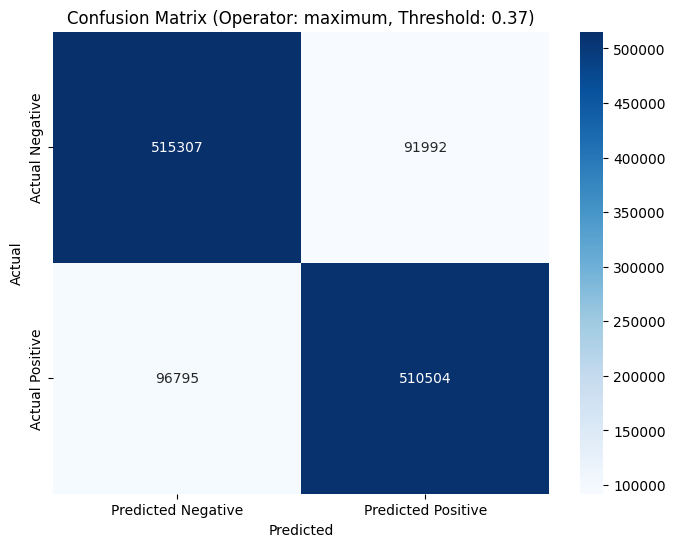


--- Analyzing cosine ---

Top 100 App-App Pairs by cosine_jan Similarity:
Chrome Browser  - Google Play: 0.0156
Gmail - Google Play services: 0.0156
Gmail - Google Search: 0.0156
Google Play services - Google Search: 0.0156
Google Play - Google Play services: 0.0156
Google Search - YouTube: 0.0156
Facebook - Facebook Messenger: 0.0156
Android System - Permission controller: 0.0156
Google Play - Settings: 0.0156
Chrome Browser  - Settings: 0.0156
Facebook - YouTube: 0.0156
Gmail - YouTube: 0.0156
Gmail - Google Play: 0.0156
Android System - Package installer: 0.0156
Clock by Samsung Electronics Co.,  Ltd. - Samsung Gallery: 0.0156
Samsung Calendar - Samsung Gallery: 0.0156
Clock by Samsung Electronics Co.,  Ltd. - Samsung Calendar: 0.0156
Clock by Samsung Electronics Co.,  Ltd. - Samsung Calculator: 0.0156
Call - Samsung Gallery: 0.0156
Package installer - Permission controller: 0.0156
Chrome Browser  - Google Play services: 0.0156
Android System - Gmail: 0.0156
Google Play services - 

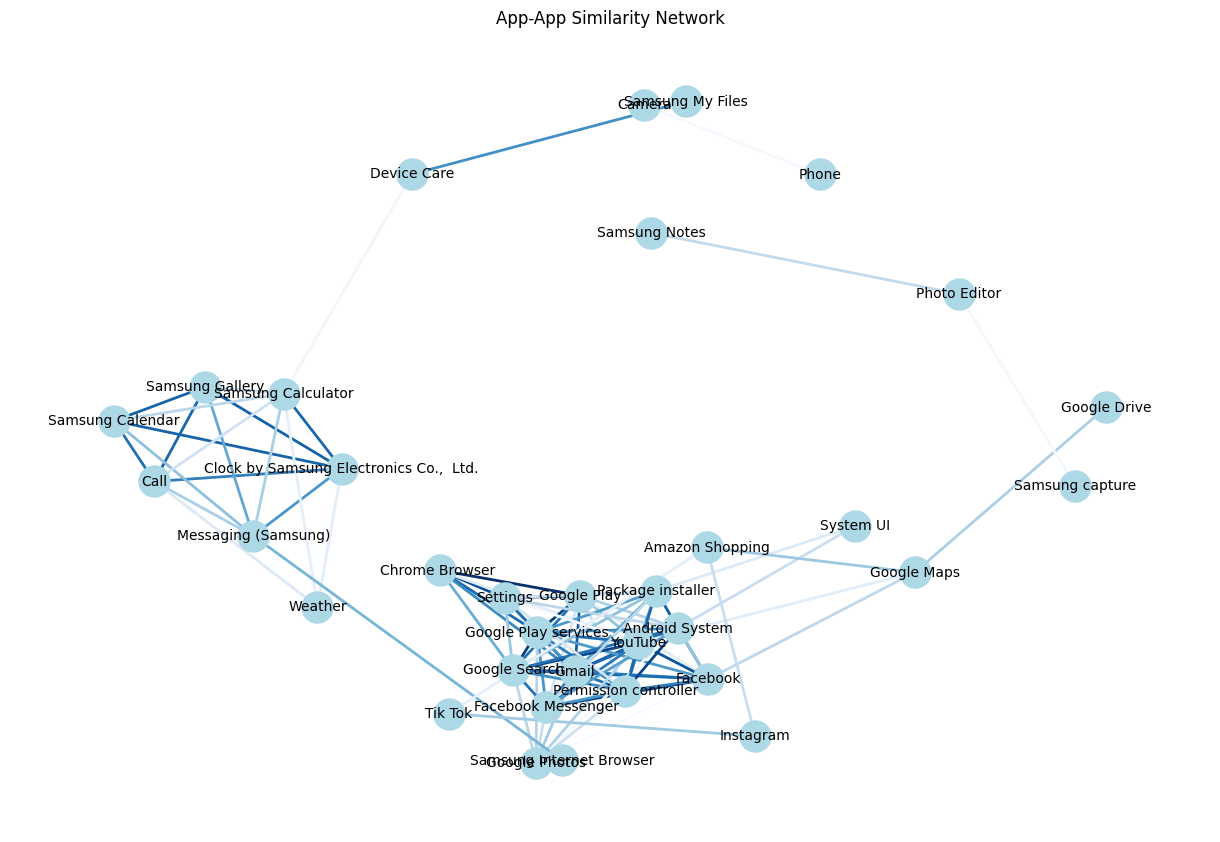


--- Analyzing l1 ---

Top 100 App-App Pairs by l1_jan Distance:
Appel - MÃ©tÃ©o: 3.6306
Chrome Browser  - Google Play: 3.8654
ContrÃ´leur d'autorisations - ParamÃ¨tres: 3.9575
Google Play services - Google Search: 4.0650
Appareil photo - SystÃ¨me Android: 4.0899
Parking Puzzle Space - Turbo Highway Race: 4.1086
Calm Baby - Reef: 4.1109
Appel - ParamÃ¨tres: 4.1258
ContrÃ´leur d'autorisations - TÃ©lÃ©phone: 4.2291
HappiLit - eReader: 4.4448
Appel - ContrÃ´leur d'autorisations: 4.4728
ParamÃ¨tres - TÃ©lÃ©phone: 4.4794
Color Cascade Challenge - ZenPin: 4.4896
Sea Treasure - Tricky Letters Find Words: 4.6097
SystÃ¨me Android - TÃ©lÃ©phone: 4.6119
Jigsaw To Pictures - Tricky Letters Find Words: 4.6470
Appareil photo - ParamÃ¨tres: 4.6545
T - tT|: 4.6622
5Ã - Ã¸:: 4.6736
ColorShift - ZenPin: 4.6936
Reef - WMKV 89.3 FM: 4.7038
ContrÃ´leur d'autorisations - MÃ©tÃ©o: 4.7179
MÃ©tÃ©o - ParamÃ¨tres: 4.7202
CPÂ§6h - Â¾n: 4.7284
Color Cascade Challenge - Jigsaw To Pictures: 4.7300
Jigsaw To Pictur

/Users/xinyi/Library/Python/3.12/lib/python/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 4 () missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/Users/xinyi/Library/Python/3.12/lib/python/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 157 (\x9d) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/Users/xinyi/Library/Python/3.12/lib/python/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 159 (\x9f) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/Users/xinyi/Library/Python/3.12/lib/python/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 140 (\x8c) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/Users/xinyi/Library/Python/3.12/lib/python/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 0 ( ) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/Users/xinyi/Library/Python/3.

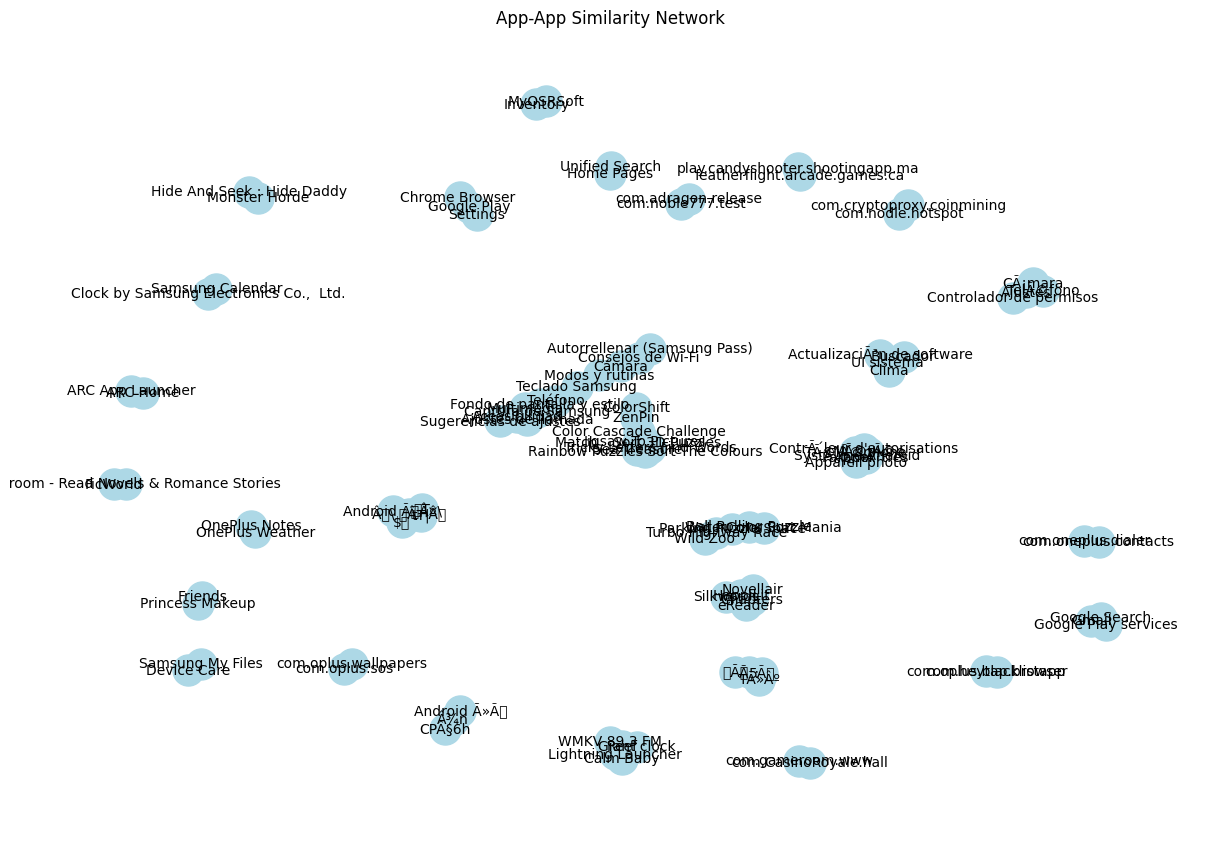


--- Analyzing exp_diff ---

Top 100 App-App Pairs by exp_diff_jan Similarity:
Appel - MÃ©tÃ©o: 0.9460
Chrome Browser  - Google Play: 0.9427
ContrÃ´leur d'autorisations - ParamÃ¨tres: 0.9411
Google Play services - Google Search: 0.9395
Calm Baby - Reef: 0.9393
Appareil photo - SystÃ¨me Android: 0.9392
Parking Puzzle Space - Turbo Highway Race: 0.9391
Appel - ParamÃ¨tres: 0.9383
ContrÃ´leur d'autorisations - TÃ©lÃ©phone: 0.9375
HappiLit - eReader: 0.9344
Appel - ContrÃ´leur d'autorisations: 0.9340
ParamÃ¨tres - TÃ©lÃ©phone: 0.9340
Color Cascade Challenge - ZenPin: 0.9337
Gmail - Google Play services: 0.9331
Sea Treasure - Tricky Letters Find Words: 0.9318
SystÃ¨me Android - TÃ©lÃ©phone: 0.9318
Jigsaw To Pictures - Tricky Letters Find Words: 0.9317
T - tT|: 0.9314
Appareil photo - ParamÃ¨tres: 0.9313
5Ã - Ã¸:: 0.9310
ColorShift - ZenPin: 0.9307
Reef - WMKV 89.3 FM: 0.9307
Jigsaw To Pictures - Sea Treasure: 0.9304
Match _ Sort 3D Puzzles - Sea Treasure: 0.9304
ContrÃ´leur d'autorisation

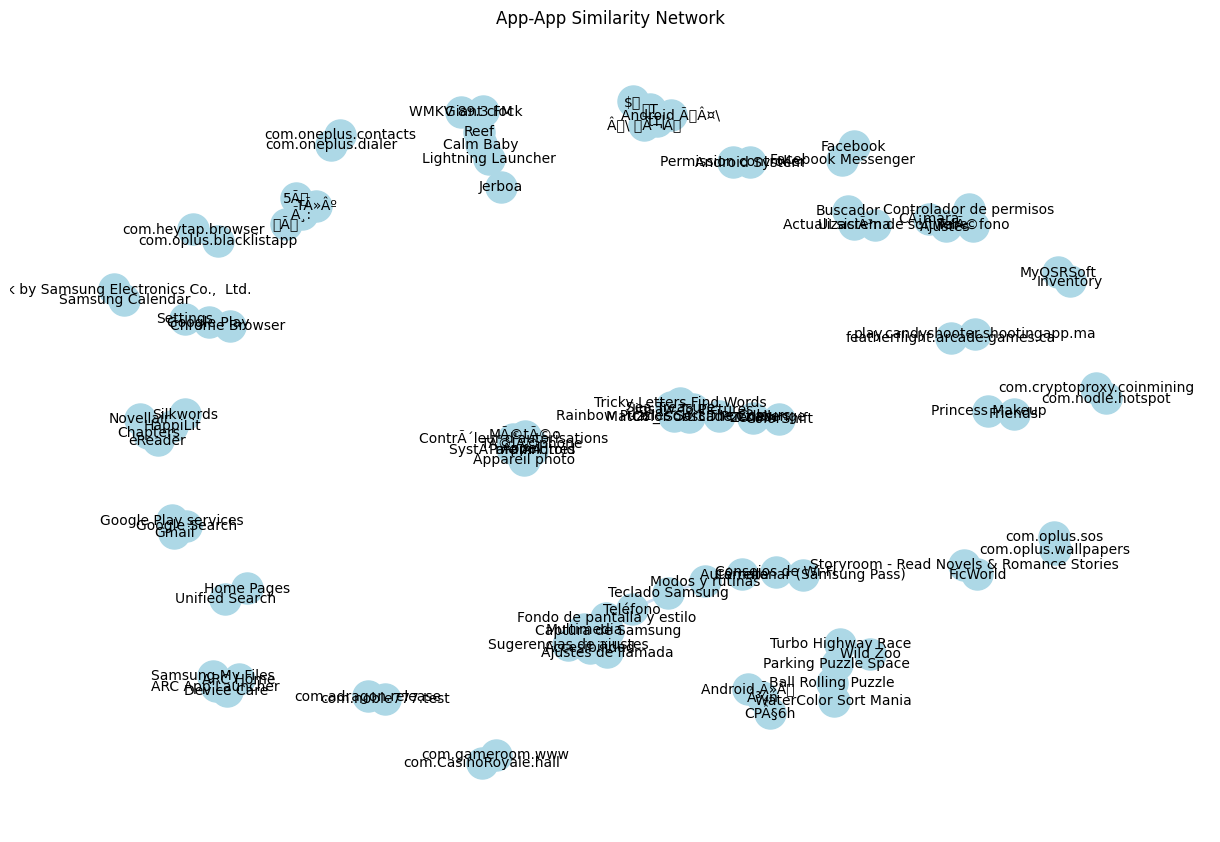

User - 2 clusters: Silhouette Score = 0.9671
User - 3 clusters: Silhouette Score = 0.0562
User - 4 clusters: Silhouette Score = 0.0588
User - 5 clusters: Silhouette Score = 0.0559
User - 6 clusters: Silhouette Score = 0.0574
User - 7 clusters: Silhouette Score = 0.0239
User - 8 clusters: Silhouette Score = 0.0559
User - 9 clusters: Silhouette Score = 0.0582
User - 10 clusters: Silhouette Score = 0.0224
Best number of User clusters: 2
App - 2 clusters: Silhouette Score = 0.9379
App - 3 clusters: Silhouette Score = 0.8907
App - 4 clusters: Silhouette Score = 0.3976
App - 5 clusters: Silhouette Score = 0.3521
App - 6 clusters: Silhouette Score = 0.3508
App - 7 clusters: Silhouette Score = 0.1626
App - 8 clusters: Silhouette Score = 0.0355
App - 9 clusters: Silhouette Score = 0.0348
App - 10 clusters: Silhouette Score = 0.0302
Best number of App clusters: 2


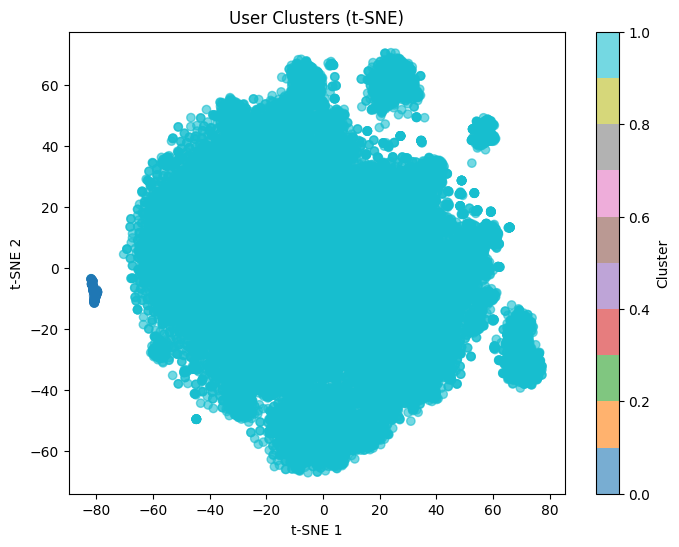

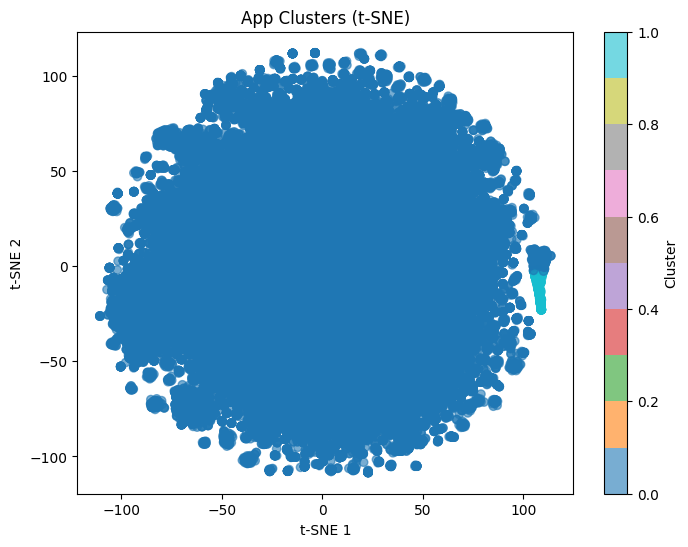


Recommended apps for user GWSPanel0000E427A0144EEC: ['win.free.gift.cards.make.money.cash.game.v6', 'com.modmeplay.a9minispycameraappguide', 'free.qr.code.reader.barcode.scanner.v3', 'org.codeaurora.dialer', 'com.tiktaktoolsstudio.mobilehotspot']
Hit rate: 0.0200


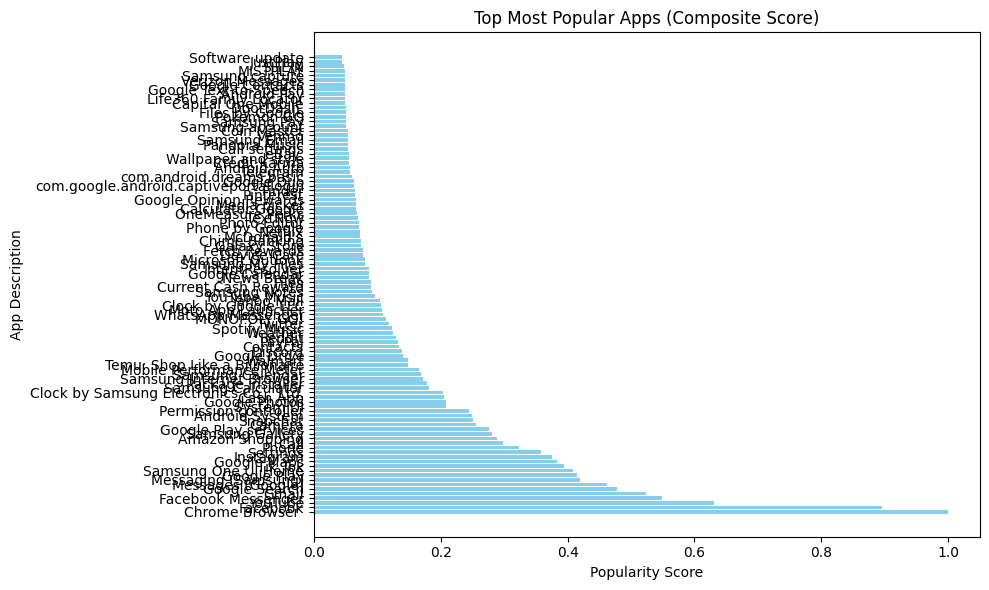


Top {top_k} Most Popular Apps (Composite Score):
        APPDESCRIPTION  PopularityScore
0      Chrome Browser          1.000000
1             Facebook         0.894768
2              YouTube         0.631338
3   Facebook Messenger         0.548109
4                Gmail         0.523248
..                 ...              ...
95     Samsung capture         0.048966
96            MISTPLAY         0.048945
97               SHEIN         0.048202
98            JustPlay         0.045175
99     Software update         0.045024

[100 rows x 2 columns]


In [ ]:
import torch
from torch_geometric.data import HeteroData
from torch_geometric.nn import MetaPath2Vec
import pandas as pd
import numpy as np
import gc
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, roc_auc_score, precision_recall_curve, precision_score, recall_score, f1_score
from sklearn.cluster import KMeans
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
import networkx as nx

# Set random seed for reproducibility
torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed(42)

# Parameters
batch_size_train = 64
batch_size_predict = 500
embedding_dim = 64
epochs = 50
metapaths = [('app', 'uses', 'user'), ('user', 'uses', 'app')]
walk_length = 50
context_size = 5
walks_per_node = 50
num_negative_samples = 10
learning_rate = 0.005

top_k = 100
top_num = 100

# Device setup
device = torch.device('mps' if torch.backends.mps.is_available() else 'cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

# Load data
def load_data():
    try:
        df_jan_full = pd.read_parquet('jan_aggregated.parquet')
        df_feb_full = pd.read_parquet('feb_aggregated.parquet')
        mappings = torch.load('jan_mappings.pt', weights_only=False)
        user_mapping_jan = mappings['user_mapping_jan']
        app_mapping_jan = mappings['app_mapping_jan']
        print(f"Loaded January data: {df_jan_full.shape}, February data: {df_feb_full.shape}")
        print(f"January mappings: {len(user_mapping_jan)} users, {len(app_mapping_jan)} apps")
        return df_jan_full, df_feb_full, user_mapping_jan, app_mapping_jan
    except Exception as e:
        print(f"Error loading data: {e}")
        raise

# Build January graph
def build_january_graph(df_jan_full):
    data_jan = HeteroData()
    unique_users_jan = df_jan_full['PANELISTID'].unique()
    unique_apps_jan = df_jan_full['APPDESCRIPTION'].unique()
    data_jan['user'].num_nodes = len(unique_users_jan)
    data_jan['app'].num_nodes = len(unique_apps_jan)
    user_mapping_jan = {user_id: idx for idx, user_id in enumerate(unique_users_jan)}
    app_mapping_jan = {app_id: idx for idx, app_id in enumerate(unique_apps_jan)}
    
    source_jan = df_jan_full['PANELISTID'].map(user_mapping_jan)
    target_jan = df_jan_full['APPDESCRIPTION'].map(app_mapping_jan)
    if source_jan.isnull().any() or target_jan.isnull().any():
        raise ValueError("NaN values in January edge indices")
    
    edge_indices = np.vstack([source_jan.values, target_jan.values])
    edge_index_jan = torch.tensor(edge_indices, dtype=torch.long)
    edge_indices_reverse = np.vstack([target_jan.values, source_jan.values])
    edge_index_jan_reverse = torch.tensor(edge_indices_reverse, dtype=torch.long)
    data_jan['user', 'uses', 'app'].edge_index = edge_index_jan
    data_jan['app', 'uses', 'user'].edge_index = edge_index_jan_reverse
    print(f"January graph: users={data_jan['user'].num_nodes}, apps={data_jan['app'].num_nodes}")
    return data_jan, user_mapping_jan, app_mapping_jan, unique_users_jan, unique_apps_jan

# Build February graph
def build_february_graph(df_feb_full):
    data_feb = HeteroData()
    unique_users_feb = df_feb_full['PANELISTID'].unique()
    unique_apps_feb = df_feb_full['APPDESCRIPTION'].unique()
    data_feb['user'].num_nodes = len(unique_users_feb)
    data_feb['app'].num_nodes = len(unique_apps_feb)
    user_mapping_feb = {user_id: idx for idx, user_id in enumerate(unique_users_feb)}
    app_mapping_feb = {app_id: idx for idx, app_id in enumerate(unique_apps_feb)}
    
    source_feb = df_feb_full['PANELISTID'].map(user_mapping_feb)
    target_feb = df_feb_full['APPDESCRIPTION'].map(app_mapping_feb)
    if source_feb.isnull().any() or target_feb.isnull().any():
        raise ValueError("NaN values in February edge indices")
    
    edge_indices = np.vstack([source_feb.values, target_feb.values])
    edge_index_feb = torch.tensor(edge_indices, dtype=torch.long)
    data_feb['user', 'uses', 'app'].edge_index = edge_index_feb
    print(f"February graph: users={data_feb['user'].num_nodes}, apps={data_feb['app'].num_nodes}")
    return data_feb, user_mapping_feb, app_mapping_feb, unique_users_feb, unique_apps_feb

# Initialize February embeddings
def initialize_feb_embeddings(unique_entities_feb, entity_mapping_jan, embeddings_jan, embedding_dim, method='mean'):
    embeddings_feb = np.zeros((len(unique_entities_feb), embedding_dim), dtype=np.float32)
    mean_embedding = np.mean(embeddings_jan, axis=0) if method == 'mean' else None
    for i, entity in enumerate(unique_entities_feb):
        if entity in entity_mapping_jan:
            embeddings_feb[i] = embeddings_jan[entity_mapping_jan[entity]]
        else:
            embeddings_feb[i] = mean_embedding if method == 'mean' else np.random.normal(0, 0.01, embedding_dim)
    return embeddings_feb

# Binary operators for edge features and app-app similarity
def hadamard(u, v): return u * v
def l1(u, v): return np.abs(u - v)
def l2(u, v): return (u - v) ** 2
def average(u, v): return (u + v) / 2
def cosine(u, v):
    norm_u = np.linalg.norm(u)
    norm_v = np.linalg.norm(v)
    norm_u = 1e-10 if norm_u == 0 else norm_u
    norm_v = 1e-10 if norm_v == 0 else norm_v
    return (u * v) / (norm_u * norm_v)
def weighted_sum(u, v, w1=0.6, w2=0.4): return w1 * u + w2 * v
def maximum(u, v): return np.maximum(u, v)
def minimum(u, v): return np.minimum(u, v)
def exp_diff(u, v): return np.exp(-np.abs(u - v))

# Compute edge features
def compute_edge_features(user_emb, app_emb, edge_indices, binary_op):
    user_indices, app_indices = edge_indices
    return np.array([binary_op(user_emb[u], app_emb[a]) for u, a in zip(user_indices, app_indices)], dtype=np.float32)

# Compute app-app similarity
def compute_app_app_similarity(app_embeddings, app_mapping, binary_op, op_name, df, top_k, is_distance=False):
    num_apps = app_embeddings.shape[0]
    app_ids = list(app_mapping.keys())
    
    scores = np.zeros((num_apps, num_apps), dtype=np.float32)
    for i in range(num_apps):
        for j in range(i + 1, num_apps):
            score_vec = binary_op(app_embeddings[i], app_embeddings[j])
            score = np.mean(score_vec) if not is_distance else np.sum(score_vec)
            scores[i, j] = score
            scores[j, i] = score
    
    indices = np.triu_indices(num_apps, k=1)
    scores_flat = scores[indices]
    top_indices = np.argsort(scores_flat)[::-1][:top_k] if not is_distance else np.argsort(scores_flat)[:top_k]
    top_pairs = [(indices[0][idx], indices[1][idx]) for idx in top_indices]
    
    top_pairs_with_scores = [
        (app_ids[i], app_ids[j], scores[i, j])
        for i, j in top_pairs
    ]
    
    print(f"\nTop {top_k} App-App Pairs by {op_name} {'Similarity' if not is_distance else 'Distance'}:")
    for app1, app2, score in top_pairs_with_scores:
        print(f"{app1} - {app2}: {score:.4f}")
    
    return top_pairs_with_scores

# Validate app-app similarity using February data
def validate_app_pairs(top_pairs, df_feb, app_mapping):
    print("\nValidation of Top App Pairs with February Data:")
    for app1, app2, score in top_pairs:
        app1_idx = app_mapping[app1]
        app2_idx = app_mapping[app2]
        users_app1 = set(df_feb[df_feb['APPDESCRIPTION'] == app1]['PANELISTID'].unique())
        users_app2 = set(df_feb[df_feb['APPDESCRIPTION'] == app2]['PANELISTID'].unique())
        common_users = len(users_app1.intersection(users_app2))
        total_users = len(users_app1.union(users_app2))
        jaccard = common_users / total_users if total_users > 0 else 0
        print(f"{app1} - {app2}: Jaccard Similarity eukaryote Overlap) = {jaccard:.4f}")

# Compare app-app similarity across months
def compare_temporal_similarity(top_pairs_jan, top_pairs_feb):
    print("\nTemporal Consistency Analysis of App-App Similarity:")
    pairs_jan = {(app1, app2) for app1, app2, _ in top_pairs_jan}
    pairs_feb = {(app1, app2) for app1, app2, _ in top_pairs_feb}
    common_pairs = pairs_jan.intersection(pairs_feb)
    consistency_ratio = len(common_pairs) / len(pairs_jan) if len(pairs_jan) > 0 else 0
    print(f"Number of common app-app pairs between January and February: {len(common_pairs)}")
    print(f"Consistency ratio: {consistency_ratio:.4f}")
    for app1, app2 in common_pairs:
        score_jan = next(score for a1, a2, score in top_pairs_jan if (a1, a2) == (app1, app2))
        score_feb = next(score for a1, a2, score in top_pairs_feb if (a1, a2) == (app1, app2))
        print(f"{app1} - {app2}: January Score = {score_jan:.4f}, February Score = {score_feb:.4f}")

# Compute app-app similarity within clusters
#def compute_similarity_within_clusters(app_embeddings, app_mapping, app_clusters, n_clusters, binary_op, op_name, df, top_k, is_distance=False):
#    app_ids = list(app_mapping.keys())
#    for cluster_id in range(n_clusters):
#        cluster_indices = np.where(app_clusters == cluster_id)[0]
#        if len(cluster_indices) < 2:
#            print(f"Cluster {cluster_id} has fewer than 2 apps, skipping.")
#            continue
#        cluster_embeddings = app_embeddings[cluster_indices]
#        cluster_mapping = {app_ids[idx]: i for i, idx in enumerate#(cluster_indices)}
#        print(f"\nComputing similarity for Cluster {cluster_id} ({len(cluster_indices)} apps):")
#        compute_app_app_similarity(cluster_embeddings, cluster_mapping, binary_op, f"{op_name}_cluster_{cluster_id}", df, top_k=top_k, is_distance=is_distance)

# Visualize app-app similarity network
def visualize_app_similarity_network(top_pairs, filename="app_similarity_network.png"):
    G = nx.Graph()
    for app1, app2, score in top_pairs:
        G.add_edge(app1, app2, weight=score)
    
    plt.figure(figsize=(12, 8))
    pos = nx.spring_layout(G)
    edges = G.edges(data=True)
    weights = [edge[2]['weight'] for edge in edges]
    nx.draw(G, pos, with_labels=True, node_color='lightblue', node_size=500, font_size=10, edge_color=weights, edge_cmap=plt.cm.Blues, width=2)
    plt.title("App-App Similarity Network")
    plt.show()
    plt.close()

# Train and evaluate classifier
def train_classifier(X, y, X_val, y_val, binary_op_name, scaler=None):
    if scaler:
        X_scaled = scaler.fit_transform(X)
        X_val_scaled = scaler.transform(X_val)
    else:
        X_scaled, X_val_scaled = X, X_val
    
    clf = LogisticRegression(max_iter=1000, class_weight='balanced')
    clf.fit(X_scaled, y)
    
    pred_probs = clf.predict_proba(X_val_scaled)[:, 1]
    roc_auc = roc_auc_score(y_val, pred_probs)
    
    prec, rec, thresholds = precision_recall_curve(y_val, pred_probs)
    f1_scores = 2 * (prec * rec) / (prec + rec + 1e-10)
    best_threshold = thresholds[np.argmax(f1_scores)]
    pred_labels = (pred_probs > best_threshold).astype(np.int8)
    
    precision = precision_score(y_val, pred_labels)
    recall = recall_score(y_val, pred_labels)
    f1 = f1_score(y_val, pred_labels)
    
    return clf, scaler, roc_auc, precision, recall, f1, best_threshold, pred_labels, pred_probs

# Cluster and evaluate
def cluster_and_evaluate(embeddings, name, max_clusters=10):
    silhouette_scores = []
    cluster_labels = []
    for n_clusters in range(2, max_clusters + 1):
        kmeans = KMeans(n_clusters=n_clusters, random_state=42)
        labels = kmeans.fit_predict(embeddings)
        score = silhouette_score(embeddings, labels)
        silhouette_scores.append(score)
        cluster_labels.append(labels)
        print(f"{name} - {n_clusters} clusters: Silhouette Score = {score:.4f}")
    
    best_n_clusters = np.argmax(silhouette_scores) + 2
    best_labels = cluster_labels[best_n_clusters - 2]
    print(f"Best number of {name} clusters: {best_n_clusters}")
    return best_labels, best_n_clusters

# Visualize clusters
def visualize_clusters(embeddings, labels, name):
    tsne = TSNE(n_components=2, random_state=42, n_jobs=-1)
    embeddings_2d = tsne.fit_transform(embeddings)
    
    plt.figure(figsize=(8, 6))
    scatter = plt.scatter(embeddings_2d[:, 0], embeddings_2d[:, 1], c=labels, cmap='tab10', alpha=0.6)
    plt.title(f'{name} Clusters (t-SNE)')
    plt.colorbar(scatter, label='Cluster')
    plt.xlabel('t-SNE 1')
    plt.ylabel('t-SNE 2')
    plt.show()
    plt.close()

# Recommend apps
def recommend_apps(user_id, user_embeddings, app_embeddings, user_mapping, app_mapping, user_clusters, df_feb, top_n=5):
    if user_id not in user_mapping:
        print(f"User {user_id} not found in January data.")
        return [], 0.0
    
    user_idx = user_mapping[user_id]
    user_emb = user_embeddings[user_idx]
    user_cluster = user_clusters[user_idx]
    
    cluster_users = np.where(user_clusters == user_cluster)[0]
    cluster_user_ids = [list(user_mapping.keys())[list(user_mapping.values()).index(idx)] for idx in cluster_users]
    cluster_apps = df_feb[df_feb['PANELISTID'].isin(cluster_user_ids)]['APPDESCRIPTION'].value_counts().head(top_num).index
    
    user_norm = np.linalg.norm(user_emb)
    app_norms = np.linalg.norm(app_embeddings, axis=1)
    app_norms[app_norms == 0] = 1e-10
    similarities = np.dot(app_embeddings, user_emb) / (user_norm * app_norms)
    
    app_indices = [app_mapping[app] for app in cluster_apps if app in app_mapping]
    similarities[app_indices] *= 1.2
    
    top_indices = np.argsort(similarities)[-top_n:][::-1]
    recommended_apps = [list(app_mapping.keys())[list(app_mapping.values()).index(idx)] for idx in top_indices]
    
    user_feb_apps = df_feb[df_feb['PANELISTID'] == user_id]['APPDESCRIPTION'].unique()
    hits = sum(app in user_feb_apps for app in recommended_apps)
    hit_rate = hits / top_num if top_n > 0 else 0
    return recommended_apps, hit_rate

# Analyze popular apps
def analyze_popular_apps(df_feb):
    duration = df_feb.groupby('APPDESCRIPTION')['weight'].sum()
    user_count = df_feb.groupby('APPDESCRIPTION')['PANELISTID'].nunique()
    # Convert to float to handle Decimal types
    duration = duration.astype(float)
    user_count = user_count.astype(float)
    duration_norm = (duration - duration.min()) / (duration.max() - duration.min() + 1e-10)
    user_count_norm = (user_count - user_count.min()) / (user_count.max() - user_count.min() + 1e-10)
    popularity_score = 0.7 * duration_norm + 0.3 * user_count_norm
    
    top_apps = popularity_score.sort_values(ascending=False).head(top_num).reset_index()
    top_apps.columns = ['APPDESCRIPTION', 'PopularityScore']
    
    plt.figure(figsize=(10, 6))
    plt.barh(top_apps['APPDESCRIPTION'], top_apps['PopularityScore'], color='skyblue')
    plt.title('Top Most Popular Apps (Composite Score)')
    plt.xlabel('Popularity Score')
    plt.ylabel('App Description')
    plt.tight_layout()
    plt.show()
    plt.close()
    
    return top_apps

# Main workflow
def main():
    if device.type == 'cuda':
        torch.cuda.empty_cache()
    elif device.type == 'mps':
        torch.mps.empty_cache()
    gc.collect()

    df_jan_full, df_feb_full, user_mapping_jan, app_mapping_jan = load_data()
    
    data_jan, user_mapping_jan, app_mapping_jan, unique_users_jan, unique_apps_jan = build_january_graph(df_jan_full)
    data_feb, user_mapping_feb, app_mapping_feb, unique_users_feb, unique_apps_feb = build_february_graph(df_feb_full)
    
    try:
        data_jan = data_jan.to(device)
        model = MetaPath2Vec(
            edge_index_dict=data_jan.edge_index_dict,
            embedding_dim=embedding_dim,
            metapath=metapaths,
            walk_length=walk_length,
            context_size=context_size,
            walks_per_node=walks_per_node,
            num_negative_samples=num_negative_samples
        ).to(device)
    except RuntimeError as e:
        print(f"Failed to allocate to {device}: {e}. Falling back to CPU.")
        data_jan = data_jan.to('cpu')
        model = MetaPath2Vec(
            edge_index_dict=data_jan.edge_index_dict,
            embedding_dim=embedding_dim,
            metapath=metapaths,
            walk_length=walk_length,
            context_size=context_size,
            walks_per_node=walks_per_node,
            num_negative_samples=num_negative_samples
        ).to('cpu')
    
    # Load pre-trained model
    model_path = "metapath2vec_january.pth"
    try:
        checkpoint = torch.load(model_path, map_location=device, weights_only=False)
        model.load_state_dict(checkpoint['model_state_dict'])
        print(f"Loaded pre-trained model from {model_path}")
    except Exception as e:
        print(f"Error loading model from {model_path}: {e}")
        raise
    
    user_embeddings_jan = model('user').detach().cpu().numpy()
    app_embeddings_jan = model('app').detach().cpu().numpy()
    print(f"January user embeddings shape: {user_embeddings_jan.shape}")
    print(f"January app embeddings shape: {app_embeddings_jan.shape}")
    
    app_usage = df_jan_full.groupby('APPDESCRIPTION')['weight'].sum()
    app_user_count = df_jan_full.groupby('APPDESCRIPTION')['PANELISTID'].nunique()
    min_duration = app_usage.quantile(0.1, interpolation='nearest')
    min_users = 5
    popular_apps = app_usage[(app_usage > min_duration) & (app_user_count > min_users)].index
    app_indices = [app_mapping_jan[app] for app in popular_apps if app in app_mapping_jan]
    filtered_app_embeddings_jan = app_embeddings_jan[app_indices]
    filtered_app_mapping_jan = {app: idx for idx, app in enumerate(popular_apps)}
    print(f"Filtered to {len(popular_apps)} popular apps for similarity computation (January)")
    
    user_embeddings_feb = initialize_feb_embeddings(unique_users_feb, user_mapping_jan, user_embeddings_jan, embedding_dim, method='mean')
    app_embeddings_feb = initialize_feb_embeddings(unique_apps_feb, app_mapping_jan, app_embeddings_jan, embedding_dim, method='mean')
    
    app_usage_feb = df_feb_full.groupby('APPDESCRIPTION')['weight'].sum()
    app_user_count_feb = df_feb_full.groupby('APPDESCRIPTION')['PANELISTID'].nunique()
    min_duration_feb = app_usage_feb.quantile(0.1,interpolation='nearest')
    popular_apps_feb = app_usage_feb[(app_usage_feb > min_duration_feb) & (app_user_count_feb > min_users)].index
    app_indices_feb = [app_mapping_feb[app] for app in popular_apps_feb if app in app_mapping_feb]
    filtered_app_embeddings_feb = app_embeddings_feb[app_indices_feb]
    filtered_app_mapping_feb = {app: idx for idx, app in enumerate(popular_apps_feb)}
    print(f"Filtered to {len(popular_apps_feb)} popular apps for similarity computation (February)")

    # Link prediction withlot classifier
    true_edge_indices = data_feb['user', 'uses', 'app'].edge_index.cpu().numpy()
    true_indices_train, true_indices_val = train_test_split(np.arange(true_edge_indices.shape[1]), train_size=0.75, random_state=42)
    
    similarity = user_embeddings_feb @ app_embeddings_feb.T
    neg_indices = np.where(similarity > np.percentile(similarity, 90))
    neg_indices = np.array([neg_indices[0][:len(true_edge_indices[0])], neg_indices[1][:len(true_edge_indices[0])]])
    neg_indices_train, neg_indices_val = train_test_split(np.arange(neg_indices.shape[1]), train_size=0.75, random_state=42)
    
    binary_operators = {
        'hadamard': hadamard,
        'l1': l1,
        'l2': l2,
        'average': average,
        'cosine': cosine,
        'weighted_sum': weighted_sum,
        'maximum': maximum,
        'minimum': minimum,
        'exp_diff': exp_diff
    }
    
    best_clf, best_scaler, best_op, best_score, best_threshold, best_cm = None, None, None, 0, 0.5, None
    for op_name, op in binary_operators.items():
        true_features_train = compute_edge_features(user_embeddings_feb, app_embeddings_feb, [true_edge_indices[0][true_indices_train], true_edge_indices[1][true_indices_train]], op)
        neg_features_train = compute_edge_features(user_embeddings_feb, app_embeddings_feb, [neg_indices[0][neg_indices_train], neg_indices[1][neg_indices_train]], op)
        true_features_val = compute_edge_features(user_embeddings_feb, app_embeddings_feb, [true_edge_indices[0][true_indices_val], true_edge_indices[1][true_indices_val]], op)
        neg_features_val = compute_edge_features(user_embeddings_feb, app_embeddings_feb, [neg_indices[0][neg_indices_val], neg_indices[1][neg_indices_val]], op)
        
        X_train = np.vstack([true_features_train, neg_features_train])
        y_train = np.concatenate([np.ones(len(true_features_train)), np.zeros(len(neg_features_train))])
        X_val = np.vstack([true_features_val, neg_features_val])
        y_val = np.concatenate([np.ones(len(true_features_val)), np.zeros(len(neg_features_val))])
        
        scaler = StandardScaler()
        clf, scaler, roc_auc, precision, recall, f1, thresh, pred_labels, pred_probs = train_classifier(X_train, y_train, X_val, y_val, op_name, scaler)
        cm = confusion_matrix(y_val, pred_labels)
        print(f"Operator: {op_name}, ROC-AUC: {roc_auc:.4f}, Precision: {precision:.4f}, Recall: {recall:.4f}, F1: {f1:.4f}, Threshold: {thresh:.4f}")
        
        if roc_auc > best_score:
            best_clf, best_scaler, best_op, best_score, best_threshold, best_cm = clf, scaler, op, roc_auc, thresh, cm
    
    plt.figure(figsize=(8, 6))
    sns.heatmap(best_cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Predicted Negative', 'Predicted Positive'], yticklabels=['Actual Negative', 'Actual Positive'])
    plt.title(f'Confusion Matrix (Operator: {best_op.__name__}, Threshold: {best_threshold:.2f})')
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.show()
    
    similarity_ops = [
        ('cosine', cosine, False),
        ('l1', l1, True),
        ('exp_diff', exp_diff, False)
    ]
    
    # Temporal consistency analysis
    for op_name, op, is_distance in similarity_ops:
        print(f"\n--- Analyzing {op_name} ---")
        top_pairs_jan = compute_app_app_similarity(filtered_app_embeddings_jan, filtered_app_mapping_jan, op, f"{op_name}_jan", df_jan_full, top_k, is_distance=is_distance)
        validate_app_pairs(top_pairs_jan, df_feb_full, filtered_app_mapping_jan)
        top_pairs_feb = compute_app_app_similarity(filtered_app_embeddings_feb, filtered_app_mapping_feb, op, f"{op_name}_feb", df_feb_full, top_k, is_distance=is_distance)
        compare_temporal_similarity(top_pairs_jan, top_pairs_feb)
        visualize_app_similarity_network(top_pairs_jan, f"app_similarity_network_{op_name}_jan.png")
    
    # Clustering
    user_clusters, user_n_clusters = cluster_and_evaluate(user_embeddings_jan, "User")
    app_clusters, app_n_clusters = cluster_and_evaluate(app_embeddings_jan, "App")
    visualize_clusters(user_embeddings_jan, user_clusters, "User")
    visualize_clusters(app_embeddings_jan, app_clusters, "App")
    
    # Cluster-based similarity
    #for op_name, op, is_distance in similarity_ops:
    #    compute_similarity_within_clusters(app_embeddings_jan, app_mapping_jan, app_clusters, app_n_clusters, op, op_name, df_jan_full, top_k, is_distance=is_distance)
    
    sample_user_id = unique_users_jan[0]
    recommended_apps, hit_rate = recommend_apps(sample_user_id, user_embeddings_jan, app_embeddings_jan, user_mapping_jan, app_mapping_jan, user_clusters, df_feb_full)
    print(f"\nRecommended apps for user {sample_user_id}: {recommended_apps}")
    print(f"Hit rate: {hit_rate:.4f}")
    
    top_apps = analyze_popular_apps(df_feb_full)
    print("\nTop {top_num} Most Popular Apps (Composite Score):")
    print(top_apps)

if __name__ == "__main__":
    main()

Using device: mps
Loaded January data: (2210089, 3), February data: (2429195, 3)
January mappings: 34639 users, 74754 apps
January graph: users=34639, apps=74754
February graph: users=40001, apps=80277
Loaded pre-trained model from metapath2vec_january.pth
January user embeddings shape: (34639, 64)
January app embeddings shape: (74754, 64)
Filtered to 14349 popular apps for similarity computation (January)
Filtered to 14959 popular apps for similarity computation (February)
Operator: hadamard, ROC-AUC: 0.8861, Precision: 0.9024, Recall: 0.7838, F1: 0.8389, Threshold: 0.4424
Operator: l1, ROC-AUC: 0.8902, Precision: 0.9126, Recall: 0.7529, F1: 0.8251, Threshold: 0.3870
Operator: l2, ROC-AUC: 0.8692, Precision: 0.8797, Recall: 0.7583, F1: 0.8145, Threshold: 0.3681
Operator: average, ROC-AUC: 0.9131, Precision: 0.8869, Recall: 0.8020, F1: 0.8423, Threshold: 0.4485
Operator: cosine, ROC-AUC: 0.9105, Precision: 0.8903, Recall: 0.8374, F1: 0.8630, Threshold: 0.4223
Operator: weighted_sum, RO

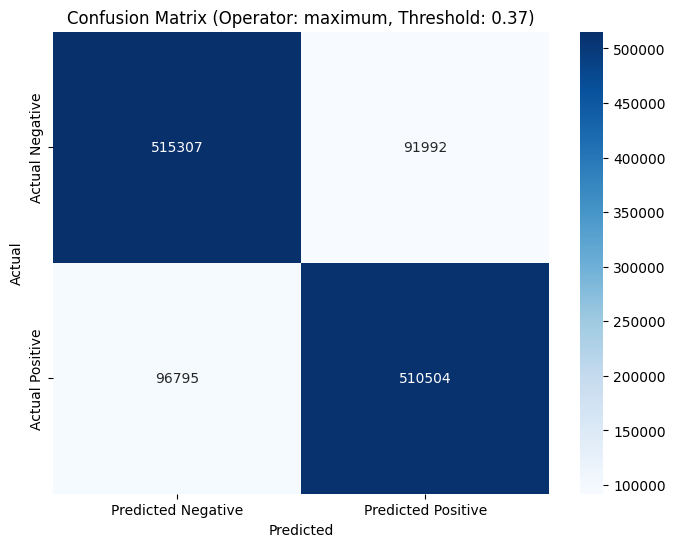


--- Analyzing cosine ---

Top 50 App-App Pairs by cosine_jan Similarity:
Chrome Browser  - Google Play: 0.0156
Gmail - Google Play services: 0.0156
Gmail - Google Search: 0.0156
Google Play services - Google Search: 0.0156
Google Play - Google Play services: 0.0156
Google Search - YouTube: 0.0156
Facebook - Facebook Messenger: 0.0156
Android System - Permission controller: 0.0156
Google Play - Settings: 0.0156
Chrome Browser  - Settings: 0.0156
Facebook - YouTube: 0.0156
Gmail - YouTube: 0.0156
Gmail - Google Play: 0.0156
Android System - Package installer: 0.0156
Clock by Samsung Electronics Co.,  Ltd. - Samsung Gallery: 0.0156
Samsung Calendar - Samsung Gallery: 0.0156
Clock by Samsung Electronics Co.,  Ltd. - Samsung Calendar: 0.0156
Clock by Samsung Electronics Co.,  Ltd. - Samsung Calculator: 0.0156
Call - Samsung Gallery: 0.0156
Package installer - Permission controller: 0.0156
Chrome Browser  - Google Play services: 0.0156
Android System - Gmail: 0.0156
Google Play services - Y

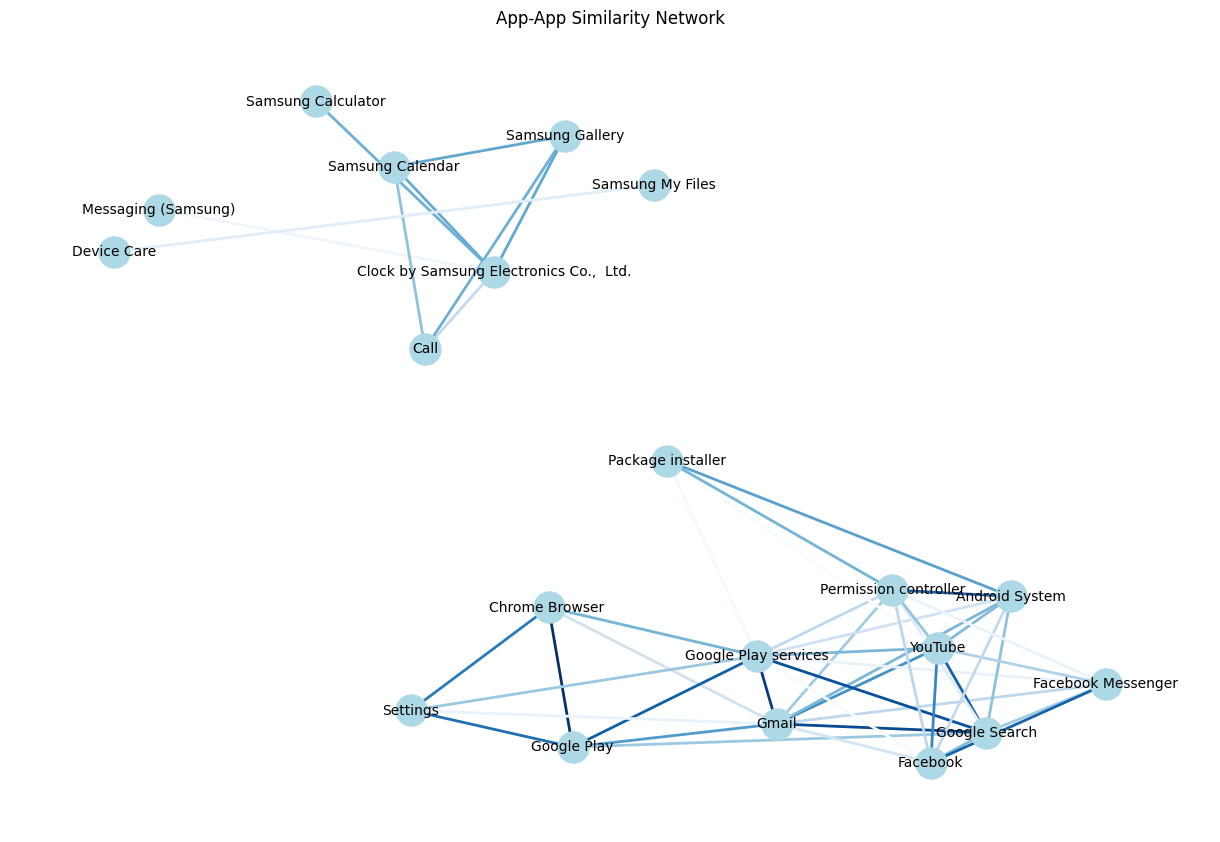


--- Analyzing l1 ---

Top 50 App-App Pairs by l1_jan Distance:
Appel - MÃ©tÃ©o: 3.6306
Chrome Browser  - Google Play: 3.8654
ContrÃ´leur d'autorisations - ParamÃ¨tres: 3.9575
Google Play services - Google Search: 4.0650
Appareil photo - SystÃ¨me Android: 4.0899
Parking Puzzle Space - Turbo Highway Race: 4.1086
Calm Baby - Reef: 4.1109
Appel - ParamÃ¨tres: 4.1258
ContrÃ´leur d'autorisations - TÃ©lÃ©phone: 4.2291
HappiLit - eReader: 4.4448
Appel - ContrÃ´leur d'autorisations: 4.4728
ParamÃ¨tres - TÃ©lÃ©phone: 4.4794
Color Cascade Challenge - ZenPin: 4.4896
Sea Treasure - Tricky Letters Find Words: 4.6097
SystÃ¨me Android - TÃ©lÃ©phone: 4.6119
Jigsaw To Pictures - Tricky Letters Find Words: 4.6470
Appareil photo - ParamÃ¨tres: 4.6545
T - tT|: 4.6622
5Ã - Ã¸:: 4.6736
ColorShift - ZenPin: 4.6936
Reef - WMKV 89.3 FM: 4.7038
ContrÃ´leur d'autorisations - MÃ©tÃ©o: 4.7179
MÃ©tÃ©o - ParamÃ¨tres: 4.7202
CPÂ§6h - Â¾n: 4.7284
Color Cascade Challenge - Jigsaw To Pictures: 4.7300
Jigsaw To Picture

/Users/xinyi/Library/Python/3.12/lib/python/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 4 () missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/Users/xinyi/Library/Python/3.12/lib/python/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 157 (\x9d) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/Users/xinyi/Library/Python/3.12/lib/python/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 159 (\x9f) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/Users/xinyi/Library/Python/3.12/lib/python/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 140 (\x8c) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/Users/xinyi/Library/Python/3.12/lib/python/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 0 ( ) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/Users/xinyi/Library/Python/3.

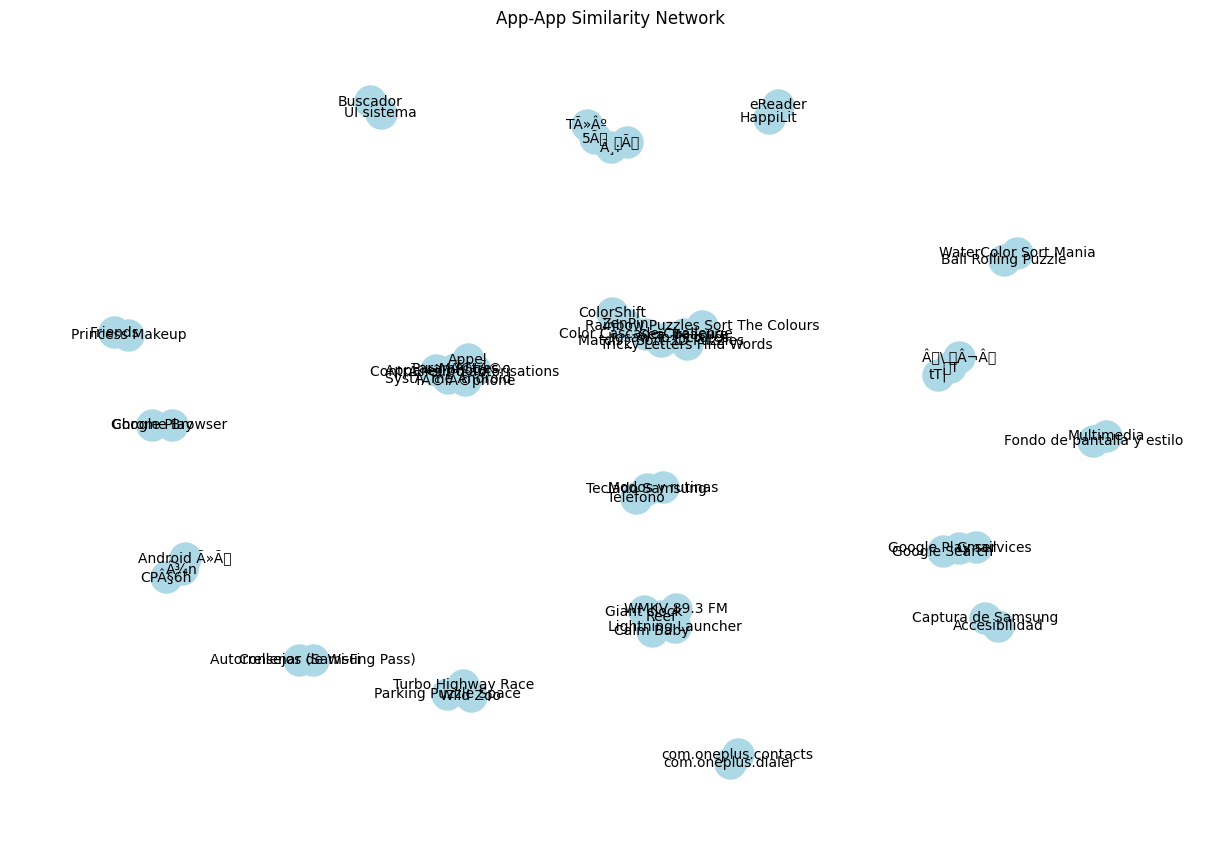


--- Analyzing exp_diff ---

Top 50 App-App Pairs by exp_diff_jan Similarity:
Appel - MÃ©tÃ©o: 0.9460
Chrome Browser  - Google Play: 0.9427
ContrÃ´leur d'autorisations - ParamÃ¨tres: 0.9411
Google Play services - Google Search: 0.9395
Calm Baby - Reef: 0.9393
Appareil photo - SystÃ¨me Android: 0.9392
Parking Puzzle Space - Turbo Highway Race: 0.9391
Appel - ParamÃ¨tres: 0.9383
ContrÃ´leur d'autorisations - TÃ©lÃ©phone: 0.9375
HappiLit - eReader: 0.9344
Appel - ContrÃ´leur d'autorisations: 0.9340
ParamÃ¨tres - TÃ©lÃ©phone: 0.9340
Color Cascade Challenge - ZenPin: 0.9337
Gmail - Google Play services: 0.9331
Sea Treasure - Tricky Letters Find Words: 0.9318
SystÃ¨me Android - TÃ©lÃ©phone: 0.9318
Jigsaw To Pictures - Tricky Letters Find Words: 0.9317
T - tT|: 0.9314
Appareil photo - ParamÃ¨tres: 0.9313
5Ã - Ã¸:: 0.9310
ColorShift - ZenPin: 0.9307
Reef - WMKV 89.3 FM: 0.9307
Jigsaw To Pictures - Sea Treasure: 0.9304
Match _ Sort 3D Puzzles - Sea Treasure: 0.9304
ContrÃ´leur d'autorisations

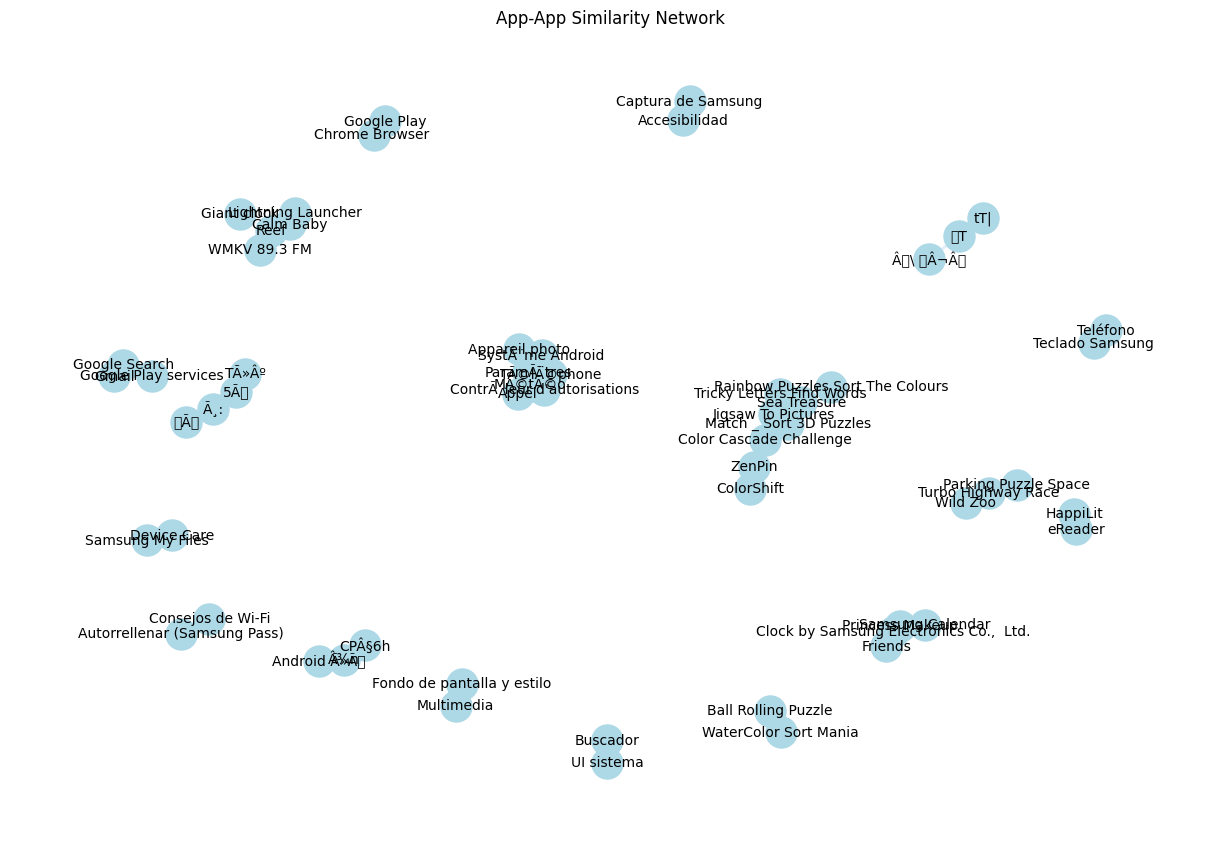

User - 2 clusters: Silhouette Score = 0.9671
User - 3 clusters: Silhouette Score = 0.0562
User - 4 clusters: Silhouette Score = 0.0588
User - 5 clusters: Silhouette Score = 0.0559
User - 6 clusters: Silhouette Score = 0.0574
User - 7 clusters: Silhouette Score = 0.0239
User - 8 clusters: Silhouette Score = 0.0559
User - 9 clusters: Silhouette Score = 0.0582
User - 10 clusters: Silhouette Score = 0.0224
Best number of User clusters: 2
App - 2 clusters: Silhouette Score = 0.9379
App - 3 clusters: Silhouette Score = 0.8907
App - 4 clusters: Silhouette Score = 0.3976
App - 5 clusters: Silhouette Score = 0.3521
App - 6 clusters: Silhouette Score = 0.3508
App - 7 clusters: Silhouette Score = 0.1626
App - 8 clusters: Silhouette Score = 0.0355
App - 9 clusters: Silhouette Score = 0.0351
App - 10 clusters: Silhouette Score = 0.0302
Best number of App clusters: 2


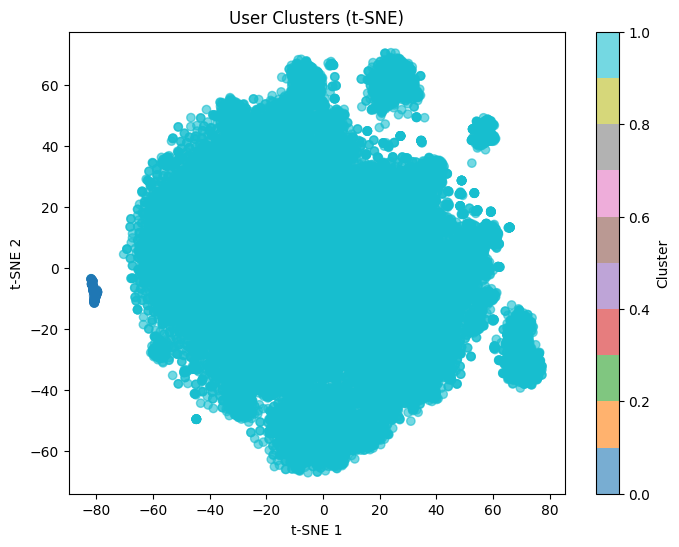

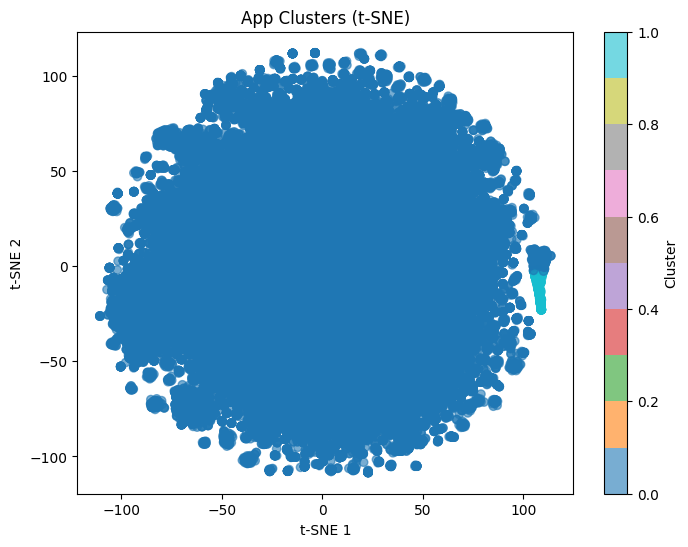


Recommended apps for user GWSPanel0000E427A0144EEC: ['win.free.gift.cards.make.money.cash.game.v6', 'com.modmeplay.a9minispycameraappguide', 'free.qr.code.reader.barcode.scanner.v3', 'org.codeaurora.dialer', 'com.tiktaktoolsstudio.mobilehotspot']
Hit rate: 0.0400


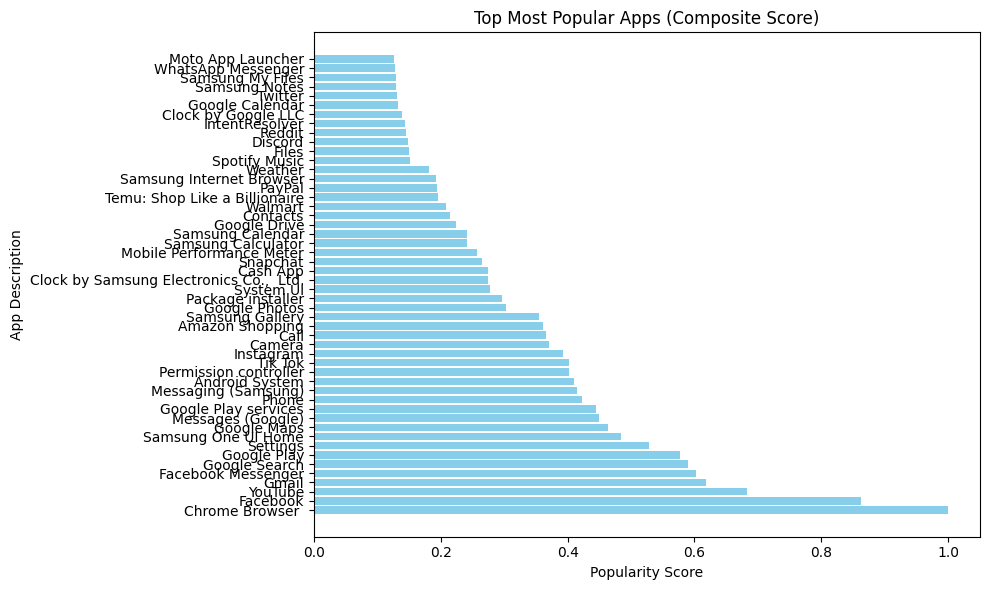


Top {top_num} Most Popular Apps (Composite Score):
                             APPDESCRIPTION  PopularityScore
0                           Chrome Browser          1.000000
1                                  Facebook         0.861846
2                                   YouTube         0.682573
3                                     Gmail         0.617479
4                        Facebook Messenger         0.602152
5                             Google Search         0.590257
6                               Google Play         0.576446
7                                  Settings         0.528578
8                       Samsung One UI Home         0.484393
9                               Google Maps         0.463488
10                        Messages (Google)         0.448903
11                     Google Play services         0.444393
12                                    Phone         0.422873
13                      Messaging (Samsung)         0.415433
14                           Andr

In [1]:
import torch
from torch_geometric.data import HeteroData
from torch_geometric.nn import MetaPath2Vec
import pandas as pd
import numpy as np
import gc
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, roc_auc_score, precision_recall_curve, precision_score, recall_score, f1_score
from sklearn.cluster import KMeans
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
import networkx as nx

# Set random seed for reproducibility
torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed(42)

# Parameters
batch_size_train = 64
batch_size_predict = 500
embedding_dim = 64
epochs = 50
metapaths = [('app', 'uses', 'user'), ('user', 'uses', 'app')]
walk_length = 50
context_size = 5
walks_per_node = 50
num_negative_samples = 10
learning_rate = 0.005

top_k = 50
top_num = 50

# Device setup
device = torch.device('mps' if torch.backends.mps.is_available() else 'cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

# Load data
def load_data():
    try:
        df_jan_full = pd.read_parquet('jan_aggregated.parquet')
        df_feb_full = pd.read_parquet('feb_aggregated.parquet')
        mappings = torch.load('jan_mappings.pt', weights_only=False)
        user_mapping_jan = mappings['user_mapping_jan']
        app_mapping_jan = mappings['app_mapping_jan']
        print(f"Loaded January data: {df_jan_full.shape}, February data: {df_feb_full.shape}")
        print(f"January mappings: {len(user_mapping_jan)} users, {len(app_mapping_jan)} apps")
        return df_jan_full, df_feb_full, user_mapping_jan, app_mapping_jan
    except Exception as e:
        print(f"Error loading data: {e}")
        raise

# Build January graph
def build_january_graph(df_jan_full):
    data_jan = HeteroData()
    unique_users_jan = df_jan_full['PANELISTID'].unique()
    unique_apps_jan = df_jan_full['APPDESCRIPTION'].unique()
    data_jan['user'].num_nodes = len(unique_users_jan)
    data_jan['app'].num_nodes = len(unique_apps_jan)
    user_mapping_jan = {user_id: idx for idx, user_id in enumerate(unique_users_jan)}
    app_mapping_jan = {app_id: idx for idx, app_id in enumerate(unique_apps_jan)}
    
    source_jan = df_jan_full['PANELISTID'].map(user_mapping_jan)
    target_jan = df_jan_full['APPDESCRIPTION'].map(app_mapping_jan)
    if source_jan.isnull().any() or target_jan.isnull().any():
        raise ValueError("NaN values in January edge indices")
    
    edge_indices = np.vstack([source_jan.values, target_jan.values])
    edge_index_jan = torch.tensor(edge_indices, dtype=torch.long)
    edge_indices_reverse = np.vstack([target_jan.values, source_jan.values])
    edge_index_jan_reverse = torch.tensor(edge_indices_reverse, dtype=torch.long)
    data_jan['user', 'uses', 'app'].edge_index = edge_index_jan
    data_jan['app', 'uses', 'user'].edge_index = edge_index_jan_reverse
    print(f"January graph: users={data_jan['user'].num_nodes}, apps={data_jan['app'].num_nodes}")
    return data_jan, user_mapping_jan, app_mapping_jan, unique_users_jan, unique_apps_jan

# Build February graph
def build_february_graph(df_feb_full):
    data_feb = HeteroData()
    unique_users_feb = df_feb_full['PANELISTID'].unique()
    unique_apps_feb = df_feb_full['APPDESCRIPTION'].unique()
    data_feb['user'].num_nodes = len(unique_users_feb)
    data_feb['app'].num_nodes = len(unique_apps_feb)
    user_mapping_feb = {user_id: idx for idx, user_id in enumerate(unique_users_feb)}
    app_mapping_feb = {app_id: idx for idx, app_id in enumerate(unique_apps_feb)}
    
    source_feb = df_feb_full['PANELISTID'].map(user_mapping_feb)
    target_feb = df_feb_full['APPDESCRIPTION'].map(app_mapping_feb)
    if source_feb.isnull().any() or target_feb.isnull().any():
        raise ValueError("NaN values in February edge indices")
    
    edge_indices = np.vstack([source_feb.values, target_feb.values])
    edge_index_feb = torch.tensor(edge_indices, dtype=torch.long)
    data_feb['user', 'uses', 'app'].edge_index = edge_index_feb
    print(f"February graph: users={data_feb['user'].num_nodes}, apps={data_feb['app'].num_nodes}")
    return data_feb, user_mapping_feb, app_mapping_feb, unique_users_feb, unique_apps_feb

# Initialize February embeddings
def initialize_feb_embeddings(unique_entities_feb, entity_mapping_jan, embeddings_jan, embedding_dim, method='mean'):
    embeddings_feb = np.zeros((len(unique_entities_feb), embedding_dim), dtype=np.float32)
    mean_embedding = np.mean(embeddings_jan, axis=0) if method == 'mean' else None
    for i, entity in enumerate(unique_entities_feb):
        if entity in entity_mapping_jan:
            embeddings_feb[i] = embeddings_jan[entity_mapping_jan[entity]]
        else:
            embeddings_feb[i] = mean_embedding if method == 'mean' else np.random.normal(0, 0.01, embedding_dim)
    return embeddings_feb

# Binary operators for edge features and app-app similarity
def hadamard(u, v): return u * v
def l1(u, v): return np.abs(u - v)
def l2(u, v): return (u - v) ** 2
def average(u, v): return (u + v) / 2
def cosine(u, v):
    norm_u = np.linalg.norm(u)
    norm_v = np.linalg.norm(v)
    norm_u = 1e-10 if norm_u == 0 else norm_u
    norm_v = 1e-10 if norm_v == 0 else norm_v
    return (u * v) / (norm_u * norm_v)
def weighted_sum(u, v, w1=0.6, w2=0.4): return w1 * u + w2 * v
def maximum(u, v): return np.maximum(u, v)
def minimum(u, v): return np.minimum(u, v)
def exp_diff(u, v): return np.exp(-np.abs(u - v))

# Compute edge features
def compute_edge_features(user_emb, app_emb, edge_indices, binary_op):
    user_indices, app_indices = edge_indices
    return np.array([binary_op(user_emb[u], app_emb[a]) for u, a in zip(user_indices, app_indices)], dtype=np.float32)

# Compute app-app similarity
def compute_app_app_similarity(app_embeddings, app_mapping, binary_op, op_name, df, top_k, is_distance=False):
    num_apps = app_embeddings.shape[0]
    app_ids = list(app_mapping.keys())
    
    scores = np.zeros((num_apps, num_apps), dtype=np.float32)
    for i in range(num_apps):
        for j in range(i + 1, num_apps):
            score_vec = binary_op(app_embeddings[i], app_embeddings[j])
            score = np.mean(score_vec) if not is_distance else np.sum(score_vec)
            scores[i, j] = score
            scores[j, i] = score
    
    indices = np.triu_indices(num_apps, k=1)
    scores_flat = scores[indices]
    top_indices = np.argsort(scores_flat)[::-1][:top_k] if not is_distance else np.argsort(scores_flat)[:top_k]
    top_pairs = [(indices[0][idx], indices[1][idx]) for idx in top_indices]
    
    top_pairs_with_scores = [
        (app_ids[i], app_ids[j], scores[i, j])
        for i, j in top_pairs
    ]
    
    print(f"\nTop {top_k} App-App Pairs by {op_name} {'Similarity' if not is_distance else 'Distance'}:")
    for app1, app2, score in top_pairs_with_scores:
        print(f"{app1} - {app2}: {score:.4f}")
    
    return top_pairs_with_scores

# Validate app-app similarity using February data
def validate_app_pairs(top_pairs, df_feb, app_mapping):
    print("\nValidation of Top App Pairs with February Data:")
    for app1, app2, score in top_pairs:
        app1_idx = app_mapping[app1]
        app2_idx = app_mapping[app2]
        users_app1 = set(df_feb[df_feb['APPDESCRIPTION'] == app1]['PANELISTID'].unique())
        users_app2 = set(df_feb[df_feb['APPDESCRIPTION'] == app2]['PANELISTID'].unique())
        common_users = len(users_app1.intersection(users_app2))
        total_users = len(users_app1.union(users_app2))
        jaccard = common_users / total_users if total_users > 0 else 0
        print(f"{app1} - {app2}: Jaccard Similarity eukaryote Overlap) = {jaccard:.4f}")

# Compare app-app similarity across months
def compare_temporal_similarity(top_pairs_jan, top_pairs_feb):
    print("\nTemporal Consistency Analysis of App-App Similarity:")
    pairs_jan = {(app1, app2) for app1, app2, _ in top_pairs_jan}
    pairs_feb = {(app1, app2) for app1, app2, _ in top_pairs_feb}
    common_pairs = pairs_jan.intersection(pairs_feb)
    consistency_ratio = len(common_pairs) / len(pairs_jan) if len(pairs_jan) > 0 else 0
    print(f"Number of common app-app pairs between January and February: {len(common_pairs)}")
    print(f"Consistency ratio: {consistency_ratio:.4f}")
    for app1, app2 in common_pairs:
        score_jan = next(score for a1, a2, score in top_pairs_jan if (a1, a2) == (app1, app2))
        score_feb = next(score for a1, a2, score in top_pairs_feb if (a1, a2) == (app1, app2))
        print(f"{app1} - {app2}: January Score = {score_jan:.4f}, February Score = {score_feb:.4f}")

# Compute app-app similarity within clusters
#def compute_similarity_within_clusters(app_embeddings, app_mapping, app_clusters, n_clusters, binary_op, op_name, df, top_k, is_distance=False):
#    app_ids = list(app_mapping.keys())
#    for cluster_id in range(n_clusters):
#        cluster_indices = np.where(app_clusters == cluster_id)[0]
#        if len(cluster_indices) < 2:
#            print(f"Cluster {cluster_id} has fewer than 2 apps, skipping.")
#            continue
#        cluster_embeddings = app_embeddings[cluster_indices]
#        cluster_mapping = {app_ids[idx]: i for i, idx in enumerate#(cluster_indices)}
#        print(f"\nComputing similarity for Cluster {cluster_id} ({len(cluster_indices)} apps):")
#        compute_app_app_similarity(cluster_embeddings, cluster_mapping, binary_op, f"{op_name}_cluster_{cluster_id}", df, top_k=top_k, is_distance=is_distance)

# Visualize app-app similarity network
def visualize_app_similarity_network(top_pairs, filename="app_similarity_network.png"):
    G = nx.Graph()
    for app1, app2, score in top_pairs:
        G.add_edge(app1, app2, weight=score)
    
    plt.figure(figsize=(12, 8))
    pos = nx.spring_layout(G)
    edges = G.edges(data=True)
    weights = [edge[2]['weight'] for edge in edges]
    nx.draw(G, pos, with_labels=True, node_color='lightblue', node_size=500, font_size=10, edge_color=weights, edge_cmap=plt.cm.Blues, width=2)
    plt.title("App-App Similarity Network")
    plt.show()
    plt.close()

# Train and evaluate classifier
def train_classifier(X, y, X_val, y_val, binary_op_name, scaler=None):
    if scaler:
        X_scaled = scaler.fit_transform(X)
        X_val_scaled = scaler.transform(X_val)
    else:
        X_scaled, X_val_scaled = X, X_val
    
    clf = LogisticRegression(max_iter=1000, class_weight='balanced')
    clf.fit(X_scaled, y)
    
    pred_probs = clf.predict_proba(X_val_scaled)[:, 1]
    roc_auc = roc_auc_score(y_val, pred_probs)
    
    prec, rec, thresholds = precision_recall_curve(y_val, pred_probs)
    f1_scores = 2 * (prec * rec) / (prec + rec + 1e-10)
    best_threshold = thresholds[np.argmax(f1_scores)]
    pred_labels = (pred_probs > best_threshold).astype(np.int8)
    
    precision = precision_score(y_val, pred_labels)
    recall = recall_score(y_val, pred_labels)
    f1 = f1_score(y_val, pred_labels)
    
    return clf, scaler, roc_auc, precision, recall, f1, best_threshold, pred_labels, pred_probs

# Cluster and evaluate
def cluster_and_evaluate(embeddings, name, max_clusters=10):
    silhouette_scores = []
    cluster_labels = []
    for n_clusters in range(2, max_clusters + 1):
        kmeans = KMeans(n_clusters=n_clusters, random_state=42)
        labels = kmeans.fit_predict(embeddings)
        score = silhouette_score(embeddings, labels)
        silhouette_scores.append(score)
        cluster_labels.append(labels)
        print(f"{name} - {n_clusters} clusters: Silhouette Score = {score:.4f}")
    
    best_n_clusters = np.argmax(silhouette_scores) + 2
    best_labels = cluster_labels[best_n_clusters - 2]
    print(f"Best number of {name} clusters: {best_n_clusters}")
    return best_labels, best_n_clusters

# Visualize clusters
def visualize_clusters(embeddings, labels, name):
    tsne = TSNE(n_components=2, random_state=42, n_jobs=-1)
    embeddings_2d = tsne.fit_transform(embeddings)
    
    plt.figure(figsize=(8, 6))
    scatter = plt.scatter(embeddings_2d[:, 0], embeddings_2d[:, 1], c=labels, cmap='tab10', alpha=0.6)
    plt.title(f'{name} Clusters (t-SNE)')
    plt.colorbar(scatter, label='Cluster')
    plt.xlabel('t-SNE 1')
    plt.ylabel('t-SNE 2')
    plt.show()
    plt.close()

# Recommend apps
def recommend_apps(user_id, user_embeddings, app_embeddings, user_mapping, app_mapping, user_clusters, df_feb, top_n=5):
    if user_id not in user_mapping:
        print(f"User {user_id} not found in January data.")
        return [], 0.0
    
    user_idx = user_mapping[user_id]
    user_emb = user_embeddings[user_idx]
    user_cluster = user_clusters[user_idx]
    
    cluster_users = np.where(user_clusters == user_cluster)[0]
    cluster_user_ids = [list(user_mapping.keys())[list(user_mapping.values()).index(idx)] for idx in cluster_users]
    cluster_apps = df_feb[df_feb['PANELISTID'].isin(cluster_user_ids)]['APPDESCRIPTION'].value_counts().head(top_num).index
    
    user_norm = np.linalg.norm(user_emb)
    app_norms = np.linalg.norm(app_embeddings, axis=1)
    app_norms[app_norms == 0] = 1e-10
    similarities = np.dot(app_embeddings, user_emb) / (user_norm * app_norms)
    
    app_indices = [app_mapping[app] for app in cluster_apps if app in app_mapping]
    similarities[app_indices] *= 1.2
    
    top_indices = np.argsort(similarities)[-top_n:][::-1]
    recommended_apps = [list(app_mapping.keys())[list(app_mapping.values()).index(idx)] for idx in top_indices]
    
    user_feb_apps = df_feb[df_feb['PANELISTID'] == user_id]['APPDESCRIPTION'].unique()
    hits = sum(app in user_feb_apps for app in recommended_apps)
    hit_rate = hits / top_num if top_n > 0 else 0
    return recommended_apps, hit_rate

# Analyze popular apps
def analyze_popular_apps(df_feb):
    duration = df_feb.groupby('APPDESCRIPTION')['weight'].sum()
    user_count = df_feb.groupby('APPDESCRIPTION')['PANELISTID'].nunique()
    # Convert to float to handle Decimal types
    duration = duration.astype(float)
    user_count = user_count.astype(float)
    duration_norm = (duration - duration.min()) / (duration.max() - duration.min() + 1e-10)
    user_count_norm = (user_count - user_count.min()) / (user_count.max() - user_count.min() + 1e-10)
    popularity_score = 0.5 * duration_norm + 0.5 * user_count_norm
    
    top_apps = popularity_score.sort_values(ascending=False).head(top_num).reset_index()
    top_apps.columns = ['APPDESCRIPTION', 'PopularityScore']
    
    plt.figure(figsize=(10, 6))
    plt.barh(top_apps['APPDESCRIPTION'], top_apps['PopularityScore'], color='skyblue')
    plt.title('Top Most Popular Apps (Composite Score)')
    plt.xlabel('Popularity Score')
    plt.ylabel('App Description')
    plt.tight_layout()
    plt.show()
    plt.close()
    
    return top_apps

# Main workflow
def main():
    if device.type == 'cuda':
        torch.cuda.empty_cache()
    elif device.type == 'mps':
        torch.mps.empty_cache()
    gc.collect()

    df_jan_full, df_feb_full, user_mapping_jan, app_mapping_jan = load_data()
    
    data_jan, user_mapping_jan, app_mapping_jan, unique_users_jan, unique_apps_jan = build_january_graph(df_jan_full)
    data_feb, user_mapping_feb, app_mapping_feb, unique_users_feb, unique_apps_feb = build_february_graph(df_feb_full)
    
    try:
        data_jan = data_jan.to(device)
        model = MetaPath2Vec(
            edge_index_dict=data_jan.edge_index_dict,
            embedding_dim=embedding_dim,
            metapath=metapaths,
            walk_length=walk_length,
            context_size=context_size,
            walks_per_node=walks_per_node,
            num_negative_samples=num_negative_samples
        ).to(device)
    except RuntimeError as e:
        print(f"Failed to allocate to {device}: {e}. Falling back to CPU.")
        data_jan = data_jan.to('cpu')
        model = MetaPath2Vec(
            edge_index_dict=data_jan.edge_index_dict,
            embedding_dim=embedding_dim,
            metapath=metapaths,
            walk_length=walk_length,
            context_size=context_size,
            walks_per_node=walks_per_node,
            num_negative_samples=num_negative_samples
        ).to('cpu')
    
    # Load pre-trained model
    model_path = "metapath2vec_january.pth"
    try:
        checkpoint = torch.load(model_path, map_location=device, weights_only=False)
        model.load_state_dict(checkpoint['model_state_dict'])
        print(f"Loaded pre-trained model from {model_path}")
    except Exception as e:
        print(f"Error loading model from {model_path}: {e}")
        raise
    
    user_embeddings_jan = model('user').detach().cpu().numpy()
    app_embeddings_jan = model('app').detach().cpu().numpy()
    print(f"January user embeddings shape: {user_embeddings_jan.shape}")
    print(f"January app embeddings shape: {app_embeddings_jan.shape}")
    
    app_usage = df_jan_full.groupby('APPDESCRIPTION')['weight'].sum()
    app_user_count = df_jan_full.groupby('APPDESCRIPTION')['PANELISTID'].nunique()
    min_duration = app_usage.quantile(0.1, interpolation='nearest')
    min_users = 5
    popular_apps = app_usage[(app_usage > min_duration) & (app_user_count > min_users)].index
    app_indices = [app_mapping_jan[app] for app in popular_apps if app in app_mapping_jan]
    filtered_app_embeddings_jan = app_embeddings_jan[app_indices]
    filtered_app_mapping_jan = {app: idx for idx, app in enumerate(popular_apps)}
    print(f"Filtered to {len(popular_apps)} popular apps for similarity computation (January)")
    
    user_embeddings_feb = initialize_feb_embeddings(unique_users_feb, user_mapping_jan, user_embeddings_jan, embedding_dim, method='mean')
    app_embeddings_feb = initialize_feb_embeddings(unique_apps_feb, app_mapping_jan, app_embeddings_jan, embedding_dim, method='mean')
    
    app_usage_feb = df_feb_full.groupby('APPDESCRIPTION')['weight'].sum()
    app_user_count_feb = df_feb_full.groupby('APPDESCRIPTION')['PANELISTID'].nunique()
    min_duration_feb = app_usage_feb.quantile(0.1,interpolation='nearest')
    popular_apps_feb = app_usage_feb[(app_usage_feb > min_duration_feb) & (app_user_count_feb > min_users)].index
    app_indices_feb = [app_mapping_feb[app] for app in popular_apps_feb if app in app_mapping_feb]
    filtered_app_embeddings_feb = app_embeddings_feb[app_indices_feb]
    filtered_app_mapping_feb = {app: idx for idx, app in enumerate(popular_apps_feb)}
    print(f"Filtered to {len(popular_apps_feb)} popular apps for similarity computation (February)")

    # Link prediction withlot classifier
    true_edge_indices = data_feb['user', 'uses', 'app'].edge_index.cpu().numpy()
    true_indices_train, true_indices_val = train_test_split(np.arange(true_edge_indices.shape[1]), train_size=0.75, random_state=42)
    
    similarity = user_embeddings_feb @ app_embeddings_feb.T
    neg_indices = np.where(similarity > np.percentile(similarity, 90))
    neg_indices = np.array([neg_indices[0][:len(true_edge_indices[0])], neg_indices[1][:len(true_edge_indices[0])]])
    neg_indices_train, neg_indices_val = train_test_split(np.arange(neg_indices.shape[1]), train_size=0.75, random_state=42)
    
    binary_operators = {
        'hadamard': hadamard,
        'l1': l1,
        'l2': l2,
        'average': average,
        'cosine': cosine,
        'weighted_sum': weighted_sum,
        'maximum': maximum,
        'minimum': minimum,
        'exp_diff': exp_diff
    }
    
    best_clf, best_scaler, best_op, best_score, best_threshold, best_cm = None, None, None, 0, 0.5, None
    for op_name, op in binary_operators.items():
        true_features_train = compute_edge_features(user_embeddings_feb, app_embeddings_feb, [true_edge_indices[0][true_indices_train], true_edge_indices[1][true_indices_train]], op)
        neg_features_train = compute_edge_features(user_embeddings_feb, app_embeddings_feb, [neg_indices[0][neg_indices_train], neg_indices[1][neg_indices_train]], op)
        true_features_val = compute_edge_features(user_embeddings_feb, app_embeddings_feb, [true_edge_indices[0][true_indices_val], true_edge_indices[1][true_indices_val]], op)
        neg_features_val = compute_edge_features(user_embeddings_feb, app_embeddings_feb, [neg_indices[0][neg_indices_val], neg_indices[1][neg_indices_val]], op)
        
        X_train = np.vstack([true_features_train, neg_features_train])
        y_train = np.concatenate([np.ones(len(true_features_train)), np.zeros(len(neg_features_train))])
        X_val = np.vstack([true_features_val, neg_features_val])
        y_val = np.concatenate([np.ones(len(true_features_val)), np.zeros(len(neg_features_val))])
        
        scaler = StandardScaler()
        clf, scaler, roc_auc, precision, recall, f1, thresh, pred_labels, pred_probs = train_classifier(X_train, y_train, X_val, y_val, op_name, scaler)
        cm = confusion_matrix(y_val, pred_labels)
        print(f"Operator: {op_name}, ROC-AUC: {roc_auc:.4f}, Precision: {precision:.4f}, Recall: {recall:.4f}, F1: {f1:.4f}, Threshold: {thresh:.4f}")
        
        if roc_auc > best_score:
            best_clf, best_scaler, best_op, best_score, best_threshold, best_cm = clf, scaler, op, roc_auc, thresh, cm
    
    plt.figure(figsize=(8, 6))
    sns.heatmap(best_cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Predicted Negative', 'Predicted Positive'], yticklabels=['Actual Negative', 'Actual Positive'])
    plt.title(f'Confusion Matrix (Operator: {best_op.__name__}, Threshold: {best_threshold:.2f})')
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.show()
    
    similarity_ops = [
        ('cosine', cosine, False),
        ('l1', l1, True),
        ('exp_diff', exp_diff, False)
    ]
    
    # Temporal consistency analysis
    for op_name, op, is_distance in similarity_ops:
        print(f"\n--- Analyzing {op_name} ---")
        top_pairs_jan = compute_app_app_similarity(filtered_app_embeddings_jan, filtered_app_mapping_jan, op, f"{op_name}_jan", df_jan_full, top_k, is_distance=is_distance)
        validate_app_pairs(top_pairs_jan, df_feb_full, filtered_app_mapping_jan)
        top_pairs_feb = compute_app_app_similarity(filtered_app_embeddings_feb, filtered_app_mapping_feb, op, f"{op_name}_feb", df_feb_full, top_k, is_distance=is_distance)
        compare_temporal_similarity(top_pairs_jan, top_pairs_feb)
        visualize_app_similarity_network(top_pairs_jan, f"app_similarity_network_{op_name}_jan.png")
    
    # Clustering
    user_clusters, user_n_clusters = cluster_and_evaluate(user_embeddings_jan, "User")
    app_clusters, app_n_clusters = cluster_and_evaluate(app_embeddings_jan, "App")
    visualize_clusters(user_embeddings_jan, user_clusters, "User")
    visualize_clusters(app_embeddings_jan, app_clusters, "App")
    
    # Cluster-based similarity
    #for op_name, op, is_distance in similarity_ops:
    #    compute_similarity_within_clusters(app_embeddings_jan, app_mapping_jan, app_clusters, app_n_clusters, op, op_name, df_jan_full, top_k, is_distance=is_distance)
    
    sample_user_id = unique_users_jan[0]
    recommended_apps, hit_rate = recommend_apps(sample_user_id, user_embeddings_jan, app_embeddings_jan, user_mapping_jan, app_mapping_jan, user_clusters, df_feb_full)
    print(f"\nRecommended apps for user {sample_user_id}: {recommended_apps}")
    print(f"Hit rate: {hit_rate:.4f}")
    
    top_apps = analyze_popular_apps(df_feb_full)
    print("\nTop {top_num} Most Popular Apps (Composite Score):")
    print(top_apps)

if __name__ == "__main__":
    main()

Using device: mps
Loaded January data: (2210089, 3), February data: (2429195, 3)
January mappings: 34639 users, 74754 apps
January graph: users=34639, apps=74754
February graph: users=40001, apps=80277
Loaded pre-trained model from metapath2vec_january.pth
January user embeddings shape: (34639, 64)
January app embeddings shape: (74754, 64)
Filtered to 14349 popular apps for similarity computation (January)
Filtered to 14959 popular apps for similarity computation (February)
Operator: hadamard, ROC-AUC: 0.8861, Precision: 0.9024, Recall: 0.7838, F1: 0.8389, Threshold: 0.4424
Operator: l1, ROC-AUC: 0.8902, Precision: 0.9126, Recall: 0.7529, F1: 0.8251, Threshold: 0.3870
Operator: l2, ROC-AUC: 0.8692, Precision: 0.8797, Recall: 0.7583, F1: 0.8145, Threshold: 0.3681
Operator: average, ROC-AUC: 0.9131, Precision: 0.8869, Recall: 0.8020, F1: 0.8423, Threshold: 0.4485
Operator: cosine, ROC-AUC: 0.9105, Precision: 0.8903, Recall: 0.8374, F1: 0.8630, Threshold: 0.4223
Operator: weighted_sum, RO

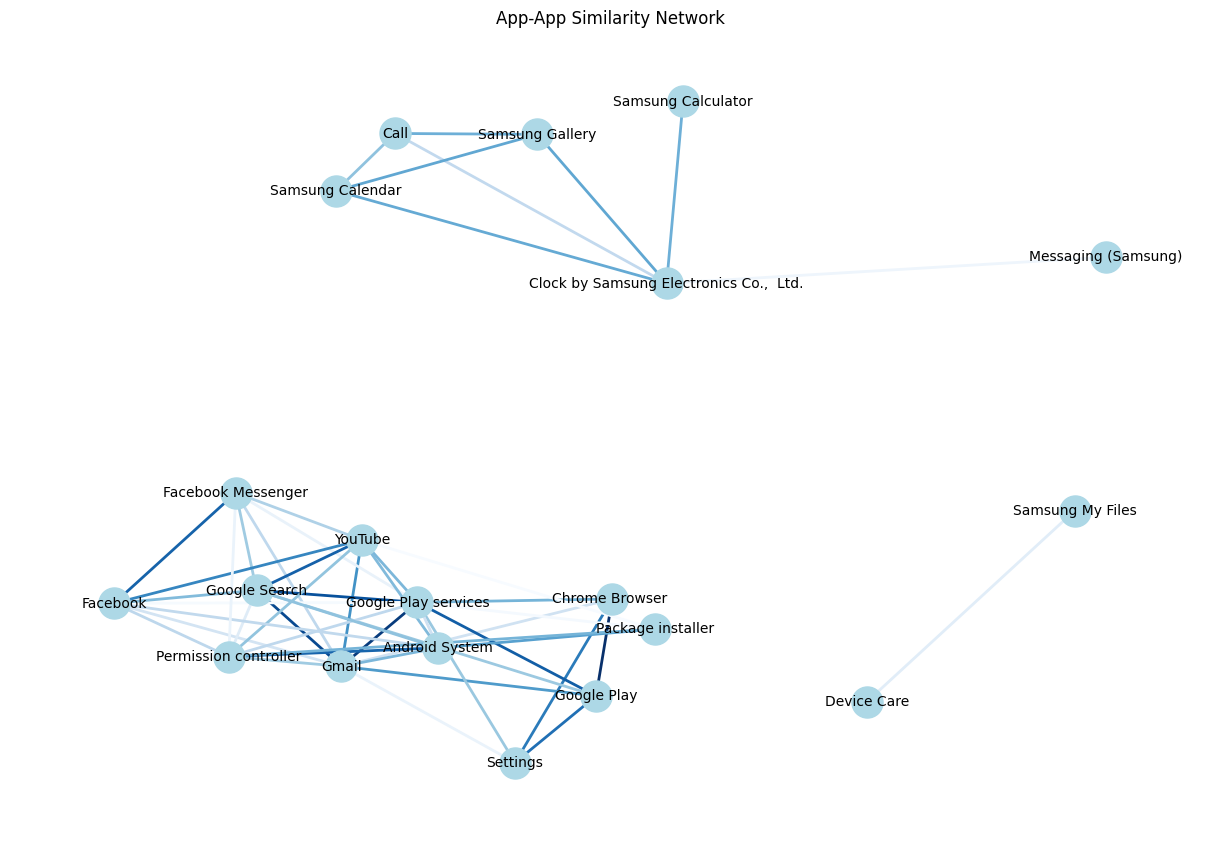

User - 2 clusters: Silhouette Score = 0.9671
User - 3 clusters: Silhouette Score = 0.0562
User - 4 clusters: Silhouette Score = 0.0588
User - 5 clusters: Silhouette Score = 0.0559
User - 6 clusters: Silhouette Score = 0.0574
User - 7 clusters: Silhouette Score = 0.0239
User - 8 clusters: Silhouette Score = 0.0559
User - 9 clusters: Silhouette Score = 0.0582
User - 10 clusters: Silhouette Score = 0.0224
Best number of User clusters: 2
App - 2 clusters: Silhouette Score = 0.9379
App - 3 clusters: Silhouette Score = 0.8907
App - 4 clusters: Silhouette Score = 0.3976
App - 5 clusters: Silhouette Score = 0.3521
App - 6 clusters: Silhouette Score = 0.3508
App - 7 clusters: Silhouette Score = 0.1626
App - 8 clusters: Silhouette Score = 0.0355
App - 9 clusters: Silhouette Score = 0.0348
App - 10 clusters: Silhouette Score = 0.0302
Best number of App clusters: 2


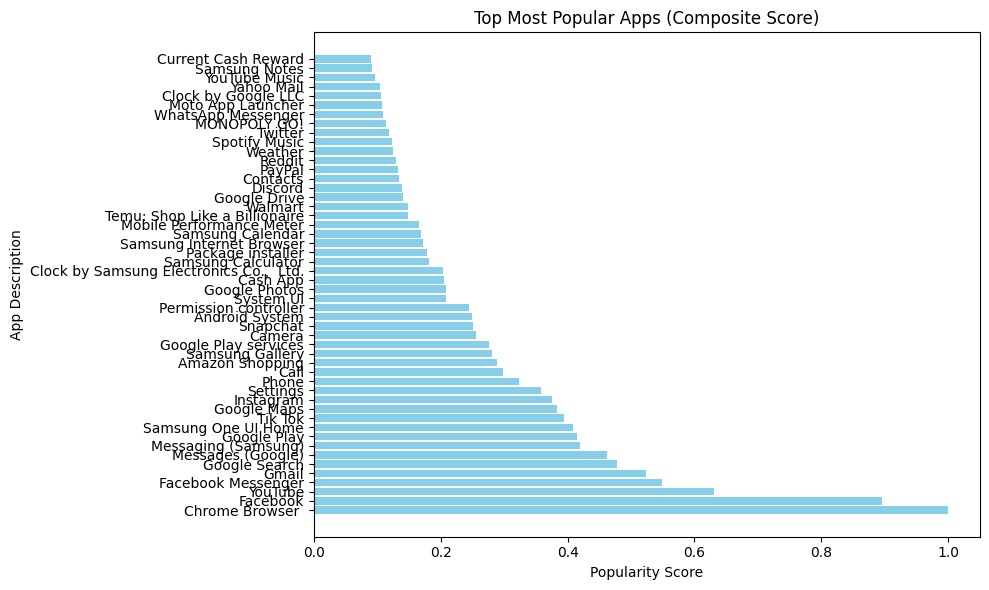


Top Most Popular Apps (Composite Score):
                             APPDESCRIPTION  PopularityScore
0                           Chrome Browser          1.000000
1                                  Facebook         0.894768
2                                   YouTube         0.631338
3                        Facebook Messenger         0.548109
4                                     Gmail         0.523248
5                             Google Search         0.478418
6                         Messages (Google)         0.462392
7                       Messaging (Samsung)         0.419372
8                               Google Play         0.414120
9                       Samsung One UI Home         0.408462
10                                  Tik Tok         0.393659
11                              Google Maps         0.383670
12                                Instagram         0.375398
13                                 Settings         0.358425
14                                    Phone

In [1]:
import torch
from torch_geometric.data import HeteroData
from torch_geometric.nn import MetaPath2Vec
import pandas as pd
import numpy as np
import gc
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, precision_recall_curve, precision_score, recall_score, f1_score
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.model_selection import train_test_split
import networkx as nx
import plotly.graph_objects as go
import matplotlib.pyplot as plt

# Set random seed for reproducibility
torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed(42)

# Parameters
batch_size_train = 64
batch_size_predict = 500
embedding_dim = 64
epochs = 50
metapaths = [('app', 'uses', 'user'), ('user', 'uses', 'app')]
walk_length = 50
context_size = 5
walks_per_node = 50
num_negative_samples = 10
learning_rate = 0.005

top_k = 50
top_num = 50

# Device setup
device = torch.device('mps' if torch.backends.mps.is_available() else 'cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

# Load data
def load_data():
    try:
        df_jan_full = pd.read_parquet('jan_aggregated.parquet')
        df_feb_full = pd.read_parquet('feb_aggregated.parquet')
        mappings = torch.load('jan_mappings.pt', weights_only=False)
        user_mapping_jan = mappings['user_mapping_jan']
        app_mapping_jan = mappings['app_mapping_jan']
        print(f"Loaded January data: {df_jan_full.shape}, February data: {df_feb_full.shape}")
        print(f"January mappings: {len(user_mapping_jan)} users, {len(app_mapping_jan)} apps")
        return df_jan_full, df_feb_full, user_mapping_jan, app_mapping_jan
    except Exception as e:
        print(f"Error loading data: {e}")
        raise

# Build January graph
def build_january_graph(df_jan_full):
    data_jan = HeteroData()
    unique_users_jan = df_jan_full['PANELISTID'].unique()
    unique_apps_jan = df_jan_full['APPDESCRIPTION'].unique()
    data_jan['user'].num_nodes = len(unique_users_jan)
    data_jan['app'].num_nodes = len(unique_apps_jan)
    user_mapping_jan = {user_id: idx for idx, user_id in enumerate(unique_users_jan)}
    app_mapping_jan = {app_id: idx for idx, app_id in enumerate(unique_apps_jan)}
    
    source_jan = df_jan_full['PANELISTID'].map(user_mapping_jan)
    target_jan = df_jan_full['APPDESCRIPTION'].map(app_mapping_jan)
    if source_jan.isnull().any() or target_jan.isnull().any():
        raise ValueError("NaN values in January edge indices")
    
    edge_indices = np.vstack([source_jan.values, target_jan.values])
    edge_index_jan = torch.tensor(edge_indices, dtype=torch.long)
    edge_indices_reverse = np.vstack([target_jan.values, source_jan.values])
    edge_index_jan_reverse = torch.tensor(edge_indices_reverse, dtype=torch.long)
    data_jan['user', 'uses', 'app'].edge_index = edge_index_jan
    data_jan['app', 'uses', 'user'].edge_index = edge_index_jan_reverse
    print(f"January graph: users={data_jan['user'].num_nodes}, apps={data_jan['app'].num_nodes}")
    return data_jan, user_mapping_jan, app_mapping_jan, unique_users_jan, unique_apps_jan

# Build February graph
def build_february_graph(df_feb_full):
    data_feb = HeteroData()
    unique_users_feb = df_feb_full['PANELISTID'].unique()
    unique_apps_feb = df_feb_full['APPDESCRIPTION'].unique()
    data_feb['user'].num_nodes = len(unique_users_feb)
    data_feb['app'].num_nodes = len(unique_apps_feb)
    user_mapping_feb = {user_id: idx for idx, user_id in enumerate(unique_users_feb)}
    app_mapping_feb = {app_id: idx for idx, app_id in enumerate(unique_apps_feb)}
    
    source_feb = df_feb_full['PANELISTID'].map(user_mapping_feb)
    target_feb = df_feb_full['APPDESCRIPTION'].map(app_mapping_feb)
    if source_feb.isnull().any() or target_feb.isnull().any():
        raise ValueError("NaN values in February edge indices")
    
    edge_indices = np.vstack([source_feb.values, target_feb.values])
    edge_index_feb = torch.tensor(edge_indices, dtype=torch.long)
    data_feb['user', 'uses', 'app'].edge_index = edge_index_feb
    print(f"February graph: users={data_feb['user'].num_nodes}, apps={data_feb['app'].num_nodes}")
    return data_feb, user_mapping_feb, app_mapping_feb, unique_users_feb, unique_apps_feb

# Initialize February embeddings
def initialize_feb_embeddings(unique_entities_feb, entity_mapping_jan, embeddings_jan, embedding_dim, method='mean'):
    embeddings_feb = np.zeros((len(unique_entities_feb), embedding_dim), dtype=np.float32)
    mean_embedding = np.mean(embeddings_jan, axis=0) if method == 'mean' else None
    for i, entity in enumerate(unique_entities_feb):
        if entity in entity_mapping_jan:
            embeddings_feb[i] = embeddings_jan[entity_mapping_jan[entity]]
        else:
            embeddings_feb[i] = mean_embedding if method == 'mean' else np.random.normal(0, 0.01, embedding_dim)
    return embeddings_feb

# Binary operators for edge features and app-app similarity
def hadamard(u, v): return u * v
def l1(u, v): return np.abs(u - v)
def l2(u, v): return (u - v) ** 2
def average(u, v): return (u + v) / 2
def cosine(u, v):
    norm_u = np.linalg.norm(u)
    norm_v = np.linalg.norm(v)
    norm_u = 1e-10 if norm_u == 0 else norm_u
    norm_v = 1e-10 if norm_v == 0 else norm_v
    return (u * v) / (norm_u * norm_v)
def weighted_sum(u, v, w1=0.6, w2=0.4): return w1 * u + w2 * v
def maximum(u, v): return np.maximum(u, v)
def minimum(u, v): return np.minimum(u, v)
def exp_diff(u, v): return np.exp(-np.abs(u - v))

# Compute edge features
def compute_edge_features(user_emb, app_emb, edge_indices, binary_op):
    user_indices, app_indices = edge_indices
    return np.array([binary_op(user_emb[u], app_emb[a]) for u, a in zip(user_indices, app_indices)], dtype=np.float32)

#Compute app-app similarity
def compute_app_app_similarity(app_embeddings, app_mapping, binary_op, op_name, df, top_k, is_distance=False):
    num_apps = app_embeddings.shape[0]
    app_ids = list(app_mapping.keys())
    
    scores = np.zeros((num_apps, num_apps), dtype=np.float32)
    for i in range(num_apps):
        for j in range(i + 1, num_apps):
            score_vec = binary_op(app_embeddings[i], app_embeddings[j])
            score = np.mean(score_vec) if not is_distance else np.sum(score_vec)
            scores[i, j] = score
            scores[j, i] = score
    
    indices = np.triu_indices(num_apps, k=1)
    scores_flat = scores[indices]
    top_indices = np.argsort(scores_flat)[::-1][:top_k] if not is_distance else np.argsort(scores_flat)[:top_k]
    top_pairs = [(indices[0][idx], indices[1][idx]) for idx in top_indices]
    
    top_pairs_with_scores = [
        (app_ids[i], app_ids[j], scores[i, j])
        for i, j in top_pairs
    ]
    
    print(f"\nTop {top_k} App-App Pairs by {op_name} {'Similarity' if not is_distance else 'Distance'}:")
    for app1, app2, score in top_pairs_with_scores:
        print(f"{app1} - {app2}: {score:.4f}")
    
    return top_pairs_with_scores

# Validate app-app similarity using February data
def validate_app_pairs(top_pairs, df_feb, app_mapping):
    print("\nValidation of Top App Pairs with February Data:")
    for app1, app2, score in top_pairs:
        app1_idx = app_mapping[app1]
        app2_idx = app_mapping[app2]
        users_app1 = set(df_feb[df_feb['APPDESCRIPTION'] == app1]['PANELISTID'].unique())
        users_app2 = set(df_feb[df_feb['APPDESCRIPTION'] == app2]['PANELISTID'].unique())
        common_users = len(users_app1.intersection(users_app2))
        total_users = len(users_app1.union(users_app2))
        jaccard = common_users / total_users if total_users > 0 else 0
        print(f"{app1} - {app2}: Jaccard Similarity (User Overlap) = {jaccard:.4f}")

# Compare app-app similarity across months
def compare_temporal_similarity(top_pairs_jan, top_pairs_feb):
    print("\nTemporal Consistency Analysis of App-App Similarity:")
    pairs_jan = {(app1, app2) for app1, app2, _ in top_pairs_jan}
    pairs_feb = {(app1, app2) for app1, app2, _ in top_pairs_feb}
    common_pairs = pairs_jan.intersection(pairs_feb)
    consistency_ratio = len(common_pairs) / len(pairs_jan) if len(pairs_jan) > 0 else 0
    print(f"Number of common app-app pairs between January and February: {len(common_pairs)}")
    print(f"Consistency ratio: {consistency_ratio:.4f}")
    for app1, app2 in common_pairs:
        score_jan = next(score for a1, a2, score in top_pairs_jan if (a1, a2) == (app1, app2))
        score_feb = next(score for a1, a2, score in top_pairs_feb if (a1, a2) == (app1, app2))
        print(f"{app1} - {app2}: January Score = {score_jan:.4f}, February Score = {score_feb:.4f}")

# Visualize app-app similarity network
def visualize_app_similarity_network(top_pairs, filename="app_similarity_network.png"):
    G = nx.Graph()
    for app1, app2, score in top_pairs:
        G.add_edge(app1, app2, weight=score)
    
    plt.figure(figsize=(12, 8))
    pos = nx.spring_layout(G)
    edges = G.edges(data=True)
    weights = [edge[2]['weight'] for edge in edges]
    nx.draw(G, pos, with_labels=True, node_color='lightblue', node_size=500, font_size=10, edge_color=weights, edge_cmap=plt.cm.Blues, width=2)
    plt.title("App-App Similarity Network")
    plt.show()
    plt.close()

# Train and evaluate classifier
def train_classifier(X, y, X_val, y_val, binary_op_name, scaler=None):
    if scaler:
        X_scaled = scaler.fit_transform(X)
        X_val_scaled = scaler.transform(X_val)
    else:
        X_scaled, X_val_scaled = X, X_val
    
    clf = LogisticRegression(max_iter=1000, class_weight='balanced')
    clf.fit(X_scaled, y)
    
    pred_probs = clf.predict_proba(X_val_scaled)[:, 1]
    roc_auc = roc_auc_score(y_val, pred_probs)
    
    prec, rec, thresholds = precision_recall_curve(y_val, pred_probs)
    f1_scores = 2 * (prec * rec) / (prec + rec + 1e-10)
    best_threshold = thresholds[np.argmax(f1_scores)]
    pred_labels = (pred_probs > best_threshold).astype(np.int8)
    
    precision = precision_score(y_val, pred_labels)
    recall = recall_score(y_val, pred_labels)
    f1 = f1_score(y_val, pred_labels)
    
    return clf, scaler, roc_auc, precision, recall, f1, best_threshold, pred_labels, pred_probs

# Cluster and evaluate
def cluster_and_evaluate(embeddings, name, max_clusters=10):
    silhouette_scores = []
    cluster_labels = []
    for n_clusters in range(2, max_clusters + 1):
        kmeans = KMeans(n_clusters=n_clusters, random_state=42)
        labels = kmeans.fit_predict(embeddings)
        silhouette_scores.append(silhouette_score(embeddings, labels))
        cluster_labels.append(labels)
        print(f"{name} - {n_clusters} clusters: Silhouette Score = {silhouette_scores[-1]:.4f}")
    
    best_n_clusters = np.argmax(silhouette_scores) + 2
    best_labels = cluster_labels[best_n_clusters - 2]
    print(f"Best number of {name} clusters: {best_n_clusters}")
    return best_labels, best_n_clusters

# Recommend apps
def recommend_apps(user_id, user_embeddings, app_embeddings, user_mapping, app_mapping, user_clusters, df_feb, top_n=5):
    if user_id not in user_mapping:
        print(f"User {user_id} not found in January data.")
        return [], 0.0
    
    user_idx = user_mapping[user_id]
    user_emb = user_embeddings[user_idx]
    user_cluster = user_clusters[user_idx]
    
    cluster_users = np.where(user_clusters == user_cluster)[0]
    cluster_user_ids = [list(user_mapping.keys())[list(user_mapping.values()).index(idx)] for idx in cluster_users]
    cluster_apps = df_feb[df_feb['PANELISTID'].isin(cluster_user_ids)]['APPDESCRIPTION'].value_counts().head(top_n).index
    
    user_norm = np.linalg.norm(user_emb)
    app_norms = np.linalg.norm(app_embeddings, axis=1)
    app_norms[app_norms == 0] = 1e-10
    similarities = np.dot(app_embeddings, user_emb) / (user_norm * app_norms)
    
    app_indices = [app_mapping[app] for app in cluster_apps if app in app_mapping]
    similarities[app_indices] *= 1.2
    
    top_indices = np.argsort(similarities)[-top_n:][::-1]
    recommended_apps = [list(app_mapping.keys())[list(app_mapping.values()).index(idx)] for idx in top_indices]
    
    user_feb_apps = df_feb[df_feb['PANELISTID'] == user_id]['APPDESCRIPTION'].unique()
    hits = sum(app in user_feb_apps for app in recommended_apps)
    hit_rate = hits / top_n if top_n > 0 else 0
    return recommended_apps, hit_rate

# Analyze popular apps
def analyze_popular_apps(df_feb):
    duration = df_feb.groupby('APPDESCRIPTION')['weight'].sum()
    user_count = df_feb.groupby('APPDESCRIPTION')['PANELISTID'].nunique()
    duration = duration.astype(float)
    user_count = user_count.astype(float)
    duration_norm = (duration - duration.min()) / (duration.max() - duration.min() + 1e-10)
    user_count_norm = (user_count - user_count.min()) / (user_count.max() - user_count.min() + 1e-10)
    popularity_score = 0.7 * duration_norm + 0.3 * user_count_norm
    
    top_apps = popularity_score.sort_values(ascending=False).head(top_num).reset_index()
    top_apps.columns = ['APPDESCRIPTION', 'PopularityScore']
    
    plt.figure(figsize=(10, 6))
    plt.barh(top_apps['APPDESCRIPTION'], top_apps['PopularityScore'], color='skyblue')
    plt.title('Top Most Popular Apps (Composite Score)')
    plt.xlabel('Popularity Score')
    plt.ylabel('App Description')
    plt.tight_layout()
    plt.show()
    plt.close()
    
    return top_apps

# Compute similarity between two apps
def compute_pair_similarity(app1, app2, app_embeddings, app_mapping, binary_op=cosine):
    if app1 not in app_mapping or app2 not in app_mapping:
        print(f"One or both apps ({app1}, {app2}) not found in app mapping.")
        return None
    idx1, idx2 = app_mapping[app1], app_mapping[app2]
    emb1, emb2 = app_embeddings[idx1], app_embeddings[idx2]
    similarity = binary_op(emb1, emb2)
    return np.mean(similarity)

# Find app pairs within a popularity score range
def find_app_pairs(top_apps, app_embeddings, app_mapping, min_score=0.2, max_score=0.5, top_k_pairs=5, binary_op=cosine):
    target_apps = top_apps[(top_apps['PopularityScore'] >= min_score) & (top_apps['PopularityScore'] <= max_score)]
    target_app_names = target_apps['APPDESCRIPTION'].tolist()
    
    if len(target_app_names) < 2:
        print(f"Not enough apps found with popularity scores between {min_score} and {max_score}.")
        return []
    
    app_pairs = []
    for i in range(len(target_app_names)):
        for j in range(i + 1, len(target_app_names)):
            app1, app2 = target_app_names[i], target_app_names[j]
            if app1 in app_mapping and app2 in app_mapping:
                similarity = compute_pair_similarity(app1, app2, app_embeddings, app_mapping, binary_op)
                if similarity is not None:
                    app_pairs.append((app1, app2, similarity))
    
    app_pairs.sort(key=lambda x: x[2], reverse=True)
    top_pairs = app_pairs[:top_k_pairs]
    
    print(f"\nTop {top_k_pairs} App Pairs (Popularity Score {min_score}-{max_score}):")
    for app1, app2, sim in top_pairs:
        print(f"{app1} - {app2}: Similarity = {sim:.4f}")
    
    return top_pairs

# Analyze app switching behavior for a specific user and app pair
def predict_user_app_switching(user_id, app1, app2, df_jan, df_feb, app_mapping_jan, app_mapping_feb, user_mapping_jan, user_clusters, user_embeddings_jan, app_embeddings_jan, clf, scaler, best_threshold, binary_op):
    if user_id not in user_mapping_jan:
        print(f"User {user_id} not found in January data.")
        return None, None, None, None, None
    
    if app1 not in app_mapping_jan or app2 not in app_mapping_jan:
        print(f"One or both apps ({app1}, {app2}) not found in January mappings.")
        return None, None, None, None, None
    if app1 not in app_mapping_feb or app2 not in app_mapping_feb:
        print(f"One or both apps ({app1}, {app2}) not found in February mappings.")
        return None, None, None, None, None
    
    # Check if user used app1 in January but not app2
    user_jan_apps = df_jan[df_jan['PANELISTID'] == user_id]['APPDESCRIPTION'].unique()
    used_app1_jan = app1 in user_jan_apps
    used_app2_jan = app2 in user_jan_apps
    
    if not used_app1_jan or used_app2_jan:
        print(f"User {user_id} did not use {app1} exclusively in January (used_app1: {used_app1_jan}, used_app2: {used_app2_jan}).")
        return None, None, None, None, None
    
    # Predict probability of using app2 in February
    user_idx = user_mapping_jan[user_id]
    app2_idx = app_mapping_feb[app2]
    user_emb = user_embeddings_jan[user_idx]
    app2_emb = app_embeddings_feb[app2_idx]
    
    # Compute edge features using the best binary operator
    edge_features = binary_op(user_emb, app2_emb).reshape(1, -1)
    edge_features_scaled = scaler.transform(edge_features)
    
    # Predict probability using the trained classifier
    pred_prob = clf.predict_proba(edge_features_scaled)[:, 1][0]
    pred_label = int(pred_prob > best_threshold)
    
    # Check actual February usage
    user_feb_apps = df_feb[df_feb['PANELISTID'] == user_id]['APPDESCRIPTION'].unique()
    actual_switch = app2 in user_feb_apps
    
    # If the user switched, calculate usage duration
    total_duration = 0
    if actual_switch:
        switched_users_df = df_feb[(df_feb['PANELISTID'] == user_id) & (df_feb['APPDESCRIPTION'] == app2)]
        total_duration = switched_users_df['weight'].sum() if not switched_users_df.empty else 0
    
    # Cluster information
    user_cluster = user_clusters[user_idx]
    
    print(f"\nPrediction for user {user_id} switching from {app1} (January) to {app2} (February):")
    print(f"User cluster: {user_cluster}")
    print(f"Predicted probability of using {app2}: {pred_prob:.4f}")
    print(f"Predicted switch (threshold {best_threshold:.4f}): {'Yes' if pred_label else 'No'}")
    print(f"Actual switch: {'Yes' if actual_switch else 'No'}")
    if actual_switch:
        print(f"Total usage duration of {app2} in February: {total_duration:.2f}")
    
    return pred_prob, pred_label, actual_switch, total_duration, user_cluster

# Visualize user flow between app pairs (for cohort of users in the same cluster)
def visualize_switching_flow(df_jan, df_feb, app1, app2, cluster_users, user_mapping_jan):
    cluster_user_ids = [list(user_mapping_jan.keys())[list(user_mapping_jan.values()).index(idx)] for idx in cluster_users]
    
    users_app1_jan = set(df_jan[(df_jan['PANELISTID'].isin(cluster_user_ids)) & (df_jan['APPDESCRIPTION'] == app1)]['PANELISTID'].unique())
    users_app2_jan = set(df_jan[(df_jan['PANELISTID'].isin(cluster_user_ids)) & (df_jan['APPDESCRIPTION'] == app2)]['PANELISTID'].unique())
    users_app1_only_jan = users_app1_jan - users_app2_jan
    users_app2_only_jan = users_app2_jan - users_app1_jan
    
    users_app1_feb = set(df_feb[(df_feb['PANELISTID'].isin(cluster_user_ids)) & (df_feb['APPDESCRIPTION'] == app1)]['PANELISTID'].unique())
    users_app2_feb = set(df_feb[(df_feb['PANELISTID'].isin(cluster_user_ids)) & (df_feb['APPDESCRIPTION'] == app2)]['PANELISTID'].unique())
    
    app1_to_app1 = len(users_app1_only_jan.intersection(users_app1_feb))
    app1_to_app2 = len(users_app1_only_jan.intersection(users_app2_feb))
    app1_to_none = len(users_app1_only_jan) - app1_to_app1 - app1_to_app2
    app2_to_app2 = len(users_app2_only_jan.intersection(users_app2_feb))
    app2_to_app1 = len(users_app2_only_jan.intersection(users_app1_feb))
    app2_to_none = len(users_app2_only_jan) - app2_to_app2 - app2_to_app1
    
    labels = [f"{app1} (Jan)", f"{app2} (Jan)", f"{app1} (Feb)", f"{app2} (Feb)", "None (Feb)"]
    source = [0, 0, 0, 1, 1, 1]
    target = [2, 3, 4, 2, 3, 4]
    value = [app1_to_app1, app1_to_app2, app1_to_none, app2_to_app1, app2_to_app2, app2_to_none]
    
    fig = go.Figure(data=[go.Sankey(
        node=dict(
            pad=15,
            thickness=20,
            line=dict(color="black", width=0.5),
            label=labels,
            color="blue"
        ),
        link=dict(
            source=source,
            target=target,
            value=value,
            color="lightblue"
        )
    )])
    
    fig.update_layout(title_text=f"User Flow Between {app1} and {app2} (January to February) for Cluster", font_size=10)
    fig.show()

# Main workflow
def main():
    if device.type == 'cuda':
        torch.cuda.empty_cache()
    elif device.type == 'mps':
        torch.mps.empty_cache()
    gc.collect()

    df_jan_full, df_feb_full, user_mapping_jan, app_mapping_jan = load_data()
    
    data_jan, user_mapping_jan, app_mapping_jan, unique_users_jan, unique_apps_jan = build_january_graph(df_jan_full)
    data_feb, user_mapping_feb, app_mapping_feb, unique_users_feb, unique_apps_feb = build_february_graph(df_feb_full)
    
    try:
        data_jan = data_jan.to(device)
        model = MetaPath2Vec(
            edge_index_dict=data_jan.edge_index_dict,
            embedding_dim=embedding_dim,
            metapath=metapaths,
            walk_length=walk_length,
            context_size=context_size,
            walks_per_node=walks_per_node,
            num_negative_samples=num_negative_samples
        ).to(device)
    except RuntimeError as e:
        print(f"Failed to allocate to {device}: {e}. Falling back to CPU.")
        data_jan = data_jan.to('cpu')
        model = MetaPath2Vec(
            edge_index_dict=data_jan.edge_index_dict,
            embedding_dim=embedding_dim,
            metapath=metapaths,
            walk_length=walk_length,
            context_size=context_size,
            walks_per_node=walks_per_node,
            num_negative_samples=num_negative_samples
        ).to('cpu')
    
    # Load pre-trained model
    model_path = "metapath2vec_january.pth"
    try:
        checkpoint = torch.load(model_path, map_location=device, weights_only=False)
        model.load_state_dict(checkpoint['model_state_dict'])
        print(f"Loaded pre-trained model from {model_path}")
    except Exception as e:
        print(f"Error loading model from {model_path}: {e}")
        raise
    
    user_embeddings_jan = model('user').detach().cpu().numpy()
    app_embeddings_jan = model('app').detach().cpu().numpy()
    print(f"January user embeddings shape: {user_embeddings_jan.shape}")
    print(f"January app embeddings shape: {app_embeddings_jan.shape}")
    
    app_usage = df_jan_full.groupby('APPDESCRIPTION')['weight'].sum()
    app_user_count = df_jan_full.groupby('APPDESCRIPTION')['PANELISTID'].nunique()
    min_duration = app_usage.quantile(0.1, interpolation='nearest')
    min_users = 5
    popular_apps = app_usage[(app_usage > min_duration) & (app_user_count > min_users)].index
    app_indices = [app_mapping_jan[app] for app in popular_apps if app in app_mapping_jan]
    filtered_app_embeddings_jan = app_embeddings_jan[app_indices]
    filtered_app_mapping_jan = {app: idx for idx, app in enumerate(popular_apps)}
    print(f"Filtered to {len(popular_apps)} popular apps for similarity computation (January)")
    
    user_embeddings_feb = initialize_feb_embeddings(unique_users_feb, user_mapping_jan, user_embeddings_jan, embedding_dim, method='mean')
    app_embeddings_feb = initialize_feb_embeddings(unique_apps_feb, app_mapping_jan, app_embeddings_jan, embedding_dim, method='mean')
    
    app_usage_feb = df_feb_full.groupby('APPDESCRIPTION')['weight'].sum()
    app_user_count_feb = df_feb_full.groupby('APPDESCRIPTION')['PANELISTID'].nunique()
    min_duration_feb = app_usage_feb.quantile(0.1, interpolation='nearest')
    popular_apps_feb = app_usage_feb[(app_usage_feb > min_duration_feb) & (app_user_count_feb > min_users)].index
    app_indices_feb = [app_mapping_feb[app] for app in popular_apps_feb if app in app_mapping_feb]
    filtered_app_embeddings_feb = app_embeddings_feb[app_indices_feb]
    filtered_app_mapping_feb = {app: idx for idx, app in enumerate(popular_apps_feb)}
    print(f"Filtered to {len(popular_apps_feb)} popular apps for similarity computation (February)")

    # Link prediction with classifier
    true_edge_indices = data_feb['user', 'uses', 'app'].edge_index.cpu().numpy()
    true_indices_train, true_indices_val = train_test_split(np.arange(true_edge_indices.shape[1]), train_size=0.75, random_state=42)
    
    similarity = user_embeddings_feb @ app_embeddings_feb.T
    neg_indices = np.where(similarity > np.percentile(similarity, 90))
    neg_indices = np.array([neg_indices[0][:len(true_edge_indices[0])], neg_indices[1][:len(true_edge_indices[0])]])
    neg_indices_train, neg_indices_val = train_test_split(np.arange(neg_indices.shape[1]), train_size=0.75, random_state=42)
    
    binary_operators = {
        'hadamard': hadamard,
        'l1': l1,
        'l2': l2,
        'average': average,
        'cosine': cosine,
        'weighted_sum': weighted_sum,
        'maximum': maximum,
        'minimum': minimum,
        'exp_diff': exp_diff
    }
    
    best_clf, best_scaler, best_op, best_score, best_threshold, best_cm = None, None, None, 0, 0.5, None
    for op_name, op in binary_operators.items():
        true_features_train = compute_edge_features(user_embeddings_feb, app_embeddings_feb, [true_edge_indices[0][true_indices_train], true_edge_indices[1][true_indices_train]], op)
        neg_features_train = compute_edge_features(user_embeddings_feb, app_embeddings_feb, [neg_indices[0][neg_indices_train], neg_indices[1][neg_indices_train]], op)
        true_features_val = compute_edge_features(user_embeddings_feb, app_embeddings_feb, [true_edge_indices[0][true_indices_val], true_edge_indices[1][true_indices_val]], op)
        neg_features_val = compute_edge_features(user_embeddings_feb, app_embeddings_feb, [neg_indices[0][neg_indices_val], neg_indices[1][neg_indices_val]], op)
        
        X_train = np.vstack([true_features_train, neg_features_train])
        y_train = np.concatenate([np.ones(len(true_features_train)), np.zeros(len(neg_features_train))])
        X_val = np.vstack([true_features_val, neg_features_val])
        y_val = np.concatenate([np.ones(len(true_features_val)), np.zeros(len(neg_features_val))])
        
        scaler = StandardScaler()
        clf, scaler, roc_auc, precision, recall, f1, thresh, pred_labels, pred_probs = train_classifier(X_train, y_train, X_val, y_val, op_name, scaler)
        print(f"Operator: {op_name}, ROC-AUC: {roc_auc:.4f}, Precision: {precision:.4f}, Recall: {recall:.4f}, F1: {f1:.4f}, Threshold: {thresh:.4f}")
        
        if roc_auc > best_score:
            best_clf, best_scaler, best_op, best_score, best_threshold, best_cm = clf, scaler, op, roc_auc, thresh, best_cm
    
    similarity_ops = [
        ('cosine', cosine, False),
        #('l1', l1, True),
        #('exp_diff', exp_diff, False)
    ]
    
    # Temporal consistency analysis
    for op_name, op, is_distance in similarity_ops:
        print(f"\n--- Analyzing {op_name} ---")
        top_pairs_jan = compute_app_app_similarity(filtered_app_embeddings_jan, filtered_app_mapping_jan, op, f"{op_name}_jan", df_jan_full, top_k, is_distance=is_distance)
        validate_app_pairs(top_pairs_jan, df_feb_full, filtered_app_mapping_jan)
        top_pairs_feb = compute_app_app_similarity(filtered_app_embeddings_feb, filtered_app_mapping_feb, op, f"{op_name}_feb", df_feb_full, top_k, is_distance=is_distance)
        compare_temporal_similarity(top_pairs_jan, top_pairs_feb)
        visualize_app_similarity_network(top_pairs_jan, f"app_similarity_network_{op_name}_jan.png")
    
    # Clustering
    user_clusters, user_n_clusters = cluster_and_evaluate(user_embeddings_jan, "User")
    app_clusters, app_n_clusters = cluster_and_evaluate(app_embeddings_jan, "App")
    
    top_apps = analyze_popular_apps(df_feb_full)
    print("\nTop Most Popular Apps (Composite Score):")
    print(top_apps)
    
    # Find app pairs with popularity scores between 0.2 and 0.5
    top_pairs = find_app_pairs(top_apps, app_embeddings_jan, app_mapping_jan, min_score=0.2, max_score=0.5, top_k_pairs=5)
    
    # Select a user for prediction (using the sample user)
    sample_user_id = unique_users_jan[0]
    
    # Predict switching for the user across all top pairs
    for app1, app2, similarity in top_pairs:
        print(f"\nPredicting switching for user {sample_user_id} with pair: {app1} - {app2}")
        pred_prob, pred_label, actual_switch, total_duration, user_cluster = predict_user_app_switching(
            sample_user_id, app1, app2, df_jan_full, df_feb_full, app_mapping_jan, app_mapping_feb,
            user_mapping_jan, user_clusters, user_embeddings_jan, app_embeddings_feb,
            best_clf, best_scaler, best_threshold, best_op
        )
        if pred_prob is not None:  # Only visualize if prediction was successful
            cluster_users = np.where(user_clusters == user_cluster)[0]
            visualize_switching_flow(df_jan_full, df_feb_full, app1, app2, cluster_users, user_mapping_jan)

if __name__ == "__main__":
    main()

Using device: mps
Loaded January data: (2210089, 3), February data: (2429195, 3)
January mappings: 34639 users, 74754 apps
January graph: users=34639, apps=74754
February graph: users=40001, apps=80277
Loaded pre-trained model from metapath2vec_january.pth
January user embeddings shape: (34639, 64)
January app embeddings shape: (74754, 64)
Filtered to 14349 popular apps for similarity computation (January)
Filtered to 14959 popular apps for similarity computation (February)
Operator: hadamard, ROC-AUC: 0.8861, Precision: 0.9024, Recall: 0.7838, F1: 0.8389, Threshold: 0.4424
Operator: l1, ROC-AUC: 0.8902, Precision: 0.9126, Recall: 0.7529, F1: 0.8251, Threshold: 0.3870
Operator: l2, ROC-AUC: 0.8692, Precision: 0.8797, Recall: 0.7583, F1: 0.8145, Threshold: 0.3681
Operator: average, ROC-AUC: 0.9131, Precision: 0.8869, Recall: 0.8020, F1: 0.8423, Threshold: 0.4485
Operator: cosine, ROC-AUC: 0.9105, Precision: 0.8903, Recall: 0.8374, F1: 0.8630, Threshold: 0.4223
Operator: weighted_sum, RO

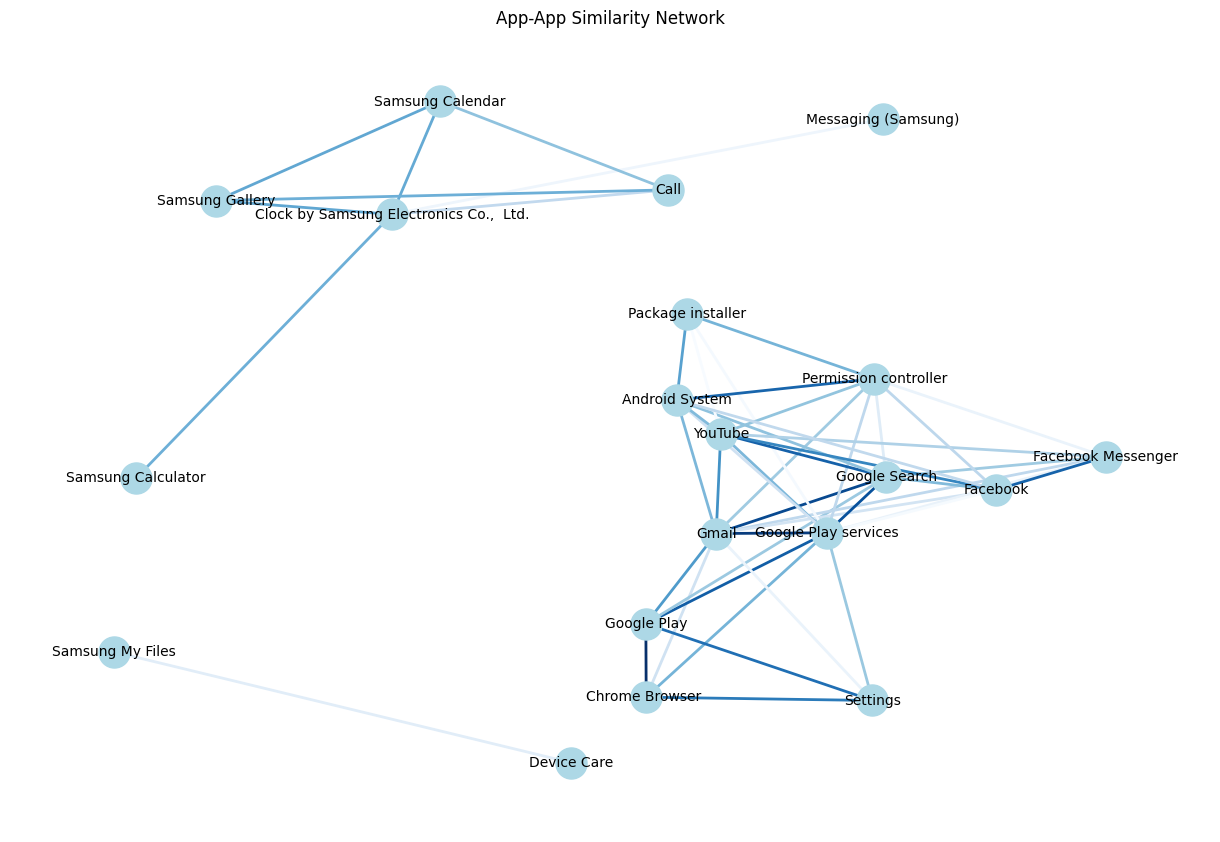

User - 2 clusters: Silhouette Score = 0.9671
User - 3 clusters: Silhouette Score = 0.0562
User - 4 clusters: Silhouette Score = 0.0588
User - 5 clusters: Silhouette Score = 0.0559
User - 6 clusters: Silhouette Score = 0.0574
User - 7 clusters: Silhouette Score = 0.0239
User - 8 clusters: Silhouette Score = 0.0559
User - 9 clusters: Silhouette Score = 0.0582
User - 10 clusters: Silhouette Score = 0.0224
Best number of User clusters: 2
App - 2 clusters: Silhouette Score = 0.9379
App - 3 clusters: Silhouette Score = 0.8907
App - 4 clusters: Silhouette Score = 0.3976
App - 5 clusters: Silhouette Score = 0.3521
App - 6 clusters: Silhouette Score = 0.3508
App - 7 clusters: Silhouette Score = 0.1626
App - 8 clusters: Silhouette Score = 0.0355
App - 9 clusters: Silhouette Score = 0.0348
App - 10 clusters: Silhouette Score = 0.0302
Best number of App clusters: 2


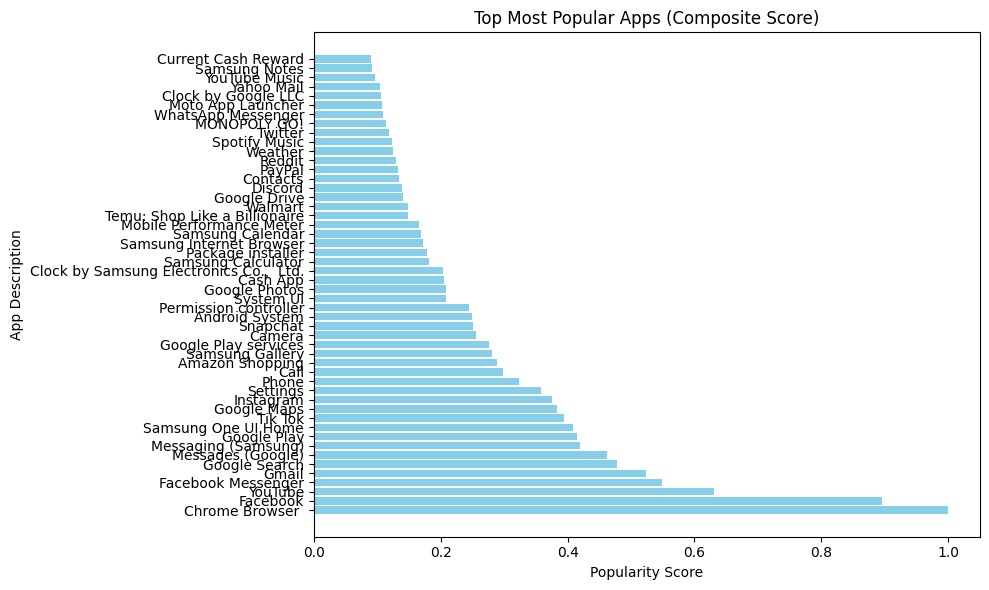


Top Most Popular Apps (Composite Score):
                             APPDESCRIPTION  PopularityScore
0                           Chrome Browser          1.000000
1                                  Facebook         0.894768
2                                   YouTube         0.631338
3                        Facebook Messenger         0.548109
4                                     Gmail         0.523248
5                             Google Search         0.478418
6                         Messages (Google)         0.462392
7                       Messaging (Samsung)         0.419372
8                               Google Play         0.414120
9                       Samsung One UI Home         0.408462
10                                  Tik Tok         0.393659
11                              Google Maps         0.383670
12                                Instagram         0.375398
13                                 Settings         0.358425
14                                    Phone

In [3]:
import torch
from torch_geometric.data import HeteroData
from torch_geometric.nn import MetaPath2Vec
import pandas as pd
import numpy as np
import gc
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, precision_recall_curve, precision_score, recall_score, f1_score
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.model_selection import train_test_split
import networkx as nx
import plotly.graph_objects as go
import matplotlib.pyplot as plt

# Set random seed for reproducibility
torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed(42)

# Parameters
batch_size_train = 64
batch_size_predict = 500
embedding_dim = 64
epochs = 50
metapaths = [('app', 'uses', 'user'), ('user', 'uses', 'app')]
walk_length = 50
context_size = 5
walks_per_node = 50
num_negative_samples = 10
learning_rate = 0.005
top_k = 50
top_num = 50

# Device setup
device = torch.device('mps' if torch.backends.mps.is_available() else 'cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

# Load data
def load_data():
    try:
        df_jan_full = pd.read_parquet('jan_aggregated.parquet')
        df_feb_full = pd.read_parquet('feb_aggregated.parquet')
        mappings = torch.load('jan_mappings.pt', weights_only=False)
        user_mapping_jan = mappings['user_mapping_jan']
        app_mapping_jan = mappings['app_mapping_jan']
        print(f"Loaded January data: {df_jan_full.shape}, February data: {df_feb_full.shape}")
        print(f"January mappings: {len(user_mapping_jan)} users, {len(app_mapping_jan)} apps")
        return df_jan_full, df_feb_full, user_mapping_jan, app_mapping_jan
    except Exception as e:
        print(f"Error loading data: {e}")
        raise

# Build January graph
def build_january_graph(df_jan_full):
    data_jan = HeteroData()
    unique_users_jan = df_jan_full['PANELISTID'].unique()
    unique_apps_jan = df_jan_full['APPDESCRIPTION'].unique()
    data_jan['user'].num_nodes = len(unique_users_jan)
    data_jan['app'].num_nodes = len(unique_apps_jan)
    user_mapping_jan = {user_id: idx for idx, user_id in enumerate(unique_users_jan)}
    app_mapping_jan = {app_id: idx for idx, app_id in enumerate(unique_apps_jan)}
    
    source_jan = df_jan_full['PANELISTID'].map(user_mapping_jan)
    target_jan = df_jan_full['APPDESCRIPTION'].map(app_mapping_jan)
    if source_jan.isnull().any() or target_jan.isnull().any():
        raise ValueError("NaN values in January edge indices")
    
    edge_indices = np.vstack([source_jan.values, target_jan.values])
    edge_index_jan = torch.tensor(edge_indices, dtype=torch.long)
    edge_indices_reverse = np.vstack([target_jan.values, source_jan.values])
    edge_index_jan_reverse = torch.tensor(edge_indices_reverse, dtype=torch.long)
    data_jan['user', 'uses', 'app'].edge_index = edge_index_jan
    data_jan['app', 'uses', 'user'].edge_index = edge_index_jan_reverse
    print(f"January graph: users={data_jan['user'].num_nodes}, apps={data_jan['app'].num_nodes}")
    return data_jan, user_mapping_jan, app_mapping_jan, unique_users_jan, unique_apps_jan

# Build February graph
def build_february_graph(df_feb_full):
    data_feb = HeteroData()
    unique_users_feb = df_feb_full['PANELISTID'].unique()
    unique_apps_feb = df_feb_full['APPDESCRIPTION'].unique()
    data_feb['user'].num_nodes = len(unique_users_feb)
    data_feb['app'].num_nodes = len(unique_apps_feb)
    user_mapping_feb = {user_id: idx for idx, user_id in enumerate(unique_users_feb)}
    app_mapping_feb = {app_id: idx for idx, app_id in enumerate(unique_apps_feb)}
    
    source_feb = df_feb_full['PANELISTID'].map(user_mapping_feb)
    target_feb = df_feb_full['APPDESCRIPTION'].map(app_mapping_feb)
    if source_feb.isnull().any() or target_feb.isnull().any():
        raise ValueError("NaN values in February edge indices")
    
    edge_indices = np.vstack([source_feb.values, target_feb.values])
    edge_index_feb = torch.tensor(edge_indices, dtype=torch.long)
    data_feb['user', 'uses', 'app'].edge_index = edge_index_feb
    print(f"February graph: users={data_feb['user'].num_nodes}, apps={data_feb['app'].num_nodes}")
    return data_feb, user_mapping_feb, app_mapping_feb, unique_users_feb, unique_apps_feb

# Initialize February embeddings
def initialize_feb_embeddings(unique_entities_feb, entity_mapping_jan, embeddings_jan, embedding_dim, method='mean'):
    embeddings_feb = np.zeros((len(unique_entities_feb), embedding_dim), dtype=np.float32)
    mean_embedding = np.mean(embeddings_jan, axis=0) if method == 'mean' else None
    for i, entity in enumerate(unique_entities_feb):
        if entity in entity_mapping_jan:
            embeddings_feb[i] = embeddings_jan[entity_mapping_jan[entity]]
        else:
            embeddings_feb[i] = mean_embedding if method == 'mean' else np.random.normal(0, 0.01, embedding_dim)
    return embeddings_feb

# Binary operators for edge features and app-app similarity
def hadamard(u, v): return u * v
def l1(u, v): return np.abs(u - v)
def l2(u, v): return (u - v) ** 2
def average(u, v): return (u + v) / 2
def cosine(u, v):
    norm_u = np.linalg.norm(u)
    norm_v = np.linalg.norm(v)
    norm_u = 1e-10 if norm_u == 0 else norm_u
    norm_v = 1e-10 if norm_v == 0 else norm_v
    return (u * v) / (norm_u * norm_v)
def weighted_sum(u, v, w1=0.6, w2=0.4): return w1 * u + w2 * v
def maximum(u, v): return np.maximum(u, v)
def minimum(u, v): return np.minimum(u, v)
def exp_diff(u, v): return np.exp(-np.abs(u - v))

# Compute edge features
def compute_edge_features(user_emb, app_emb, edge_indices, binary_op):
    user_indices, app_indices = edge_indices
    return np.array([binary_op(user_emb[u], app_emb[a]) for u, a in zip(user_indices, app_indices)], dtype=np.float32)

# Compute app-app similarity
def compute_app_app_similarity(app_embeddings, app_mapping, binary_op, op_name, df, top_k, is_distance=False):
    num_apps = app_embeddings.shape[0]
    app_ids = list(app_mapping.keys())
    
    scores = np.zeros((num_apps, num_apps), dtype=np.float32)
    for i in range(num_apps):
        for j in range(i + 1, num_apps):
            score_vec = binary_op(app_embeddings[i], app_embeddings[j])
            score = np.mean(score_vec) if not is_distance else np.sum(score_vec)
            scores[i, j] = score
            scores[j, i] = score
    
    indices = np.triu_indices(num_apps, k=1)
    scores_flat = scores[indices]
    top_indices = np.argsort(scores_flat)[::-1][:top_k] if not is_distance else np.argsort(scores_flat)[:top_k]
    top_pairs = [(indices[0][idx], indices[1][idx]) for idx in top_indices]
    
    top_pairs_with_scores = [
        (app_ids[i], app_ids[j], scores[i, j])
        for i, j in top_pairs
    ]
    
    print(f"\nTop {top_k} App-App Pairs by {op_name} {'Similarity' if not is_distance else 'Distance'}:")
    for app1, app2, score in top_pairs_with_scores:
        print(f"{app1} - {app2}: {score:.4f}")
    
    return top_pairs_with_scores

# Validate app-app similarity using February data
def validate_app_pairs(top_pairs, df_feb, app_mapping):
    print("\nValidation of Top App Pairs with February Data:")
    for app1, app2, score in top_pairs:
        app1_idx = app_mapping[app1]
        app2_idx = app_mapping[app2]
        users_app1 = set(df_feb[df_feb['APPDESCRIPTION'] == app1]['PANELISTID'].unique())
        users_app2 = set(df_feb[df_feb['APPDESCRIPTION'] == app2]['PANELISTID'].unique())
        common_users = len(users_app1.intersection(users_app2))
        total_users = len(users_app1.union(users_app2))
        jaccard = common_users / total_users if total_users > 0 else 0
        print(f"{app1} - {app2}: Jaccard Similarity (User Overlap) = {jaccard:.4f}")

# Compare app-app similarity across months
def compare_temporal_similarity(top_pairs_jan, top_pairs_feb):
    print("\nTemporal Consistency Analysis of App-App Similarity:")
    pairs_jan = {(app1, app2) for app1, app2, _ in top_pairs_jan}
    pairs_feb = {(app1, app2) for app1, app2, _ in top_pairs_feb}
    common_pairs = pairs_jan.intersection(pairs_feb)
    consistency_ratio = len(common_pairs) / len(pairs_jan) if len(pairs_jan) > 0 else 0
    print(f"Number of common app-app pairs between January and February: {len(common_pairs)}")
    print(f"Consistency ratio: {consistency_ratio:.4f}")
    for app1, app2 in common_pairs:
        score_jan = next(score for a1, a2, score in top_pairs_jan if (a1, a2) == (app1, app2))
        score_feb = next(score for a1, a2, score in top_pairs_feb if (a1, a2) == (app1, app2))
        print(f"{app1} - {app2}: January Score = {score_jan:.4f}, February Score = {score_feb:.4f}")

# Visualize app-app similarity network
def visualize_app_similarity_network(top_pairs, filename="app_similarity_network.png"):
    G = nx.Graph()
    for app1, app2, score in top_pairs:
        G.add_edge(app1, app2, weight=score)
    
    plt.figure(figsize=(12, 8))
    pos = nx.spring_layout(G)
    edges = G.edges(data=True)
    weights = [edge[2]['weight'] for edge in edges]
    nx.draw(G, pos, with_labels=True, node_color='lightblue', node_size=500, font_size=10, edge_color=weights, edge_cmap=plt.cm.Blues, width=2)
    plt.title("App-App Similarity Network")
    plt.show()
    plt.close()

# Train and evaluate classifier
def train_classifier(X, y, X_val, y_val, binary_op_name, scaler=None):
    if scaler:
        X_scaled = scaler.fit_transform(X)
        X_val_scaled = scaler.transform(X_val)
    else:
        X_scaled, X_val_scaled = X, X_val
    
    clf = LogisticRegression(max_iter=1000, class_weight='balanced')
    clf.fit(X_scaled, y)
    
    pred_probs = clf.predict_proba(X_val_scaled)[:, 1]
    roc_auc = roc_auc_score(y_val, pred_probs)
    
    prec, rec, thresholds = precision_recall_curve(y_val, pred_probs)
    f1_scores = 2 * (prec * rec) / (prec + rec + 1e-10)
    best_threshold = thresholds[np.argmax(f1_scores)]
    pred_labels = (pred_probs > best_threshold).astype(np.int8)
    
    precision = precision_score(y_val, pred_labels)
    recall = recall_score(y_val, pred_labels)
    f1 = f1_score(y_val, pred_labels)
    
    return clf, scaler, roc_auc, precision, recall, f1, best_threshold, pred_labels, pred_probs

# Cluster and evaluate
def cluster_and_evaluate(embeddings, name, max_clusters=10):
    silhouette_scores = []
    cluster_labels = []
    for n_clusters in range(2, max_clusters + 1):
        kmeans = KMeans(n_clusters=n_clusters, random_state=42)
        labels = kmeans.fit_predict(embeddings)
        silhouette_scores.append(silhouette_score(embeddings, labels))
        cluster_labels.append(labels)
        print(f"{name} - {n_clusters} clusters: Silhouette Score = {silhouette_scores[-1]:.4f}")
    
    best_n_clusters = np.argmax(silhouette_scores) + 2
    best_labels = cluster_labels[best_n_clusters - 2]
    print(f"Best number of {name} clusters: {best_n_clusters}")
    return best_labels, best_n_clusters

# Recommend apps
def recommend_apps(user_id, user_embeddings, app_embeddings, user_mapping, app_mapping, user_clusters, df_feb, top_n=5):
    if user_id not in user_mapping:
        print(f"User {user_id} not found in January data.")
        return [], 0.0
    
    user_idx = user_mapping[user_id]
    user_emb = user_embeddings[user_idx]
    user_cluster = user_clusters[user_idx]
    
    cluster_users = np.where(user_clusters == user_cluster)[0]
    cluster_user_ids = [list(user_mapping.keys())[list(user_mapping.values()).index(idx)] for idx in cluster_users]
    cluster_apps = df_feb[df_feb['PANELISTID'].isin(cluster_user_ids)]['APPDESCRIPTION'].value_counts().head(top_n).index
    
    user_norm = np.linalg.norm(user_emb)
    app_norms = np.linalg.norm(app_embeddings, axis=1)
    app_norms[app_norms == 0] = 1e-10
    similarities = np.dot(app_embeddings, user_emb) / (user_norm * app_norms)
    
    app_indices = [app_mapping[app] for app in cluster_apps if app in app_mapping]
    similarities[app_indices] *= 1.2
    
    top_indices = np.argsort(similarities)[-top_n:][::-1]
    recommended_apps = [list(app_mapping.keys())[list(app_mapping.values()).index(idx)] for idx in top_indices]
    
    user_feb_apps = df_feb[df_feb['PANELISTID'] == user_id]['APPDESCRIPTION'].unique()
    hits = sum(app in user_feb_apps for app in recommended_apps)
    hit_rate = hits / top_n if top_n > 0 else 0
    return recommended_apps, hit_rate

# Analyze popular apps
def analyze_popular_apps(df_feb):
    duration = df_feb.groupby('APPDESCRIPTION')['weight'].sum()
    user_count = df_feb.groupby('APPDESCRIPTION')['PANELISTID'].nunique()
    duration = duration.astype(float)
    user_count = user_count.astype(float)
    duration_norm = (duration - duration.min()) / (duration.max() - duration.min() + 1e-10)
    user_count_norm = (user_count - user_count.min()) / (user_count.max() - user_count.min() + 1e-10)
    popularity_score = 0.7 * duration_norm + 0.3 * user_count_norm
    
    top_apps = popularity_score.sort_values(ascending=False).head(top_num).reset_index()
    top_apps.columns = ['APPDESCRIPTION', 'PopularityScore']
    
    plt.figure(figsize=(10, 6))
    plt.barh(top_apps['APPDESCRIPTION'], top_apps['PopularityScore'], color='skyblue')
    plt.title('Top Most Popular Apps (Composite Score)')
    plt.xlabel('Popularity Score')
    plt.ylabel('App Description')
    plt.tight_layout()
    plt.show()
    plt.close()
    
    return top_apps

# Compute similarity between two apps
def compute_pair_similarity(app1, app2, app_embeddings, app_mapping, binary_op=cosine):
    if app1 not in app_mapping or app2 not in app_mapping:
        print(f"One or both apps ({app1}, {app2}) not found in app mapping.")
        return None
    idx1, idx2 = app_mapping[app1], app_mapping[app2]
    emb1, emb2 = app_embeddings[idx1], app_embeddings[idx2]
    similarity = binary_op(emb1, emb2)
    return np.mean(similarity)

# Find app pairs within a popularity score range
def find_app_pairs(top_apps, app_embeddings, app_mapping, min_score=0.2, max_score=0.5, top_k_pairs=5, binary_op=cosine):
    target_apps = top_apps[(top_apps['PopularityScore'] >= min_score) & (top_apps['PopularityScore'] <= max_score)]
    target_app_names = target_apps['APPDESCRIPTION'].tolist()
    
    if len(target_app_names) < 2:
        print(f"Not enough apps found with popularity scores between {min_score} and {max_score}.")
        return []
    
    app_pairs = []
    for i in range(len(target_app_names)):
        for j in range(i + 1, len(target_app_names)):
            app1, app2 = target_app_names[i], target_app_names[j]
            if app1 in app_mapping and app2 in app_mapping:
                similarity = compute_pair_similarity(app1, app2, app_embeddings, app_mapping, binary_op)
                if similarity is not None:
                    app_pairs.append((app1, app2, similarity))
    
    app_pairs.sort(key=lambda x: x[2], reverse=True)
    top_pairs = app_pairs[:top_k_pairs]
    
    print(f"\nTop {top_k_pairs} App Pairs (Popularity Score {min_score}-{max_score}):")
    for app1, app2, sim in top_pairs:
        print(f"{app1} - {app2}: Similarity = {sim:.4f}")
    
    return top_pairs

# Analyze app switching behavior for a specific user and app pair
def predict_user_app_switching(user_id, app1, app2, df_jan, df_feb, app_mapping_jan, app_mapping_feb, user_mapping_jan, user_clusters, user_embeddings_jan, app_embeddings_feb, clf, scaler, best_threshold, binary_op):
    if user_id not in user_mapping_jan:
        print(f"User {user_id} not found in January data.")
        return None, None, None, None, None
    
    if app1 not in app_mapping_jan or app2 not in app_mapping_jan:
        print(f"One or both apps ({app1}, {app2}) not found in January mappings.")
        return None, None, None, None, None
    if app1 not in app_mapping_feb or app2 not in app_mapping_feb:
        print(f"One or both apps ({app1}, {app2}) not found in February mappings.")
        return None, None, None, None, None
    
    user_jan_apps = df_jan[df_jan['PANELISTID'] == user_id]['APPDESCRIPTION'].unique()
    used_app1_jan = app1 in user_jan_apps
    used_app2_jan = app2 in user_jan_apps
    
    if not used_app1_jan or used_app2_jan:
        print(f"User {user_id} did not use {app1} exclusively in January (used_app1: {used_app1_jan}, used_app2: {used_app2_jan}).")
        return None, None, None, None, None
    
    user_idx = user_mapping_jan[user_id]
    app2_idx = app_mapping_feb[app2]
    user_emb = user_embeddings_jan[user_idx]
    app2_emb = app_embeddings_feb[app2_idx]
    
    edge_features = binary_op(user_emb, app2_emb).reshape(1, -1)
    edge_features_scaled = scaler.transform(edge_features)
    
    pred_prob = clf.predict_proba(edge_features_scaled)[:, 1][0]
    pred_label = int(pred_prob > best_threshold)
    
    user_feb_apps = df_feb[df_feb['PANELISTID'] == user_id]['APPDESCRIPTION'].unique()
    actual_switch = app2 in user_feb_apps
    
    total_duration = 0
    if actual_switch:
        switched_users_df = df_feb[(df_feb['PANELISTID'] == user_id) & (df_feb['APPDESCRIPTION'] == app2)]
        total_duration = switched_users_df['weight'].sum() if not switched_users_df.empty else 0
    
    user_cluster = user_clusters[user_idx]
    
    print(f"\nPrediction for user {user_id} switching from {app1} (January) to {app2} (February):")
    print(f"User cluster: {user_cluster}")
    print(f"Predicted probability of using {app2}: {pred_prob:.4f}")
    print(f"Predicted switch (threshold {best_threshold:.4f}): {'Yes' if pred_label else 'No'}")
    print(f"Actual switch: {'Yes' if actual_switch else 'No'}")
    if actual_switch:
        print(f"Total usage duration of {app2} in February: {total_duration:.2f}")
    
    return pred_prob, pred_label, actual_switch, total_duration, user_cluster

# Visualize user flow between app pairs
def visualize_switching_flow(df_jan, df_feb, app1, app2, cluster_users, user_mapping_jan):
    cluster_user_ids = [list(user_mapping_jan.keys())[list(user_mapping_jan.values()).index(idx)] for idx in cluster_users]
    
    users_app1_jan = set(df_jan[(df_jan['PANELISTID'].isin(cluster_user_ids)) & (df_jan['APPDESCRIPTION'] == app1)]['PANELISTID'].unique())
    users_app2_jan = set(df_jan[(df_jan['PANELISTID'].isin(cluster_user_ids)) & (df_jan['APPDESCRIPTION'] == app2)]['PANELISTID'].unique())
    users_app1_only_jan = users_app1_jan - users_app2_jan
    users_app2_only_jan = users_app2_jan - users_app1_jan
    
    users_app1_feb = set(df_feb[(df_feb['PANELISTID'].isin(cluster_user_ids)) & (df_feb['APPDESCRIPTION'] == app1)]['PANELISTID'].unique())
    users_app2_feb = set(df_feb[(df_feb['PANELISTID'].isin(cluster_user_ids)) & (df_feb['APPDESCRIPTION'] == app2)]['PANELISTID'].unique())
    
    app1_to_app1 = len(users_app1_only_jan.intersection(users_app1_feb))
    app1_to_app2 = len(users_app1_only_jan.intersection(users_app2_feb))
    app1_to_none = len(users_app1_only_jan) - app1_to_app1 - app1_to_app2
    app2_to_app2 = len(users_app2_only_jan.intersection(users_app2_feb))
    app2_to_app1 = len(users_app2_only_jan.intersection(users_app1_feb))
    app2_to_none = len(users_app2_only_jan) - app2_to_app2 - app2_to_app1
    
    labels = [f"{app1} (Jan)", f"{app2} (Jan)", f"{app1} (Feb)", f"{app2} (Feb)", "None (Feb)"]
    source = [0, 0, 0, 1, 1, 1]
    target = [2, 3, 4, 2, 3, 4]
    value = [app1_to_app1, app1_to_app2, app1_to_none, app2_to_app1, app2_to_app2, app2_to_none]
    
    fig = go.Figure(data=[go.Sankey(
        node=dict(
            pad=15,
            thickness=20,
            line=dict(color="black", width=0.5),
            label=labels,
            color="blue"
        ),
        link=dict(
            source=source,
            target=target,
            value=value,
            color="lightblue"
        )
    )])
    
    fig.update_layout(title_text=f"User Flow Between {app1} and {app2} (January to February) for Cluster", font_size=10)
    fig.show()

# Main workflow
def main():
    if device.type == 'cuda':
        torch.cuda.empty_cache()
    elif device.type == 'mps':
        torch.mps.empty_cache()
    gc.collect()

    df_jan_full, df_feb_full, user_mapping_jan, app_mapping_jan = load_data()
    
    data_jan, user_mapping_jan, app_mapping_jan, unique_users_jan, unique_apps_jan = build_january_graph(df_jan_full)
    data_feb, user_mapping_feb, app_mapping_feb, unique_users_feb, unique_apps_feb = build_february_graph(df_feb_full)
    
    try:
        data_jan = data_jan.to(device)
        model = MetaPath2Vec(
            edge_index_dict=data_jan.edge_index_dict,
            embedding_dim=embedding_dim,
            metapath=metapaths,
            walk_length=walk_length,
            context_size=context_size,
            walks_per_node=walks_per_node,
            num_negative_samples=num_negative_samples
        ).to(device)
    except RuntimeError as e:
        print(f"Failed to allocate to {device}: {e}. Falling back to CPU.")
        data_jan = data_jan.to('cpu')
        model = MetaPath2Vec(
            edge_index_dict=data_jan.edge_index_dict,
            embedding_dim=embedding_dim,
            metapath=metapaths,
            walk_length=walk_length,
            context_size=context_size,
            walks_per_node=walks_per_node,
            num_negative_samples=num_negative_samples
        ).to('cpu')
    
    model_path = "metapath2vec_january.pth"
    try:
        checkpoint = torch.load(model_path, map_location=device, weights_only=False)
        model.load_state_dict(checkpoint['model_state_dict'])
        print(f"Loaded pre-trained model from {model_path}")
    except Exception as e:
        print(f"Error loading model from {model_path}: {e}")
        raise
    
    user_embeddings_jan = model('user').detach().cpu().numpy()
    app_embeddings_jan = model('app').detach().cpu().numpy()
    print(f"January user embeddings shape: {user_embeddings_jan.shape}")
    print(f"January app embeddings shape: {app_embeddings_jan.shape}")
    
    app_usage = df_jan_full.groupby('APPDESCRIPTION')['weight'].sum()
    app_user_count = df_jan_full.groupby('APPDESCRIPTION')['PANELISTID'].nunique()
    min_duration = app_usage.quantile(0.1, interpolation='nearest')
    min_users = 5
    popular_apps = app_usage[(app_usage > min_duration) & (app_user_count > min_users)].index
    app_indices = [app_mapping_jan[app] for app in popular_apps if app in app_mapping_jan]
    filtered_app_embeddings_jan = app_embeddings_jan[app_indices]
    filtered_app_mapping_jan = {app: idx for idx, app in enumerate(popular_apps)}
    print(f"Filtered to {len(popular_apps)} popular apps for similarity computation (January)")
    
    user_embeddings_feb = initialize_feb_embeddings(unique_users_feb, user_mapping_jan, user_embeddings_jan, embedding_dim, method='mean')
    app_embeddings_feb = initialize_feb_embeddings(unique_apps_feb, app_mapping_jan, app_embeddings_jan, embedding_dim, method='mean')
    
    app_usage_feb = df_feb_full.groupby('APPDESCRIPTION')['weight'].sum()
    app_user_count_feb = df_feb_full.groupby('APPDESCRIPTION')['PANELISTID'].nunique()
    min_duration_feb = app_usage_feb.quantile(0.1, interpolation='nearest')
    popular_apps_feb = app_usage_feb[(app_usage_feb > min_duration_feb) & (app_user_count_feb > min_users)].index
    app_indices_feb = [app_mapping_feb[app] for app in popular_apps_feb if app in app_mapping_feb]
    filtered_app_embeddings_feb = app_embeddings_feb[app_indices_feb]
    filtered_app_mapping_feb = {app: idx for idx, app in enumerate(popular_apps_feb)}
    print(f"Filtered to {len(popular_apps_feb)} popular apps for similarity computation (February)")

    true_edge_indices = data_feb['user', 'uses', 'app'].edge_index.cpu().numpy()
    true_indices_train, true_indices_val = train_test_split(np.arange(true_edge_indices.shape[1]), train_size=0.75, random_state=42)
    
    similarity = user_embeddings_feb @ app_embeddings_feb.T
    neg_indices = np.where(similarity > np.percentile(similarity, 90))
    neg_indices = np.array([neg_indices[0][:len(true_edge_indices[0])], neg_indices[1][:len(true_edge_indices[0])]])
    neg_indices_train, neg_indices_val = train_test_split(np.arange(neg_indices.shape[1]), train_size=0.75, random_state=42)
    
    binary_operators = {
        'hadamard': hadamard,
        'l1': l1,
        'l2': l2,
        'average': average,
        'cosine': cosine,
        'weighted_sum': weighted_sum,
        'maximum': maximum,
        'minimum': minimum,
        'exp_diff': exp_diff
    }
    
    best_clf, best_scaler, best_op, best_score, best_threshold, best_cm = None, None, None, 0, 0.5, None
    for op_name, op in binary_operators.items():
        true_features_train = compute_edge_features(user_embeddings_feb, app_embeddings_feb, [true_edge_indices[0][true_indices_train], true_edge_indices[1][true_indices_train]], op)
        neg_features_train = compute_edge_features(user_embeddings_feb, app_embeddings_feb, [neg_indices[0][neg_indices_train], neg_indices[1][neg_indices_train]], op)
        true_features_val = compute_edge_features(user_embeddings_feb, app_embeddings_feb, [true_edge_indices[0][true_indices_val], true_edge_indices[1][true_indices_val]], op)
        neg_features_val = compute_edge_features(user_embeddings_feb, app_embeddings_feb, [neg_indices[0][neg_indices_val], neg_indices[1][neg_indices_val]], op)
        
        X_train = np.vstack([true_features_train, neg_features_train])
        y_train = np.concatenate([np.ones(len(true_features_train)), np.zeros(len(neg_features_train))])
        X_val = np.vstack([true_features_val, neg_features_val])
        y_val = np.concatenate([np.ones(len(true_features_val)), np.zeros(len(neg_features_val))])
        
        scaler = StandardScaler()
        clf, scaler, roc_auc, precision, recall, f1, thresh, pred_labels, pred_probs = train_classifier(X_train, y_train, X_val, y_val, op_name, scaler)
        print(f"Operator: {op_name}, ROC-AUC: {roc_auc:.4f}, Precision: {precision:.4f}, Recall: {recall:.4f}, F1: {f1:.4f}, Threshold: {thresh:.4f}")
        
        if roc_auc > best_score:
            best_clf, best_scaler, best_op, best_score, best_threshold, best_cm = clf, scaler, op, roc_auc, thresh, best_cm
    
    similarity_ops = [
        ('cosine', cosine, False),
    ]
    
    for op_name, op, is_distance in similarity_ops:
        print(f"\n--- Analyzing {op_name} ---")
        top_pairs_jan = compute_app_app_similarity(filtered_app_embeddings_jan, filtered_app_mapping_jan, op, f"{op_name}_jan", df_jan_full, top_k, is_distance=is_distance)
        validate_app_pairs(top_pairs_jan, df_feb_full, filtered_app_mapping_jan)
        top_pairs_feb = compute_app_app_similarity(filtered_app_embeddings_feb, filtered_app_mapping_feb, op, f"{op_name}_feb", df_feb_full, top_k, is_distance=is_distance)
        compare_temporal_similarity(top_pairs_jan, top_pairs_feb)
        visualize_app_similarity_network(top_pairs_jan, f"app_similarity_network_{op_name}_jan.png")
    
    user_clusters, user_n_clusters = cluster_and_evaluate(user_embeddings_jan, "User")
    app_clusters, app_n_clusters = cluster_and_evaluate(app_embeddings_jan, "App")
    
    top_apps = analyze_popular_apps(df_feb_full)
    print("\nTop Most Popular Apps (Composite Score):")
    print(top_apps)
    
    top_pairs = find_app_pairs(top_apps, app_embeddings_jan, app_mapping_jan, min_score=0.2, max_score=0.5, top_k_pairs=5)
    
    sample_user_id = unique_users_jan[0]
    
    for app1, app2, similarity in top_pairs:
        print(f"\nPredicting switching for user {sample_user_id} with pair: {app1} - {app2}")
        pred_prob, pred_label, actual_switch, total_duration, user_cluster = predict_user_app_switching(
            sample_user_id, app1, app2, df_jan_full, df_feb_full, app_mapping_jan, app_mapping_feb,
            user_mapping_jan, user_clusters, user_embeddings_jan, app_embeddings_feb,
            best_clf, best_scaler, best_threshold, best_op
        )
        if pred_prob is not None:
            cluster_users = np.where(user_clusters == user_cluster)[0]
            visualize_switching_flow(df_jan_full, df_feb_full, app1, app2, cluster_users, user_mapping_jan)

if __name__ == "__main__":
    main()

In [1]:
import torch
from torch_geometric.data import HeteroData
from torch_geometric.nn import MetaPath2Vec
import pandas as pd
import numpy as np
import gc
from sklearn.metrics.pairwise import cosine_similarity
import matplotlib.pyplot as plt
import plotly.graph_objects as go
import itertools

# Set random seed for reproducibility
torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed(42)

# Parameters
embedding_dim = 64
metapaths = [('app', 'uses', 'user'), ('user', 'uses', 'app')]
walk_length = 50
context_size = 5
walks_per_node = 50
num_negative_samples = 10
top_k = 50
top_num = 50

# Device setup
device = torch.device('mps' if torch.backends.mps.is_available() else 'cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

# Load data
def load_data():
    try:
        df_jan_full = pd.read_parquet('jan_aggregated.parquet')
        df_feb_full = pd.read_parquet('feb_aggregated.parquet')
        mappings = torch.load('jan_mappings.pt', weights_only=False)
        user_mapping_jan = mappings['user_mapping_jan']
        app_mapping_jan = mappings['app_mapping_jan']
        print(f"Loaded January data: {df_jan_full.shape}, February data: {df_feb_full.shape}")
        print(f"January mappings: {len(user_mapping_jan)} users, {len(app_mapping_jan)} apps")
        return df_jan_full, df_feb_full, user_mapping_jan, app_mapping_jan
    except Exception as e:
        print(f"Error loading data: {e}")
        raise

# Build January graph
def build_january_graph(df_jan_full):
    data_jan = HeteroData()
    unique_users_jan = df_jan_full['PANELISTID'].unique()
    unique_apps_jan = df_jan_full['APPDESCRIPTION'].unique()
    data_jan['user'].num_nodes = len(unique_users_jan)
    data_jan['app'].num_nodes = len(unique_apps_jan)
    user_mapping_jan = {user_id: idx for idx, user_id in enumerate(unique_users_jan)}
    app_mapping_jan = {app_id: idx for idx, app_id in enumerate(unique_apps_jan)}
    
    source_jan = df_jan_full['PANELISTID'].map(user_mapping_jan)
    target_jan = df_jan_full['APPDESCRIPTION'].map(app_mapping_jan)
    if source_jan.isnull().any() or target_jan.isnull().any():
        raise ValueError("NaN values in January edge indices")
    
    edge_indices = np.vstack([source_jan.values, target_jan.values])
    edge_index_jan = torch.tensor(edge_indices, dtype=torch.long)
    edge_indices_reverse = np.vstack([target_jan.values, source_jan.values])
    edge_index_jan_reverse = torch.tensor(edge_indices_reverse, dtype=torch.long)
    data_jan['user', 'uses', 'app'].edge_index = edge_index_jan
    data_jan['app', 'uses', 'user'].edge_index = edge_index_jan_reverse
    print(f"January graph: users={data_jan['user'].num_nodes}, apps={data_jan['app'].num_nodes}")
    return data_jan, user_mapping_jan, app_mapping_jan, unique_users_jan, unique_apps_jan

# Build February graph
def build_february_graph(df_feb_full):
    data_feb = HeteroData()
    unique_users_feb = df_feb_full['PANELISTID'].unique()
    unique_apps_feb = df_feb_full['APPDESCRIPTION'].unique()
    data_feb['user'].num_nodes = len(unique_users_feb)
    data_feb['app'].num_nodes = len(unique_apps_feb)
    user_mapping_feb = {user_id: idx for idx, user_id in enumerate(unique_users_feb)}
    app_mapping_feb = {app_id: idx for idx, app_id in enumerate(unique_apps_feb)}
    
    source_feb = df_feb_full['PANELISTID'].map(user_mapping_feb)
    target_feb = df_feb_full['APPDESCRIPTION'].map(app_mapping_feb)
    if source_feb.isnull().any() or target_feb.isnull().any():
        raise ValueError("NaN values in February edge indices")
    
    edge_indices = np.vstack([source_feb.values, target_feb.values])
    edge_index_feb = torch.tensor(edge_indices, dtype=torch.long)
    data_feb['user', 'uses', 'app'].edge_index = edge_index_feb
    print(f"February graph: users={data_feb['user'].num_nodes}, apps={data_feb['app'].num_nodes}")
    return data_feb, user_mapping_feb, app_mapping_feb, unique_users_feb, unique_apps_feb

# Analyze popular apps
def analyze_popular_apps(df_feb):
    duration = df_feb.groupby('APPDESCRIPTION')['weight'].sum()
    user_count = df_feb.groupby('APPDESCRIPTION')['PANELISTID'].nunique()
    duration = duration.astype(float)
    user_count = user_count.astype(float)
    duration_norm = (duration - duration.min()) / (duration.max() - duration.min() + 1e-10)
    user_count_norm = (user_count - user_count.min()) / (user_count.max() - user_count.min() + 1e-10)
    popularity_score = 0.7 * duration_norm + 0.3 * user_count_norm
    
    top_apps = popularity_score.sort_values(ascending=False).head(top_num).reset_index()
    top_apps.columns = ['APPDESCRIPTION', 'PopularityScore']
    return top_apps

# Compute app-app similarity using embeddings
def compute_app_app_similarity_embeddings(app_embeddings, app_mapping, top_k=50):
    app_ids = list(app_mapping.keys())
    similarity_matrix = cosine_similarity(app_embeddings)
    
    indices = np.triu_indices(len(app_ids), k=1)
    scores_flat = similarity_matrix[indices]
    top_indices = np.argsort(scores_flat)[::-1][:top_k]
    top_pairs = [(indices[0][idx], indices[1][idx]) for idx in top_indices]
    
    top_pairs_with_scores = [
        (app_ids[i], app_ids[j], similarity_matrix[i, j])
        for i, j in top_pairs
    ]
    
    return top_pairs_with_scores

# Predict switching likelihood and showcase
def predict_and_showcase_switching(df_jan, df_feb, app_embeddings, app_mapping, linked_apps, threshold=0.5):
    # Map app names to indices
    app_to_idx = {app: idx for app, idx in app_mapping.items()}
    
    # Compute similarity for linked apps
    similarity_scores = {}
    for app1, app2 in linked_apps:
        if app1 in app_to_idx and app2 in app_to_idx:
            idx1, idx2 = app_to_idx[app1], app_to_idx[app2]
            emb1, emb2 = app_embeddings[idx1], app_embeddings[idx2]
            similarity = cosine_similarity([emb1], [emb2])[0][0]
            similarity_scores[(app1, app2)] = similarity
    
    # Get user usage data
    users_jan = df_jan.groupby('PANELISTID')['APPDESCRIPTION'].apply(set).to_dict()
    users_feb = df_feb.groupby('PANELISTID')['APPDESCRIPTION'].apply(set).to_dict()
    common_users = set(users_jan.keys()).intersection(users_feb.keys())
    
    # Predict and showcase for a sample of users
    predictions = []
    sample_users = list(common_users)[:5]  # Limit to 5 users for showcasing
    for user in sample_users:
        jan_apps = users_jan[user]
        feb_apps = users_feb[user]
        
        for app1, app2 in linked_apps:
            if app1 in jan_apps and app2 not in jan_apps:
                similarity = similarity_scores.get((app1, app2), 0)
                likelihood = similarity  # Use similarity as likelihood
                actual_switch = app2 in feb_apps
                
                prediction_text = (
                    f"User: {user}\n"
                    f"January App: {app1}\n"
                    f"Linked App: {app2}\n"
                    f"Similarity: {likelihood:.4f}\n"
                    f"Predicted Likelihood: {likelihood:.4f} ({'High' if likelihood >= threshold else 'Low'} possibility)\n"
                    f"Actual Outcome: {'Switched' if actual_switch else 'Did not switch'}\n"
                )
                predictions.append(prediction_text)
    
    return predictions

# Main workflow
def main():
    if device.type == 'cuda':
        torch.cuda.empty_cache()
    elif device.type == 'mps':
        torch.mps.empty_cache()
    gc.collect()

    df_jan_full, df_feb_full, user_mapping_jan, app_mapping_jan = load_data()
    
    data_jan, user_mapping_jan, app_mapping_jan, unique_users_jan, unique_apps_jan = build_january_graph(df_jan_full)
    data_feb, user_mapping_feb, app_mapping_feb, unique_users_feb, unique_apps_feb = build_february_graph(df_feb_full)
    
    # Load pre-trained MetaPath2Vec model
    try:
        data_jan = data_jan.to(device)
        model = MetaPath2Vec(
            edge_index_dict=data_jan.edge_index_dict,
            embedding_dim=embedding_dim,
            metapath=metapaths,
            walk_length=walk_length,
            context_size=context_size,
            walks_per_node=walks_per_node,
            num_negative_samples=num_negative_samples
        ).to(device)
    except RuntimeError as e:
        print(f"Failed to allocate to {device}: {e}. Falling back to CPU.")
        data_jan = data_jan.to('cpu')
        model = MetaPath2Vec(
            edge_index_dict=data_jan.edge_index_dict,
            embedding_dim=embedding_dim,
            metapath=metapaths,
            walk_length=walk_length,
            context_size=context_size,
            walks_per_node=walks_per_node,
            num_negative_samples=num_negative_samples
        ).to('cpu')
    
    model_path = "metapath2vec_january.pth"
    try:
        checkpoint = torch.load(model_path, map_location=device, weights_only=False)
        model.load_state_dict(checkpoint['model_state_dict'])
        print(f"Loaded pre-trained model from {model_path}")
    except Exception as e:
        print(f"Error loading model from {model_path}: {e}")
        raise
    
    # Extract embeddings
    user_embeddings_jan = model('user').detach().cpu().numpy()
    app_embeddings_jan = model('app').detach().cpu().numpy()
    print(f"January user embeddings shape: {user_embeddings_jan.shape}")
    print(f"January app embeddings shape: {app_embeddings_jan.shape}")
    
    # Analyze popular apps to filter by popularity score
    top_apps = analyze_popular_apps(df_feb_full)
    target_apps = top_apps[(top_apps['PopularityScore'] >= 0.2) & (top_apps['PopularityScore'] <= 0.5)]
    target_app_names = target_apps['APPDESCRIPTION'].tolist()
    
    if len(target_app_names) < 2:
        print("Not enough apps with popularity scores between 0.2 and 0.5.")
        return
    
    # Generate all possible pairs of apps within the popularity range
    linked_apps = list(itertools.combinations(target_app_names, 2))
    
    # Compute app-app similarities
    top_pairs = compute_app_app_similarity_embeddings(app_embeddings_jan, app_mapping_jan, top_k=top_k)
    print("\nTop App-App Pairs by Cosine Similarity:")
    for app1, app2, score in top_pairs:
        print(f"{app1} - {app2}: {score:.4f}")
    
    # Predict and showcase switching likelihood
    predictions = predict_and_showcase_switching(
        df_jan_full, df_feb_full, app_embeddings_jan, app_mapping_jan, linked_apps, threshold=0.5
    )
    
    # Display results
    print("\n### Prediction Results ###")
    for prediction in predictions:
        print(prediction)
        print("-" * 50)

if __name__ == "__main__":
    main()

Using device: mps
Loaded January data: (2210089, 3), February data: (2429195, 3)
January mappings: 34639 users, 74754 apps
January graph: users=34639, apps=74754
February graph: users=40001, apps=80277
Loaded pre-trained model from metapath2vec_january.pth
January user embeddings shape: (34639, 64)
January app embeddings shape: (74754, 64)

Top App-App Pairs by Cosine Similarity:
Chrome Browser  - Google Play: 1.0000
Gmail - Google Play services: 1.0000
Gmail - Google Search: 1.0000
Google Play services - Google Search: 1.0000
Google Play - Google Play services: 1.0000
Google Search - YouTube: 1.0000
Facebook - Facebook Messenger: 1.0000
Android System - Permission controller: 1.0000
Google Play - Settings: 1.0000
Chrome Browser  - Settings: 1.0000
Facebook - YouTube: 1.0000
Gmail - YouTube: 1.0000
Gmail - Google Play: 1.0000
Android System - Package installer: 1.0000
Samsung Gallery - Samsung Calendar: 0.9999
Clock by Samsung Electronics Co.,  Ltd. - Samsung Gallery: 0.9999
Clock by S